# RNA-seq analysis of melanoma patients treated with nivolumab

**Dataset:** GEO GSE91061 (109 tumour RNA-seq samples, 65 patients)

**Original study:** Riaz N., Havel J.J., Makarov V., Desrichard A. et al.
*Tumor and Microenvironment Evolution during Immunotherapy with Nivolumab.*
Cell, 2017, 171(4):934-949.e16. doi:10.1016/j.cell.2017.09.028

**Trial:** CA209-038, NCT01621490. Nivolumab 3 mg/kg every 2 weeks.
Biopsies: 1-7 days before the first dose and on cycle 1 day 29.

---
## Aims
| Block | Question | Data used |
|---|---|---|
| 1 | Which baseline transcriptional features are associated with response to nivolumab? | Pre-treatment samples only |
| 2 | How does the tumour microenvironment change during therapy, and how does this differ between response groups? | Matched pre- and on-treatment pairs |
| 3 | Which limitations constrain the interpretation, and which strategies could improve outcomes in non-responders? | Synthesis |
## Response groups
Best overall response by RECIST v1.1:
- **Responders:** complete response (CR) or partial response (PR)
- **Non-responders:** stable disease (SD), progressive disease (PD), not evaluable (NE)
Grouping SD with PD follows the conventional binary RECIST split. It is a deliberate simplification:
the original study showed that SD tumours behave as an intermediate molecular phenotype,
with partial immune induction suggestive of adaptive resistance, whereas PD tumours show
minimal immune response. This is revisited in Block 3.
## Analysis strategy
Three methodological decisions shape the whole notebook and are justified where they occur:
1. **Tissue composition is assessed before any differential expression is interpreted.**
   Melanoma biopsies come from different anatomical sites. Liver metastases carry normal
   hepatocyte RNA, which can dominate a genome-wide comparison in a small cohort.
2. **Fold changes are shrunk, and estimates that collapse under shrinkage are flagged.**
   With 9 baseline responders, genes detected in one or two samples otherwise produce
   log2 fold changes above 20, which are numerical artefacts rather than biology.
3. **Paired samples are used for the on-treatment analysis, and signature scores are
   additionally adjusted for tumour content**, because enrichment scores are compositional.

# Executive summary

This notebook reanalyses RNA-seq data from **GSE91061** (Riaz et al., Cell 2017), a prospective
trial of nivolumab (anti-PD-1) in advanced melanoma, and addresses three questions:
baseline biomarkers of response, dynamics of the tumour microenvironment during therapy,
and limitations with recommendations for non-responders.

**Headline results**

1. **No single baseline gene is a robust predictor of response.** The strongest nominal
   signals in a naive genome-wide screen come from hepatocyte transcripts in two liver
   metastases, not from immune genes. After detection filtering and empirical-Bayes
   shrinkage of fold changes, 171 genes remain reliable (FDR < 0.20, |log2FC| ≥ 1), of which
   166 are higher in responders. The most reproducible module is a **B-cell and
   tertiary-lymphoid-structure signature** (TNFRSF13C, CD79A, SPIB, FCRL2, POU2F2, BACH2),
   together with the expected T-cell and interferon programmes.

2. **Composite immune scores separate the groups only in the ipilimumab-progressed
   subgroup.** Cytolytic activity, the IFN-γ axis and T-cell infiltration are all higher in
   responders, and all of them reach nominal significance in the Ipi-P stratum but not in
   the Ipi-N stratum, reproducing the published conclusion that a pre-existing "hot"
   microenvironment is required for response after prior anti-CTLA-4 failure. Nothing
   survives FDR correction, which reflects nine baseline responders and is consistent with
   the original study's own statement that baseline expression changes were only marginally
   predictive.

3. **At the pathway level, the signal is coherent.** GSEA on the full ranked list recovers
   interferon-γ response, allograft rejection, IL6-JAK-STAT3 signalling, PD-1 signalling
   and TCR signalling as enriched in responders, with leading-edge genes that map directly
   onto the mechanism of PD-1 blockade. Hepatic and metabolic gene sets also reach high
   enrichment scores and were explicitly separated as a tissue-contamination artefact.

4. **In paired pre/on-treatment samples, the dominant change in responders is loss of
   tumour cell content**, measured independently by a melanocytic differentiation programme
   (p = 0.0001) and by a proliferation signature. Immune signatures increase in the expected
   direction but do not reach significance within the responder group, which is bounded by
   the minimum attainable p-value at N = 8 paired patients.

5. **A counter-intuitive but reproducible observation is that several immune signatures
   increase significantly in non-responders and not in responders**, including effector
   cells, effector cell traffic, checkpoint molecules, antigen presentation and Treg.
   Two non-exclusive explanations are quantified: a ceiling effect combined with limited
   statistical power, and the compositional nature of ssGSEA scores, which inflate every
   non-tumour compartment when tumour cells are lost.

**Methodological safeguards applied throughout**

- Tissue composition is assessed before any differential expression is interpreted,
  because liver metastases carry hepatocyte RNA that dominates small-cohort comparisons.
- Fold changes are shrunk, and estimates that collapse under shrinkage are flagged as
  unstable rather than reported as discoveries.
- Signature scores are additionally adjusted for the change in tumour cell content,
  because ssGSEA scores are compositional.
- The cytolytic score computed here correlates with the published score at Spearman
  ρ = 0.992, validating the entire upstream pipeline.

**Main limitations** are the small number of responders (9 baseline, 8 paired), the pooling
of SD with PD into a single non-responder class, prior ipilimumab exposure as a biological confounder,
and the absence of an absolute measure of immune cell abundance. These are discussed in
Block 3 together with mechanistically matched combination strategies for each resistance
phenotype.

## 1. Setup
Package versions are printed for reproducibility. Warnings are filtered selectively
rather than globally, so that genuine numerical warnings remain visible.

In [140]:
# %pip install "pandas>=2.0" numpy scipy statsmodels matplotlib seaborn scikit-learn pydeseq2 gseapy
import os
import re
import sys
import time
import platform
import urllib.request
import warnings
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, wilcoxon, spearmanr, chi2, fisher_exact
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
import gseapy as gp
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="seaborn")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"
# Consistent colour scheme throughout the notebook.
COLOR_RESPONDER = "#009E73"
COLOR_NONRESPONDER = "#D55E00"
COLOR_NEUTRAL = "#4C72B0"
RESPONSE_PALETTE = {
    "Responder": COLOR_RESPONDER,
    "Non-responder": COLOR_NONRESPONDER,
}
print("Python     :", sys.version.split()[0])
print("Platform   :", platform.platform())
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("seaborn    :", sns.__version__)
print("gseapy     :", gp.__version__)

Python     : 3.11.14
Platform   : Linux-5.10.0-32-amd64-x86_64-with-glibc2.31
pandas     : 2.3.3
numpy      : 2.3.5
seaborn    : 0.13.2
gseapy     : 1.3.1


## 2. Data download and loading
GSE91061 provides processed expression matrices, which are sufficient for this analysis.
Three of them are used:
| File | Content | Use in this notebook |
|---|---|---|
| `...raw.csv.gz` | Raw fragment counts | Differential expression with DESeq2 |
| `...fpkm.csv.gz` | Robust FPKM (DESeq2) | Signature scoring, visualisation |
| `...rld.csv.gz` | Regularised-log values | Sanity checks, PCA alternative |
| `...Cytolytic_Score...txt.gz` | Published cytolytic score | Independent validation of my own score |


Rows are indexed by Entrez Gene ID. The matrices were built on hg19 knownGene by the
original authors; the NCBI annotation table used below is based on GRCh38.p13. Entrez IDs
are stable across assemblies, so the mapping remains valid, but the mismatch is documented
because a small number of retired identifiers cannot be mapped.

In [141]:
DATA_DIR = Path("data_GSE91061")
DATA_DIR.mkdir(parents=True, exist_ok=True)
GEO_SUPPL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE91nnn/GSE91061/suppl/"
ANNOT_SUPPL = "https://www.ncbi.nlm.nih.gov/geo/download/?format=file&type=rnaseq_counts&file="
FILES = {
    "raw":   "GSE91061_BMS038109Sample.hg19KnownGene.raw.csv.gz",
    "fpkm":  "GSE91061_BMS038109Sample.hg19KnownGene.fpkm.csv.gz",
    "rld":   "GSE91061_BMS038109Sample.hg19KnownGene.rld.csv.gz",
    "cytol": "GSE91061_BMS038109Sample_Cytolytic_Score_20161026.txt.gz",
    "annot": "Human.GRCh38.p13.annot.tsv.gz",
}
def fetch(file_name, base_url=GEO_SUPPL):
    """Download a file into DATA_DIR unless it is already present."""
    target = DATA_DIR / file_name
    if target.exists():
        return target
    try:
        urllib.request.urlretrieve(base_url + file_name, target)
        print("downloaded :", file_name)
    except Exception as error:
        print("FAILED     :", file_name, "->", error)
        print("             Download it manually from the GEO page of GSE91061.")
    return target
paths = {
    key: fetch(name, base_url=ANNOT_SUPPL if key == "annot" else GEO_SUPPL)
    for key, name in FILES.items()
}
for key, path in paths.items():
    if path.exists():
        size = path.stat().st_size
        # show size in KB for small files, MB otherwise
        status = f"{size / 1e3:.1f} KB" if size < 1e6 else f"{size / 1e6:.1f} MB"
    else:
        status = "MISSING"
    print(f"{key:>6} : {status:>10}  {path.name}")

   raw :     3.6 MB  GSE91061_BMS038109Sample.hg19KnownGene.raw.csv.gz
  fpkm :    16.4 MB  GSE91061_BMS038109Sample.hg19KnownGene.fpkm.csv.gz
   rld :    19.3 MB  GSE91061_BMS038109Sample.hg19KnownGene.rld.csv.gz
 cytol :     1.8 KB  GSE91061_BMS038109Sample_Cytolytic_Score_20161026.txt.gz
 annot :     4.4 MB  Human.GRCh38.p13.annot.tsv.gz


In [142]:
raw_counts = pd.read_csv(paths["raw"], compression="gzip")
fpkm_raw = pd.read_csv(paths["fpkm"], compression="gzip")
rld_raw = pd.read_csv(paths["rld"], compression="gzip")
print("raw counts :", raw_counts.shape)
print("FPKM       :", fpkm_raw.shape)
print("rlog       :", rld_raw.shape)
# The first column is unnamed and holds the Entrez Gene ID.
assert raw_counts.columns[0].startswith("Unnamed")
assert list(raw_counts.columns[1:]) == list(fpkm_raw.columns[1:]) == list(rld_raw.columns[1:])
display(raw_counts.iloc[:5, :6])

raw counts : (22187, 110)
FPKM       : (22187, 110)
rlog       : (22187, 110)


,Unnamed: 0,Pt1_Pre_AD101148-6,Pt1_On_AD174047-6,Pt10_Pre_E9047565-6,Pt10_On_E9047632-6,Pt101_Pre_AD486328-5
0,1,436,562,306,228,279
1,10,0,1,0,2,0
2,100,565,248,980,727,1630
3,1000,67,7,338,648,228
4,10000,6824,10263,21827,15171,2485


## 3. Mapping Entrez IDs to HGNC symbols
Two aggregation rules are required, because several Entrez IDs can collapse onto one symbol:
- **Counts and FPKM are summed.** Both are additive across the transcripts of a gene.
- **Regularised-log values are not summed.** Logarithms are not additive, so the Entrez ID
  with the highest mean expression is kept as the representative of the symbol.
Using the mean for FPKM, which is a common shortcut, would systematically underestimate
the expression of genes with several mapped identifiers.

In [143]:
annotation = pd.read_csv(paths["annot"], sep="\t", compression="gzip", low_memory=False)
annotation_map = (
    annotation[["GeneID", "Symbol", "GeneType"]]
    .rename(columns={"GeneID": "entrez_id", "Symbol": "symbol", "GeneType": "gene_type"})
)
annotation_map["entrez_id"] = annotation_map["entrez_id"].astype(str)
annotation_map["symbol"] = annotation_map["symbol"].astype(str).str.strip().str.upper()
annotation_map = annotation_map[~annotation_map["symbol"].isin(["", "NAN", "NONE"])]
annotation_map = annotation_map.drop_duplicates(subset="entrez_id")
print("Entrez IDs with a symbol :", annotation_map.shape[0])
print("\nGene types in the annotation:")
print(annotation_map["gene_type"].value_counts().head(8))

Entrez IDs with a symbol : 39376

Gene types in the annotation:
gene_type
protein-coding    19416
ncRNA             15480
pseudo             1392
snoRNA              541
tRNA                437
other               388
snRNA                63
rRNA                 39
Name: count, dtype: int64


In [144]:
def convert_to_hgnc(expression_df, mapping, aggregation):
    """Map Entrez IDs to HGNC symbols and collapse duplicated symbols.
    aggregation
        'sum'      : counts and FPKM (additive quantities)
        'max_mean' : regularised-log values (keeps the most expressed identifier)
    """
    frame = expression_df.copy()
    first_column = frame.columns[0]
    if not str(first_column).startswith("Unnamed"):
        raise ValueError("The first column must contain gene identifiers.")
    frame = frame.rename(columns={first_column: "entrez_id"})
    frame["entrez_id"] = (
        frame["entrez_id"].astype(str).str.replace(r"\.0$", "", regex=True)
    )
    n_before = frame.shape[0]
    frame = frame.merge(mapping[["entrez_id", "symbol"]], on="entrez_id", how="left")
    n_unmapped = frame["symbol"].isna().sum()
    frame = frame.dropna(subset=["symbol"])
    sample_cols = [c for c in frame.columns if c not in ("entrez_id", "symbol")]
    if aggregation == "sum":
        matrix = frame.groupby("symbol")[sample_cols].sum()
    elif aggregation == "max_mean":
        frame = frame.assign(row_mean=frame[sample_cols].mean(axis=1))
        frame = frame.sort_values("row_mean", ascending=False)
        frame = frame.drop_duplicates(subset="symbol")
        matrix = frame.set_index("symbol")[sample_cols]
    else:
        raise ValueError("aggregation must be 'sum' or 'max_mean'")
    print(f"{aggregation:>8} : {n_before} Entrez IDs -> {matrix.shape[0]} symbols "
          f"({n_unmapped} unmapped, {n_before - n_unmapped - matrix.shape[0]} collapsed)")
    return matrix.sort_index()
counts_hgnc = convert_to_hgnc(raw_counts, annotation_map, "sum")
fpkm_hgnc = convert_to_hgnc(fpkm_raw, annotation_map, "sum")
rld_hgnc = convert_to_hgnc(rld_raw, annotation_map, "max_mean")
assert counts_hgnc.columns.equals(fpkm_hgnc.columns)
assert counts_hgnc.columns.equals(rld_hgnc.columns)
assert counts_hgnc.index.is_unique
print("\nFinal matrices:", counts_hgnc.shape, fpkm_hgnc.shape, rld_hgnc.shape)

     sum : 22187 Entrez IDs -> 22047 symbols (140 unmapped, 0 collapsed)
     sum : 22187 Entrez IDs -> 22047 symbols (140 unmapped, 0 collapsed)
max_mean : 22187 Entrez IDs -> 22047 symbols (140 unmapped, 0 collapsed)

Final matrices: (22047, 109) (22047, 109) (22047, 109)


## 4. Sample and clinical metadata
Sample identifiers follow the pattern `Pt<number>_<Pre|On>_<library id>`, from which the
patient and the timepoint are parsed.
Clinical annotation comes from **Table S2 of the original publication** (Clinical
Characteristics). It is read from a local file if present, otherwise from an embedded copy
of the same table, so that the notebook is both traceable and self-contained. The embedded
copy is a verbatim transcription; the loader normalises the survival flag, which is stored
in a locale-dependent form in the supplementary spreadsheet. 
Table S2 also contributes mutation load, neoantigen load, the published cytolytic score and
overall survival, which are used later as independent cross-checks of the RNA-seq results.

In [145]:
sample_pattern = re.compile(r"^(Pt\d+)_(Pre|On)_(.+)$")
rows, unparsed = [], []
for sample_id in counts_hgnc.columns:
    match = sample_pattern.match(sample_id)
    if match is None:
        unparsed.append(sample_id)
        continue
    patient_id, timepoint, library_id = match.groups()
    rows.append({
        "sample_id": sample_id,
        "patient_id": patient_id,
        "timepoint": timepoint,
        "library_id": library_id,
    })
sample_metadata = pd.DataFrame(rows)
sample_metadata["timepoint"] = pd.Categorical(
    sample_metadata["timepoint"], categories=["Pre", "On"], ordered=True
)
print("Parsed samples   :", sample_metadata.shape[0])
print("Unparsed samples :", unparsed)
print("Patients         :", sample_metadata["patient_id"].nunique())
print(sample_metadata["timepoint"].value_counts().to_string())
display(sample_metadata.head())

Parsed samples   : 109
Unparsed samples : []
Patients         : 65
timepoint
On     58
Pre    51


,sample_id,patient_id,timepoint,library_id
0,Pt1_Pre_AD101148-6,Pt1,Pre,AD101148-6
1,Pt1_On_AD174047-6,Pt1,On,AD174047-6
2,Pt10_Pre_E9047565-6,Pt10,Pre,E9047565-6
3,Pt10_On_E9047632-6,Pt10,On,E9047632-6
4,Pt101_Pre_AD486328-5,Pt101,Pre,AD486328-5


In [146]:
# Table S2 of Riaz et al. 2017. Preferred source: local file exported from the
# supplementary spreadsheet. Fallback: embedded verbatim copy.
TABLE_S2_PATH = DATA_DIR / "mmc2.xlsx"
TABLE_S2_EMBEDDED = """patient_id,cohort,response,dead,time_to_death_weeks,subtype,mutational_subtype,m_stage,mutation_load,neoantigen_load,neopeptide_load,cytolytic_score_published
Pt1,NIV3-PROG,PD,TRUE,22.9,CUTANEOUS,NA,M1C,NA,NA,NA,977.87
Pt10,NIV3-NAIVE,SD,TRUE,36.6,CUTANEOUS,NF1,M1A,75,33,56,65.84
Pt100,NIV3-PROG,PD,TRUE,120.0,OTHER,TripleWt,M1C,6,5,6,NA
Pt101,NIV3-PROG,PR,FALSE,119.1,CUTANEOUS,TripleWt,M1A,10,5,6,1392.14
Pt102,NIV3-NAIVE,SD,FALSE,90.9,CUTANEOUS,RAS,NA,393,248,770,NA
Pt103,NIV3-PROG,PD,FALSE,69.1,CUTANEOUS,TripleWt,M1B,21,5,11,1108.86
Pt104,NIV3-PROG,PR,FALSE,116.9,ACRAL,TripleWt,NA,5,4,5,NA
Pt106,NIV3-PROG,PD,TRUE,13.0,MUCOSAL,BRAF,M1C,700,219,273,645.54
Pt108,NIV3-PROG,SD,FALSE,130.4,OTHER,TripleWt,M1B,19,11,26,NA
Pt11,NIV3-NAIVE,PD,TRUE,119.6,CUTANEOUS,BRAF,NA,106,67,187,602.67
Pt13,NIV3-NAIVE,PD,TRUE,40.0,CUTANEOUS,BRAF,NA,171,102,235,NA
Pt17,NIV3-PROG,PD,TRUE,8.1,CUTANEOUS,TripleWt,M1C,20,13,32,20.90
Pt18,NIV3-NAIVE,PR,FALSE,153.3,CUTANEOUS,BRAF,M1A,217,137,311,907.57
Pt2,NIV3-PROG,SD,TRUE,39.3,OTHER,NA,M1B,NA,NA,NA,746.03
Pt23,NIV3-NAIVE,NE,TRUE,7.4,CUTANEOUS,BRAF,M1C,646,392,865,754.30
Pt24,NIV3-NAIVE,PD,FALSE,21.3,OTHER,TripleWt,M1C,1,1,1,423.34
Pt25,NIV3-NAIVE,PD,TRUE,14.4,CUTANEOUS,RAS,M1C,96,62,156,NA
Pt26,NIV3-PROG,SD,FALSE,136.0,MUCOSAL,RAS,M1B,125,86,271,61.34
Pt27,NIV3-NAIVE,PD,TRUE,67.9,CUTANEOUS,BRAF,M1C,183,119,321,233.67
Pt28,NIV3-NAIVE,PD,TRUE,105.7,CUTANEOUS,TripleWt,NA,42,16,26,277.48
Pt29,NIV3-NAIVE,PD,TRUE,39.0,OTHER,RAS,M1C,412,238,581,207.89
Pt3,NIV3-NAIVE,PR,FALSE,163.4,CUTANEOUS,RAS,UNKNOWN,182,119,346,36.33
Pt30,NIV3-NAIVE,CR,FALSE,150.4,MUCOSAL,TripleWt,M1A,66,35,86,64.97
Pt31,NIV3-NAIVE,PD,FALSE,137.3,OTHER,TripleWt,M1A,450,294,870,368.90
Pt32,NIV3-PROG,PD,FALSE,16.3,CUTANEOUS,BRAF,M1C,112,67,185,NA
Pt34,NIV3-PROG,PR,FALSE,119.1,CUTANEOUS,BRAF,M1B,212,144,368,1653.68
Pt36,NIV3-PROG,SD,FALSE,154.4,CUTANEOUS,TripleWt,M1C,2,1,1,112.84
Pt37,NIV3-PROG,SD,TRUE,92.3,CUTANEOUS,RAS,M1A,29,19,46,116.64
Pt38,NIV3-PROG,SD,TRUE,23.9,CUTANEOUS,TripleWt,M1C,449,290,893,25.50
Pt39,NIV3-PROG,PD,TRUE,23.7,MUCOSAL,NA,M1C,NA,NA,NA,6.93
Pt4,NIV3-NAIVE,SD,TRUE,90.4,CUTANEOUS,RAS,M1B,285,151,315,478.62
Pt44,NIV3-NAIVE,PR,FALSE,156.1,MUCOSAL,BRAF,NA,365,232,510,1084.92
Pt46,NIV3-PROG,PD,TRUE,32.4,OTHER,BRAF,M1A,180,105,163,904.31
Pt47,NIV3-PROG,PD,TRUE,102.6,CUTANEOUS,BRAF,M1B,1005,491,871,217.49
Pt48,NIV3-PROG,CR,FALSE,149.4,CUTANEOUS,TripleWt,M1C,99,63,167,233.90
Pt49,NIV3-PROG,PR,FALSE,118.1,CUTANEOUS,RAS,UNKNOWN,852,529,1766,1380.25
Pt5,NIV3-NAIVE,PD,TRUE,31.7,CUTANEOUS,TripleWt,M1C,52,13,26,1002.09
Pt51,NIV3-PROG,PD,FALSE,8.1,CUTANEOUS,BRAF,M1A,204,98,168,NA
Pt52,NIV3-PROG,PD,TRUE,68.0,CUTANEOUS,TripleWt,M1C,353,236,631,188.97
Pt53,NIV3-PROG,PR,TRUE,61.9,OTHER,TripleWt,M1C,81,47,88,NA
Pt54,NIV3-PROG,PR,FALSE,123.6,CUTANEOUS,TripleWt,NA,7360,3277,10697,NA
Pt58,NIV3-PROG,SD,TRUE,71.3,CUTANEOUS,NF1,M1C,862,493,1375,NA
Pt59,NIV3-NAIVE,SD,TRUE,101.1,CUTANEOUS,RAS,M1A,432,220,478,1355.33
Pt60,NIV3-NAIVE,PD,FALSE,105.4,CUTANEOUS,RAS,M1A,829,510,1410,NA
Pt62,NIV3-NAIVE,PD,TRUE,67.4,OCULAR/UVEAL,NA,M1C,NA,NA,NA,36.88
Pt65,NIV3-PROG,SD,FALSE,98.9,ACRAL,TripleWt,M1B,2619,1570,3880,380.40
Pt66,NIV3-NAIVE,PD,TRUE,77.4,CUTANEOUS,BRAF,UNKNOWN,153,92,236,83.47
Pt67,NIV3-PROG,SD,FALSE,147.4,OCULAR/UVEAL,TripleWt,M1C,16,9,21,215.19
Pt68,NIV3-PROG,PR,FALSE,120.3,CUTANEOUS,TripleWt,M1B,1012,608,1814,NA
Pt7,NIV3-NAIVE,PR,FALSE,164.1,CUTANEOUS,NF1,M1C,1517,757,1239,NA
Pt70,NIV3-PROG,SD,TRUE,44.4,CUTANEOUS,BRAF,M1C,428,275,612,NA
Pt71,NIV3-NAIVE,SD,FALSE,35.1,OTHER,TripleWt,M1C,5,2,5,NA
Pt72,NIV3-NAIVE,PR,TRUE,110.0,CUTANEOUS,BRAF,M1B,437,302,710,16.97
Pt73,NIV3-NAIVE,SD,FALSE,40.1,OCULAR/UVEAL,TripleWt,M1C,14,6,21,NA
Pt74,NIV3-NAIVE,NE,TRUE,2.9,OTHER,TripleWt,M1C,44,30,78,NA
Pt76,NIV3-NAIVE,NE,TRUE,1.4,CUTANEOUS,RAS,M1C,224,141,337,167.81
Pt77,NIV3-NAIVE,SD,TRUE,67.3,CUTANEOUS,BRAF,M1A,49,27,55,870.99
Pt78,NIV3-PROG,PD,TRUE,11.1,CUTANEOUS,NA,M1C,NA,NA,NA,4.58
Pt79,NIV3-PROG,SD,TRUE,31.1,OTHER,NF1,UNKNOWN,544,328,668,197.55
Pt8,NIV3-NAIVE,PD,TRUE,37.0,MUCOSAL,TripleWt,M0,87,44,69,457.44
Pt82,NIV3-PROG,SD,TRUE,61.3,OCULAR/UVEAL,TripleWt,M1C,33,14,25,228.61
Pt83,NIV3-PROG,SD,FALSE,66.0,CUTANEOUS,BRAF,M1C,339,214,700,NA
Pt84,NIV3-NAIVE,PD,TRUE,21.6,OTHER,TripleWt,M1C,11,10,41,9.38
Pt85,NIV3-PROG,PD,FALSE,129.1,CUTANEOUS,RAS,M1A,129,85,180,5.48
Pt86,NIV3-PROG,PD,TRUE,38.9,OTHER,TripleWt,M1C,562,396,1237,NA
Pt87,NIV3-NAIVE,SD,FALSE,139.1,CUTANEOUS,RAS,UNKNOWN,677,431,1180,NA
Pt89,NIV3-NAIVE,SD,TRUE,120.6,CUTANEOUS,TripleWt,M1A,214,115,199,167.37
Pt9,NIV3-NAIVE,PD,TRUE,13.1,CUTANEOUS,BRAF,M1C,409,246,615,58.48
Pt90,NIV3-PROG,PD,TRUE,24.9,MUCOSAL,TripleWt,M1C,283,162,302,1006.52
Pt92,NIV3-PROG,SD,TRUE,47.6,CUTANEOUS,RAS,UNKNOWN,642,388,1086,1562.97
Pt93,NIV3-PROG,PD,FALSE,121.3,CUTANEOUS,TripleWt,M1C,7,1,1,NA
Pt94,NIV3-NAIVE,CR,FALSE,140.1,CUTANEOUS,BRAF,M1C,405,239,544,370.22
Pt98,NIV3-PROG,SD,TRUE,106.7,OCULAR/UVEAL,TripleWt,M1C,20,13,23,98.11
"""
EXPECTED_COLUMNS = [
    "patient_id", "cohort", "response", "dead", "time_to_death_weeks",
    "subtype", "mutational_subtype", "m_stage",
    "mutation_load", "neoantigen_load", "neopeptide_load",
    "cytolytic_score_published",
]
TRUE_TOKENS = {"TRUE", "ИСТИНА", "1", "YES", "DEAD", "T"}
FALSE_TOKENS = {"FALSE", "ЛОЖЬ", "0", "NO", "ALIVE", "F"}
def load_table_s2(path=TABLE_S2_PATH, embedded=TABLE_S2_EMBEDDED):
    """Load Table S2 from Excel file, falling back to the embedded copy."""
    if path.exists():
        table = pd.read_excel(
            path,
            sheet_name="Table S2",   
            header=2,
            engine="openpyxl",
            na_values=["NA", "", "NaN"],
        )
        table = table.iloc[:, : len(EXPECTED_COLUMNS)]
        table.columns = EXPECTED_COLUMNS
        source = f"file: {path.name}"
    else:
        table = pd.read_csv(StringIO(embedded), na_values=["NA", "", "NaN"])
        source = "embedded copy of Table S2"

    table["dead"] = (
        table["dead"].astype(str).str.strip().str.upper()
        .map(lambda v: True if v in TRUE_TOKENS else (False if v in FALSE_TOKENS else np.nan))
    )

    numeric_cols = [
        "time_to_death_weeks", "mutation_load", "neoantigen_load",
        "neopeptide_load", "cytolytic_score_published",
    ]
    for column in numeric_cols:
        table[column] = pd.to_numeric(table[column], errors="coerce")

    table["prior_ipi"] = table["cohort"].map(
        {"NIV3-PROG": "Ipi-P", "NIV3-NAIVE": "Ipi-N"}
    )
    table["response"] = table["response"].str.strip().str.upper()
    table["response_group"] = np.where(
        table["response"].isin(["CR", "PR"]), "Responder", "Non-responder"
    )

    print("Clinical annotation source :", source)
    return table


clinical = load_table_s2()

# Integrity checks
assert clinical["patient_id"].is_unique
assert clinical["prior_ipi"].notna().all()
assert clinical["response"].isin(["CR", "PR", "SD", "PD", "NE"]).all()

print("Patients in Table S2 :", clinical.shape[0])
print("\nBest overall response:")
print(clinical["response"].value_counts().to_string())

print("\nResponse group by prior ipilimumab exposure:")
print(pd.crosstab(clinical["response_group"], clinical["prior_ipi"], margins=True))

clinical.to_csv(DATA_DIR / "clinical_metadata_processed.csv", index=False)
print(clinical.head())

Clinical annotation source : embedded copy of Table S2
Patients in Table S2 : 73

Best overall response:
response
PD    31
SD    24
PR    12
NE     3
CR     3

Response group by prior ipilimumab exposure:
prior_ipi       Ipi-N  Ipi-P  All
response_group                   
Non-responder      27     31   58
Responder           7      8   15
All                34     39   73
  patient_id      cohort response   dead  time_to_death_weeks    subtype  \
0        Pt1   NIV3-PROG       PD   True                 22.9  CUTANEOUS   
1       Pt10  NIV3-NAIVE       SD   True                 36.6  CUTANEOUS   
2      Pt100   NIV3-PROG       PD   True                120.0      OTHER   
3      Pt101   NIV3-PROG       PR  False                119.1  CUTANEOUS   
4      Pt102  NIV3-NAIVE       SD  False                 90.9  CUTANEOUS   

  mutational_subtype m_stage  mutation_load  neoantigen_load  neopeptide_load  \
0                NaN     M1C            NaN              NaN              NaN   
1     

In [147]:
metadata = sample_metadata.merge(
    clinical.drop(columns=["cohort"]),
    on="patient_id", how="left", validate="many_to_one",
)
missing_patients = sorted(metadata.loc[metadata["response"].isna(), "patient_id"].unique())
print("Samples total                  :", metadata.shape[0])
print("Samples with clinical data     :", metadata["response"].notna().sum())
print("Samples without clinical data  :", metadata["response"].isna().sum())
print("Patients without clinical data :", missing_patients)
metadata_annotated = metadata[metadata["response"].notna()].copy()
print("\nRetained:", metadata_annotated.shape[0], "samples from",
      metadata_annotated["patient_id"].nunique(), "patients")
display(
    pd.crosstab(
        metadata_annotated["response_group"], metadata_annotated["timepoint"], margins=True
    )
)

Samples total                  : 109
Samples with clinical data     : 101
Samples without clinical data  : 8
Patients without clinical data : ['Pt105', 'Pt109', 'Pt16', 'Pt35', 'Pt69', 'Pt80', 'Pt81']

Retained: 101 samples from 58 patients


timepoint,Pre,On,All
response_group,,,
Non-responder,41,40,81
Responder,10,10,20
All,51,50,101


### Note on excluded patients
Seven patients present in GSE91061 have no entry in Table S2 (Pt16, Pt35, Pt69, Pt80,
Pt81, Pt105, Pt109). Table S4 of the publication lists which assays were available per
sample, and these patients are not part of the RNA-seq analysis cohort reported in the
paper. They are therefore excluded rather than imputed; assigning them to a response group
without clinical evidence would bias the comparison.

## 5. Quality control
Three checks are performed:
1. **Library size**, to confirm that sequencing depth does not separate the response groups.
2. **Principal component analysis**, to detect global outliers.
3. **Tissue composition**, using a hepatocyte marker score, because the anatomical site of
   the biopsy is a plausible confounder in metastatic melanoma.

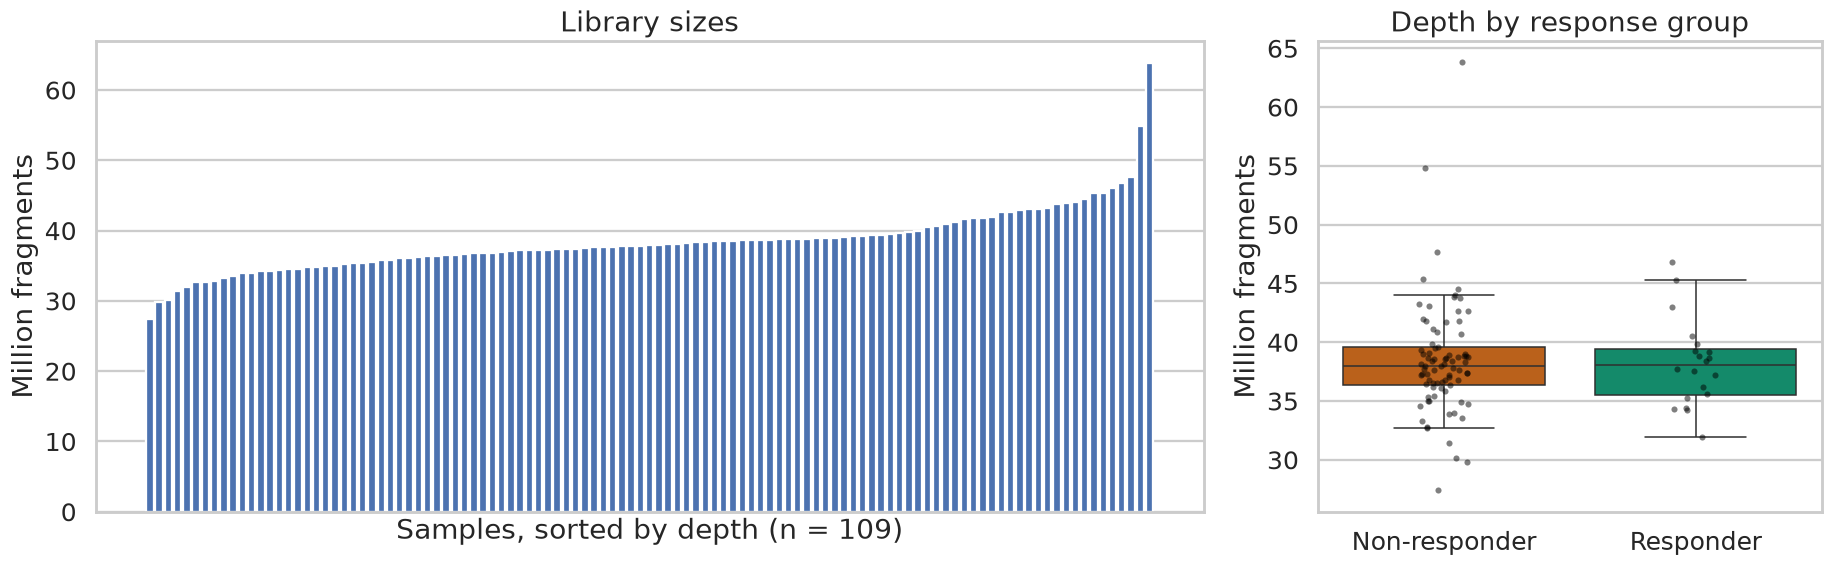

Median depth : 37.9 M   range 27.4-63.8 M
Depth vs response group, Mann-Whitney p = 0.929 (no systematic depth difference)


In [148]:
library_sizes = counts_hgnc.sum(axis=0).sort_values()
library_frame = library_sizes.rename("library_size").to_frame()
library_frame = library_frame.join(metadata.set_index("sample_id")[["timepoint", "response_group"]])
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(range(len(library_sizes)), library_sizes.values / 1e6, color=COLOR_NEUTRAL)
axes[0].set_xticks([])
axes[0].set_xlabel(f"Samples, sorted by depth (n = {len(library_sizes)})")
axes[0].set_ylabel("Million fragments")
axes[0].set_title("Library sizes")
plot_frame = library_frame.dropna(subset=["response_group"]).copy()
plot_frame["library_size_mln"] = plot_frame["library_size"] / 1e6
sns.boxplot(data=plot_frame, x="response_group", y="library_size_mln",
            hue="response_group", palette=RESPONSE_PALETTE, legend=False,
            showfliers=False, ax=axes[1])
sns.stripplot(data=plot_frame, x="response_group", y="library_size_mln",
              color="black", alpha=0.5, size=4, ax=axes[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("Million fragments")
axes[1].set_title("Depth by response group")
plt.tight_layout()
plt.show()
stat, pvalue = mannwhitneyu(
    plot_frame.loc[plot_frame["response_group"] == "Responder", "library_size"],
    plot_frame.loc[plot_frame["response_group"] == "Non-responder", "library_size"],
    alternative="two-sided",
)
print(f"Median depth : {library_sizes.median()/1e6:.1f} M   "
      f"range {library_sizes.min()/1e6:.1f}-{library_sizes.max()/1e6:.1f} M")
print(f"Depth vs response group, Mann-Whitney p = {pvalue:.3f} "
      "(no systematic depth difference)")

Genes used for PCA: 12679


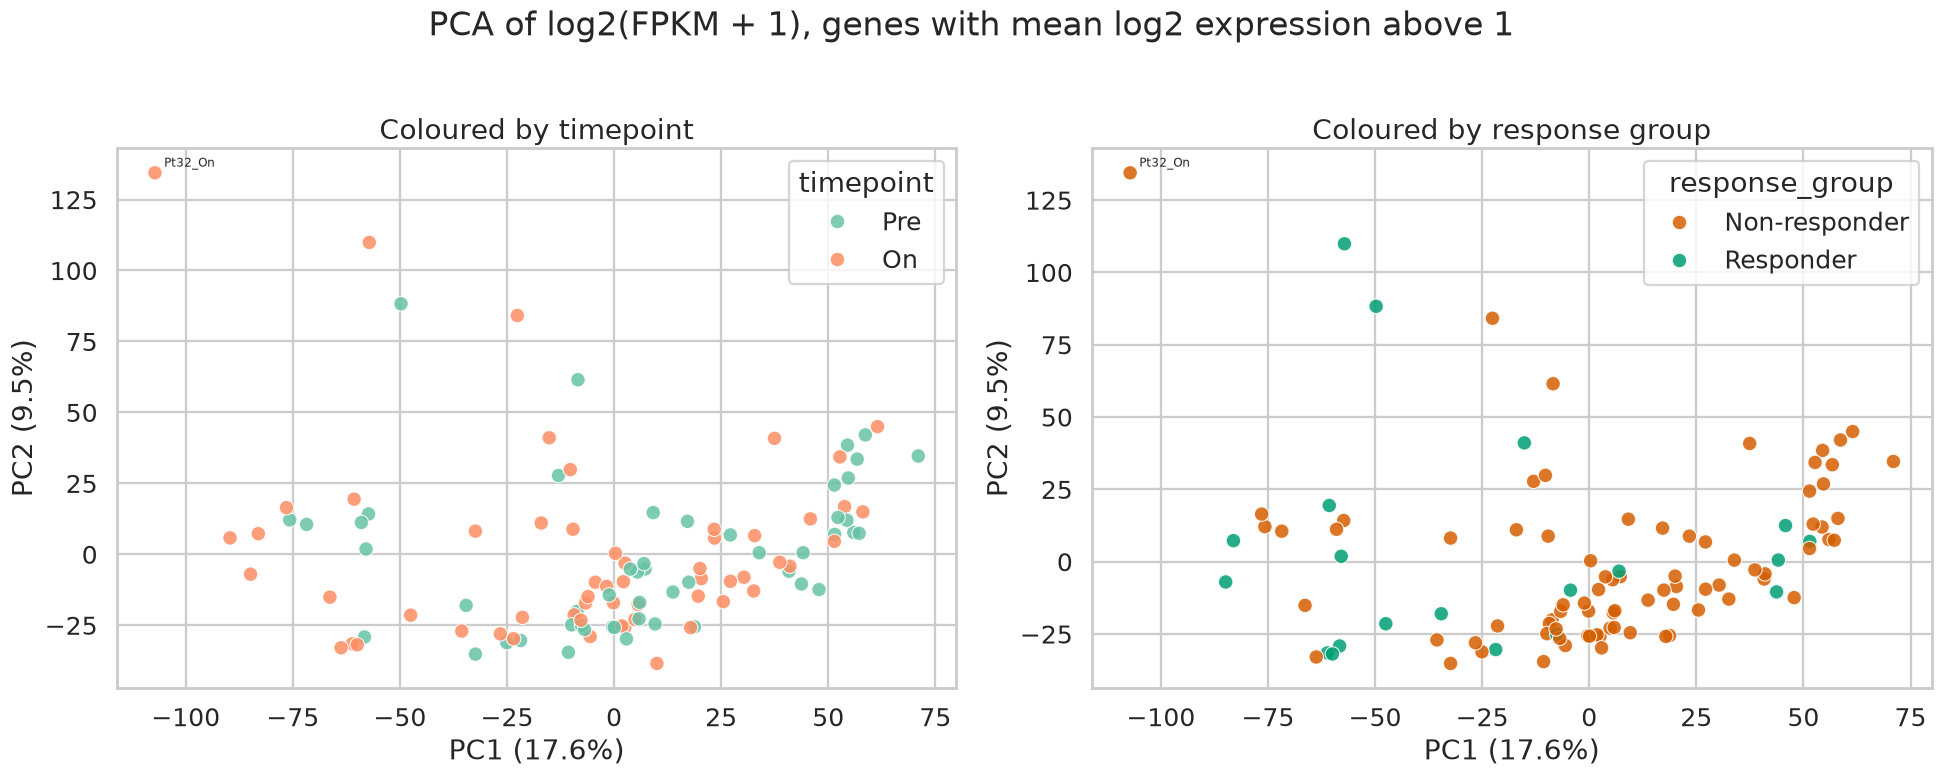

Variance explained by PC1-PC5: [17.6  9.5  5.7  5.   4.5]

Samples flagged as PCA outliers:


,patient_id,timepoint,response,PC1,PC2
Pt32_On_E9414883-5,Pt32,On,PD,-107.175834,134.426189


In [149]:
log_fpkm_all = np.log2(fpkm_hgnc + 1)
expressed = log_fpkm_all.mean(axis=1) > 1
log_fpkm_expressed = log_fpkm_all.loc[expressed]
print("Genes used for PCA:", log_fpkm_expressed.shape[0])
pca = PCA(n_components=5, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(log_fpkm_expressed.T.values)
pca_frame = metadata.set_index("sample_id").loc[log_fpkm_expressed.columns].copy()
for index in range(coordinates.shape[1]):
    pca_frame[f"PC{index + 1}"] = coordinates[:, index]
# Outliers: more than 4 standard deviations from the median on PC1 or PC2.
for component in ["PC1", "PC2"]:
    values = pca_frame[component]
    pca_frame[f"{component}_z"] = (values - values.median()) / values.std()
pca_frame["outlier"] = pca_frame["PC1_z"].abs().gt(4) | pca_frame["PC2_z"].abs().gt(4)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.scatterplot(data=pca_frame.reset_index(), x="PC1", y="PC2", hue="timepoint",
                palette="Set2", s=90, alpha=0.85, ax=axes[0])
axes[0].set_title("Coloured by timepoint")
sns.scatterplot(data=pca_frame.dropna(subset=["response_group"]).reset_index(),
                x="PC1", y="PC2", hue="response_group",
                palette=RESPONSE_PALETTE, s=90, alpha=0.85, ax=axes[1])
axes[1].set_title("Coloured by response group")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    for _, row in pca_frame[pca_frame["outlier"]].iterrows():
        ax.annotate(f"{row['patient_id']}_{row['timepoint']}",
                    (row["PC1"], row["PC2"]), fontsize=8,
                    xytext=(6, 4), textcoords="offset points")
plt.suptitle("PCA of log2(FPKM + 1), genes with mean log2 expression above 1", y=1.02)
plt.tight_layout()
plt.show()
print("Variance explained by PC1-PC5:",
      np.round(pca.explained_variance_ratio_[:5] * 100, 1))
print("\nSamples flagged as PCA outliers:")
display(pca_frame.loc[pca_frame["outlier"],
                      ["patient_id", "timepoint", "response", "PC1", "PC2"]])

### Interpretation of the PCA
Pre- and on-treatment samples are completely intermixed, and PC1 explains only about 18%
of the variance. The timepoint is therefore not a dominant source of variation, which is
expected: four weeks of therapy alters a subset of immune programmes rather than the global
transcriptome, and the biopsies differ in anatomical site and cellularity.
The original publication removed patient 3 as an RNA-seq outlier after manual review of a
PCA built on regularised-log values. That decision is adopted here for consistency with the
published analysis, and the outlier detection above is used to document which samples are
extreme in this reimplementation. Excluding a sample on the basis of the published QC is
preferable to inventing a new threshold, but it is a subjective step and is listed as such
in Block 3.

In [150]:
OUTLIER_PATIENTS = ["Pt3"]  # RNA-seq outlier reported by Riaz et al. 2017
metadata_analysis = metadata_annotated[
    ~metadata_annotated["patient_id"].isin(OUTLIER_PATIENTS)
].copy()
print("Excluded as published outliers :", OUTLIER_PATIENTS)
print("Samples retained               :", metadata_analysis.shape[0])
print("Patients retained              :", metadata_analysis["patient_id"].nunique())

Excluded as published outliers : ['Pt3']
Samples retained               : 99
Patients retained              : 57


### Tissue composition control
Metastatic melanoma is biopsied wherever an accessible lesion is found: skin, lymph node,
liver, lung, soft tissue. A liver metastasis inevitably contains surrounding hepatocytes,
whose transcriptome is extremely distinctive and expressed at very high levels.
With only nine baseline responders, a single liver biopsy in one group can dominate a
genome-wide comparison. A hepatocyte marker score is therefore computed for every baseline
sample **before** the differential expression analysis, so that any resulting signal can be
attributed correctly rather than mistaken for immunotherapy biology.

Hepatocyte markers found: 18 of 18


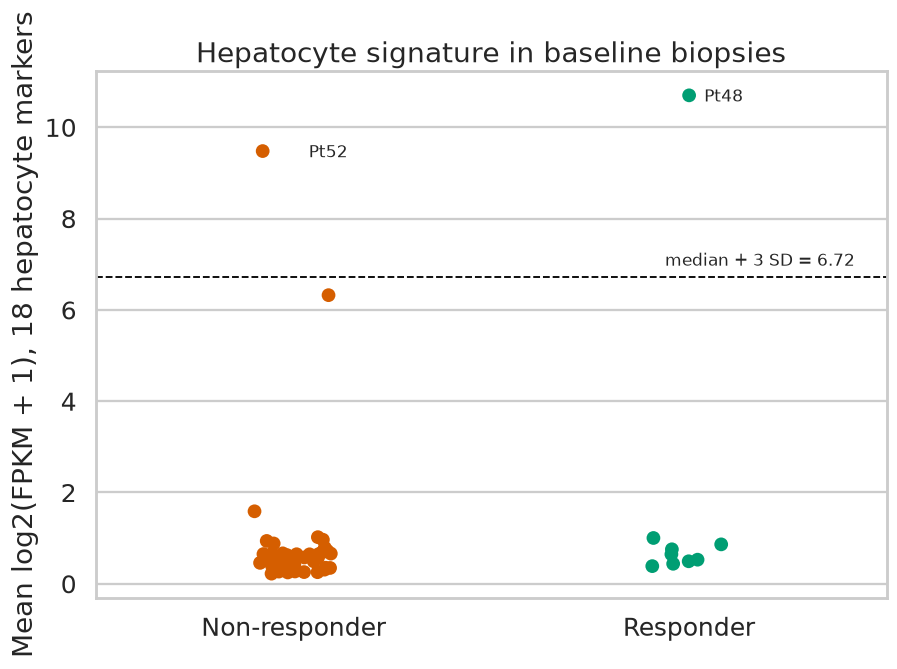

Contamination threshold : 6.717
Flagged samples         : 2


,patient_id,response_group,prior_ipi,hepatocyte_score,liver_contaminated
sample_id,,,,,
Pt48_Pre_E9047561-7,Pt48,Responder,Ipi-P,10.699716,True
Pt52_Pre_AD506075-6,Pt52,Non-responder,Ipi-P,9.478773,True
Pt82_Pre_AD823914-8,Pt82,Non-responder,Ipi-P,6.321851,False
Pt67_Pre_AD506074-6,Pt67,Non-responder,Ipi-P,1.586366,False
Pt29_Pre_AD497504-5,Pt29,Non-responder,Ipi-N,1.019688,False
Pt49_Pre_AD667851-6,Pt49,Responder,Ipi-P,1.001689,False


In [151]:
baseline_metadata = (
    metadata_analysis.query("timepoint == 'Pre'")
    .set_index("sample_id")
    .copy()
)
baseline_samples = baseline_metadata.index.tolist()
baseline_counts = counts_hgnc.loc[:, baseline_samples].copy()
baseline_fpkm = fpkm_hgnc.loc[:, baseline_samples].copy()
HEPATOCYTE_MARKERS = [
    "ALB", "APOA2", "APOB", "APOC3", "HP", "TF", "FGA", "FGB", "FGG",
    "TTR", "SERPINA1", "CYP2E1", "ITIH1", "MBL2", "LECT2", "CFHR3", "AMBP", "HPX",
]
hepatocyte_present = [g for g in HEPATOCYTE_MARKERS if g in baseline_fpkm.index]
print(f"Hepatocyte markers found: {len(hepatocyte_present)} of {len(HEPATOCYTE_MARKERS)}")
baseline_metadata["hepatocyte_score"] = (
    np.log2(baseline_fpkm.loc[hepatocyte_present] + 1).mean(axis=0)
)
threshold = (
    baseline_metadata["hepatocyte_score"].median()
    + 3 * baseline_metadata["hepatocyte_score"].std()
)
baseline_metadata["liver_contaminated"] = baseline_metadata["hepatocyte_score"] > threshold
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.stripplot(data=baseline_metadata.reset_index(), x="response_group", y="hepatocyte_score",
              hue="response_group", palette=RESPONSE_PALETTE, size=9, legend=False, ax=ax)
ax.axhline(threshold, linestyle="--", color="black", linewidth=1.2)
ax.text(1.42, threshold + 0.25, f"median + 3 SD = {threshold:.2f}",
        ha="right", fontsize=11)
for sample_id, row in baseline_metadata[baseline_metadata["liver_contaminated"]].iterrows():
    x = 0 if row["response_group"] == "Non-responder" else 1
    ax.annotate(row["patient_id"], (x, row["hepatocyte_score"]),
                xytext=(10, -4), textcoords="offset points", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Mean log2(FPKM + 1), 18 hepatocyte markers")
ax.set_title("Hepatocyte signature in baseline biopsies")
plt.tight_layout()
plt.show()
print(f"Contamination threshold : {threshold:.3f}")
print(f"Flagged samples         : {int(baseline_metadata['liver_contaminated'].sum())}")
display(
    baseline_metadata.sort_values("hepatocyte_score", ascending=False)
    .head(6)[["patient_id", "response_group", "prior_ipi", "hepatocyte_score",
              "liver_contaminated"]]
)

BASELINE ANALYSIS COHORT
Samples : 50



prior_ipi,Ipi-N,Ipi-P,All
response_group,,,
Non-responder,19,22,41
Responder,5,4,9
All,24,26,50



Best overall response:
response
PD    23
SD    16
PR     6
CR     3
NE     2


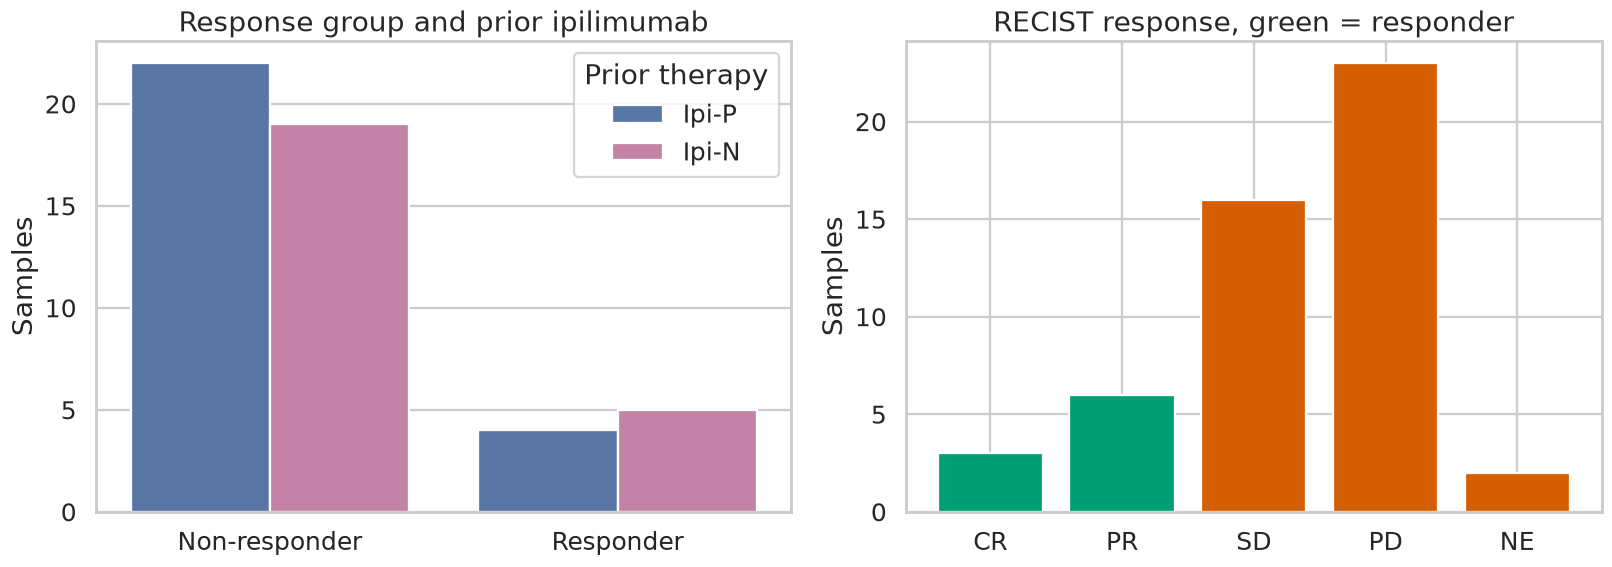


The cohort is balanced for prior ipilimumab exposure, but only 9 responders are
available. This is the single most important constraint on all of Block 1.


In [152]:
print("BASELINE ANALYSIS COHORT")
print("=" * 46)
print("Samples :", baseline_metadata.shape[0])
print()
display(pd.crosstab(baseline_metadata["response_group"],
                    baseline_metadata["prior_ipi"], margins=True))
print("\nBest overall response:")
print(baseline_metadata["response"].value_counts().to_string())
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.countplot(data=baseline_metadata.reset_index(), x="response_group", hue="prior_ipi",
              palette=[COLOR_NEUTRAL, "#CC79A7"], ax=axes[0])
axes[0].set_title("Response group and prior ipilimumab")
axes[0].set_xlabel("")
axes[0].set_ylabel("Samples")
axes[0].legend(title="Prior therapy")
order = ["CR", "PR", "SD", "PD", "NE"]
counts = baseline_metadata["response"].value_counts().reindex(order).fillna(0)
colors = [COLOR_RESPONDER, COLOR_RESPONDER, COLOR_NONRESPONDER,
          COLOR_NONRESPONDER, COLOR_NONRESPONDER]
axes[1].bar(order, counts.values, color=colors)
axes[1].set_title("RECIST response, green = responder")
axes[1].set_ylabel("Samples")
plt.tight_layout()
plt.show()
print("\nThe cohort is balanced for prior ipilimumab exposure, but only 9 responders are")
print("available. This is the single most important constraint on all of Block 1.")

# Block 1. Baseline biomarkers of response to nivolumab
Pre-treatment samples only. The model is

**expression ~ prior_ipi + response_group**

Prior ipilimumab exposure enters as a covariate because anti-CTLA-4 pretreatment reshapes
the immune state of the microenvironment, and the publication showed that the predictive
value of baseline features differs between the Ipi-naive and Ipi-progressed cohorts.
### Why two extra safeguards are needed
With 9 responders and 41 non-responders, the standard workflow produces artefacts:
1. A gene expressed in only one or two samples yields an enormous apparent fold change,
   because the negative-binomial dispersion is underestimated at near-zero counts.
2. That single sample can be a liver biopsy, in which case the "biomarker" is hepatocyte
   RNA.
Accordingly, genes must be **detected in a minimum number of samples in both groups**, and
fold changes are **shrunk**. Shrinkage in PyDESeq2 does not recompute p-values, so genes
whose estimate collapses under shrinkage are explicitly flagged as unstable and excluded
from biological interpretation.

In [153]:
group_labels = baseline_metadata.loc[baseline_counts.columns, "response_group"]
responder_columns = group_labels[group_labels == "Responder"].index
nonresponder_columns = group_labels[group_labels == "Non-responder"].index
MIN_COUNT = 10
MIN_RESPONDERS = 3        # of 9
MIN_NONRESPONDERS = 8     # of 41
detected_responders = (baseline_counts[responder_columns] >= MIN_COUNT).sum(axis=1)
detected_nonresponders = (baseline_counts[nonresponder_columns] >= MIN_COUNT).sum(axis=1)
gene_filter = (
    (detected_responders >= MIN_RESPONDERS)
    & (detected_nonresponders >= MIN_NONRESPONDERS)
)
de_counts = baseline_counts.loc[gene_filter].T.astype(int)
de_metadata = baseline_metadata.loc[de_counts.index, ["response_group", "prior_ipi"]].copy()
de_metadata["response_group"] = pd.Categorical(
    de_metadata["response_group"], categories=["Non-responder", "Responder"]
)
de_metadata["prior_ipi"] = pd.Categorical(
    de_metadata["prior_ipi"], categories=["Ipi-N", "Ipi-P"]
)
print(f"Filter: at least {MIN_COUNT} counts in at least {MIN_RESPONDERS}/9 responders "
      f"and {MIN_NONRESPONDERS}/41 non-responders")
print("Genes before :", baseline_counts.shape[0])
print("Genes after  :", de_counts.shape[1])
print("Removed      :", baseline_counts.shape[0] - de_counts.shape[1])
print("\nDesign table:")
display(de_metadata.value_counts().to_frame("n"))

Filter: at least 10 counts in at least 3/9 responders and 8/41 non-responders
Genes before : 22047
Genes after  : 16592
Removed      : 5455

Design table:


n
response_group prior_ipi    
Non-responder  Ipi-P      22
               Ipi-N      19
Responder      Ipi-N       5
               Ipi-P       4

In [154]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
dds = DeseqDataSet(
    counts=de_counts,
    metadata=de_metadata,
    design="~ prior_ipi + response_group",
    refit_cooks=True,
)
dds.deseq2()
stat_res = DeseqStats(dds, contrast=["response_group", "Responder", "Non-responder"])
stat_res.summary()
unshrunk = stat_res.results_df.copy()
print("\nUnshrunken |log2FC| : max =", round(unshrunk["log2FoldChange"].abs().max(), 1))

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.03 seconds.

Fitting dispersions...
... done in 1.26 seconds.

Fitting dispersion trend curve...
... done in 0.34 seconds.

Fitting MAP dispersions...
... done in 1.23 seconds.

Fitting LFCs...
... done in 1.26 seconds.

Calculating cook's distance...
... done in 0.05 seconds.

Replacing 1154 outlier genes.

Fitting dispersions...
... done in 0.38 seconds.

Fitting MAP dispersions...
... done in 0.39 seconds.

Fitting LFCs...
... done in 0.46 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: response_group Responder vs Non-responder
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
symbol                                                                        
A1BG        579.203816        2.317304  0.514890  4.500577       NaN       NaN
A1BG-AS1     82.107438       -0.040091  0.275018 -0.145776  0.884098  0.978863
A2M       51012.147657        0.842648  0.489012  1.723163  0.084859  0.525967
A2M-AS1     138.830684       -0.349511  0.427634 -0.817314  0.413749  0.824134
A4GALT      208.486631        0.287450  0.591100  0.486298  0.626756  0.912834
...                ...             ...       ...       ...       ...       ...
ZYG11A       20.922527        2.393738  1.131324  2.115873  0.034356  0.380166
ZYG11B     2549.589968        0.090396  0.196143  0.460870  0.644892  0.916764
ZYX        4761.941404        0.155701  0.324667  0.479572  0.631531  0.914368
ZZEF1      2863.572467        0.287626  0.191367  1

... done in 1.45 seconds.



In [155]:
design_columns = list(dds.obsm["design_matrix"].columns)
print("Design matrix columns:", design_columns)
coefficient = [c for c in design_columns if "response_group" in c][0]
print("Shrinking coefficient:", coefficient)
stat_res.lfc_shrink(coeff=coefficient)
de_results = stat_res.results_df.copy()
de_results.index.name = "symbol"
de_results = (
    de_results.reset_index()
    .rename(columns={"log2FoldChange": "log2FC", "padj": "FDR"})
)
de_results["log2FC_unshrunk"] = (
    unshrunk["log2FoldChange"].reindex(de_results["symbol"]).to_numpy()
)
de_results["hepatocyte_marker"] = de_results["symbol"].isin(HEPATOCYTE_MARKERS)
# A shrunken estimate retaining less than 20% of its unshrunken magnitude means the
# effect was supported by too few observations to be estimated reliably.
de_results["shrinkage_retained"] = (
    de_results["log2FC"].abs()
    / de_results["log2FC_unshrunk"].abs().replace(0, np.nan)
)
de_results["unstable_estimate"] = de_results["shrinkage_retained"] < 0.20
de_results["direction"] = np.where(
    de_results["log2FC"] > 0, "Higher in responders", "Higher in non-responders"
)
de_results = de_results.sort_values("FDR")
de_reliable = de_results[~de_results["unstable_estimate"]].copy()
print("\nMaximum |log2FC| after shrinkage :", round(de_results["log2FC"].abs().max(), 2))
print("Genes with strongly shrinkage-sensitive estimates    :", int(de_results["unstable_estimate"].sum()))
print("Unstable among 30 lowest FDR     :",
      int(de_results.nsmallest(30, "FDR")["unstable_estimate"].sum()))
print("Genes retained for interpretation:", de_reliable.shape[0])
print("\nExamples of strongly shrinkage-sensitive estimates (large raw effect, collapses on shrinkage):")
display(
    de_results[de_results["unstable_estimate"]]
    .nsmallest(8, "FDR")[["symbol", "log2FC", "log2FC_unshrunk", "FDR",
                          "hepatocyte_marker"]]
)

Fitting MAP LFCs...


Design matrix columns: ['Intercept', 'prior_ipi[T.Ipi-P]', 'response_group[T.Responder]']
Shrinking coefficient: response_group[T.Responder]
Shrunk log2 fold change & Wald test p-value: response_group[T.Responder]
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
symbol                                                                        
A1BG        579.203816        1.250524  0.550896  4.500577       NaN       NaN
A1BG-AS1     82.107438       -0.004764  0.102684 -0.145776  0.884098  0.978863
A2M       51012.147657        0.046495  0.135161  1.723163  0.084859  0.525967
A2M-AS1     138.830684       -0.017801  0.108797 -0.817314  0.413749  0.824134
A4GALT      208.486631        0.008873  0.114351  0.486298  0.626756  0.912834
...                ...             ...       ...       ...       ...       ...
ZYG11A       20.922527        0.025860  0.129736  2.115873  0.034356  0.380166
ZYG11B     2549.589968        0.019719  0.098075  0.460870  0.644892  0.916

... done in 1.50 seconds.



,symbol,log2FC,log2FC_unshrunk,FDR,hepatocyte_marker
6651,ITIH1,0.003544,32.420324,2.997336e-12,True
2521,CFHR3,0.002937,25.256890,1.521201e-05,True
12995,SLC9A3,-0.032880,-3.740715,7.981362e-04,False
4870,FGG,0.014332,7.193587,1.064065e-03,True
7215,LEP,0.005421,4.282795,1.930700e-03,False
41,ABCB11,0.022169,5.950047,1.930700e-03,False
12154,S100A2,-0.022198,-4.358598,2.816259e-03,False
21,AATBC,-0.045807,-2.613817,1.060002e-02,False


In [156]:
FDR_CUTOFF = 0.20
LFC_CUTOFF = 1.0
de_significant = de_reliable[
    (de_reliable["FDR"] < FDR_CUTOFF) & (de_reliable["log2FC"].abs() >= LFC_CUTOFF)
].copy()
print(f"Significant genes (FDR < {FDR_CUTOFF}, |log2FC| >= {LFC_CUTOFF}) : "
      f"{de_significant.shape[0]}")
print(de_significant["direction"].value_counts().to_string())
print("Hepatocyte markers remaining :",
      int(de_significant["hepatocyte_marker"].sum()))
display(
    de_significant.head(30)[
        ["symbol", "log2FC", "log2FC_unshrunk", "baseMean", "pvalue", "FDR", "direction"]
    ].round(4)
)
de_results.to_csv(DATA_DIR / "block1_DESeq2_all_genes.csv", index=False)
de_significant.to_csv(DATA_DIR / "block1_DESeq2_significant_genes.csv", index=False)
print("\nTables written to", DATA_DIR)

Significant genes (FDR < 0.2, |log2FC| >= 1.0) : 171
direction
Higher in responders        166
Higher in non-responders      5
Hepatocyte markers remaining : 0


,symbol,log2FC,log2FC_unshrunk,baseMean,pvalue,FDR,direction
5591,GPR88,3.8497,4.9819,66.8005,0.0000,0.0000,Higher in responders
4553,FAM151A,3.7443,4.0063,50.6735,0.0000,0.0000,Higher in responders
2754,CLLU1,3.9625,4.2552,68.0412,0.0000,0.0000,Higher in responders
1942,CBLN2,4.6280,5.2785,70.4451,0.0000,0.0026,Higher in responders
9178,NELL2,2.0178,2.2285,419.5883,0.0000,0.0026,Higher in responders
14613,TNFRSF13C,2.6993,3.0379,54.7062,0.0000,0.0069,Higher in responders
8459,MLC1,3.0978,3.4463,73.8564,0.0000,0.0071,Higher in responders
3717,DNAH7,2.4747,2.8662,71.0917,0.0000,0.0072,Higher in responders
12607,SHISAL2A,2.7175,3.0655,33.3832,0.0000,0.0101,Higher in responders
9788,P2RX5,2.6968,3.0661,97.7693,0.0000,0.0106,Higher in responders



Tables written to data_GSE91061


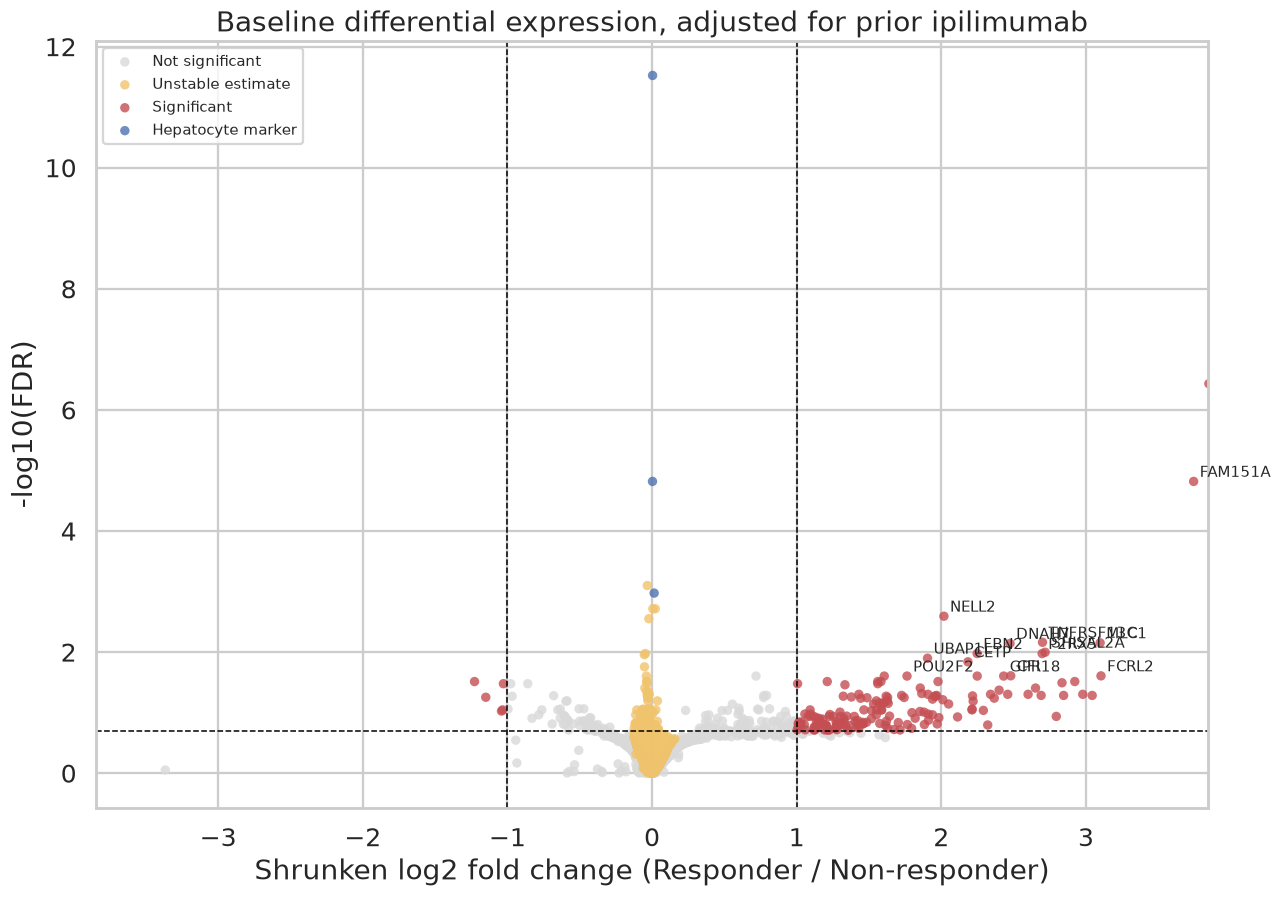

In [157]:
plot_de = de_results.dropna(subset=["FDR", "log2FC"]).copy()
plot_de["minus_log10_fdr"] = -np.log10(plot_de["FDR"].clip(lower=1e-300))
plot_de["category"] = np.select(
    [
        plot_de["hepatocyte_marker"],
        plot_de["unstable_estimate"],
        (plot_de["FDR"] < FDR_CUTOFF) & (plot_de["log2FC"].abs() >= LFC_CUTOFF),
    ],
    ["Hepatocyte marker", "Unstable estimate", "Significant"],
    default="Not significant",
)
palette = {
    "Not significant": "#D9D9D9",
    "Unstable estimate": "#F0C36D",
    "Significant": "#C44E52",
    "Hepatocyte marker": COLOR_NEUTRAL,
}
fig, ax = plt.subplots(figsize=(12, 8.5))
for category in ["Not significant", "Unstable estimate", "Significant", "Hepatocyte marker"]:
    subset = plot_de[plot_de["category"] == category]
    ax.scatter(subset["log2FC"], subset["minus_log10_fdr"],
               s=38, alpha=0.8, color=palette[category], label=category,
               edgecolors="none")
ax.axvline(-LFC_CUTOFF, linestyle="--", color="black", linewidth=1)
ax.axvline(LFC_CUTOFF, linestyle="--", color="black", linewidth=1)
ax.axhline(-np.log10(FDR_CUTOFF), linestyle="--", color="black", linewidth=1)
for _, row in de_significant.head(18).iterrows():
    ax.annotate(row["symbol"],
                (row["log2FC"], -np.log10(max(row["FDR"], 1e-300))),
                fontsize=9.5, xytext=(4, 3), textcoords="offset points")
limit = max(2.5, plot_de["log2FC"].abs().quantile(0.9995) + 0.7)
ax.set_xlim(-limit, limit)
ax.set_xlabel("Shrunken log2 fold change (Responder / Non-responder)")
ax.set_ylabel("-log10(FDR)")
ax.set_title("Baseline differential expression, adjusted for prior ipilimumab")
ax.legend(loc="upper left", fontsize=10, frameon=True)
plt.tight_layout()
plt.show()

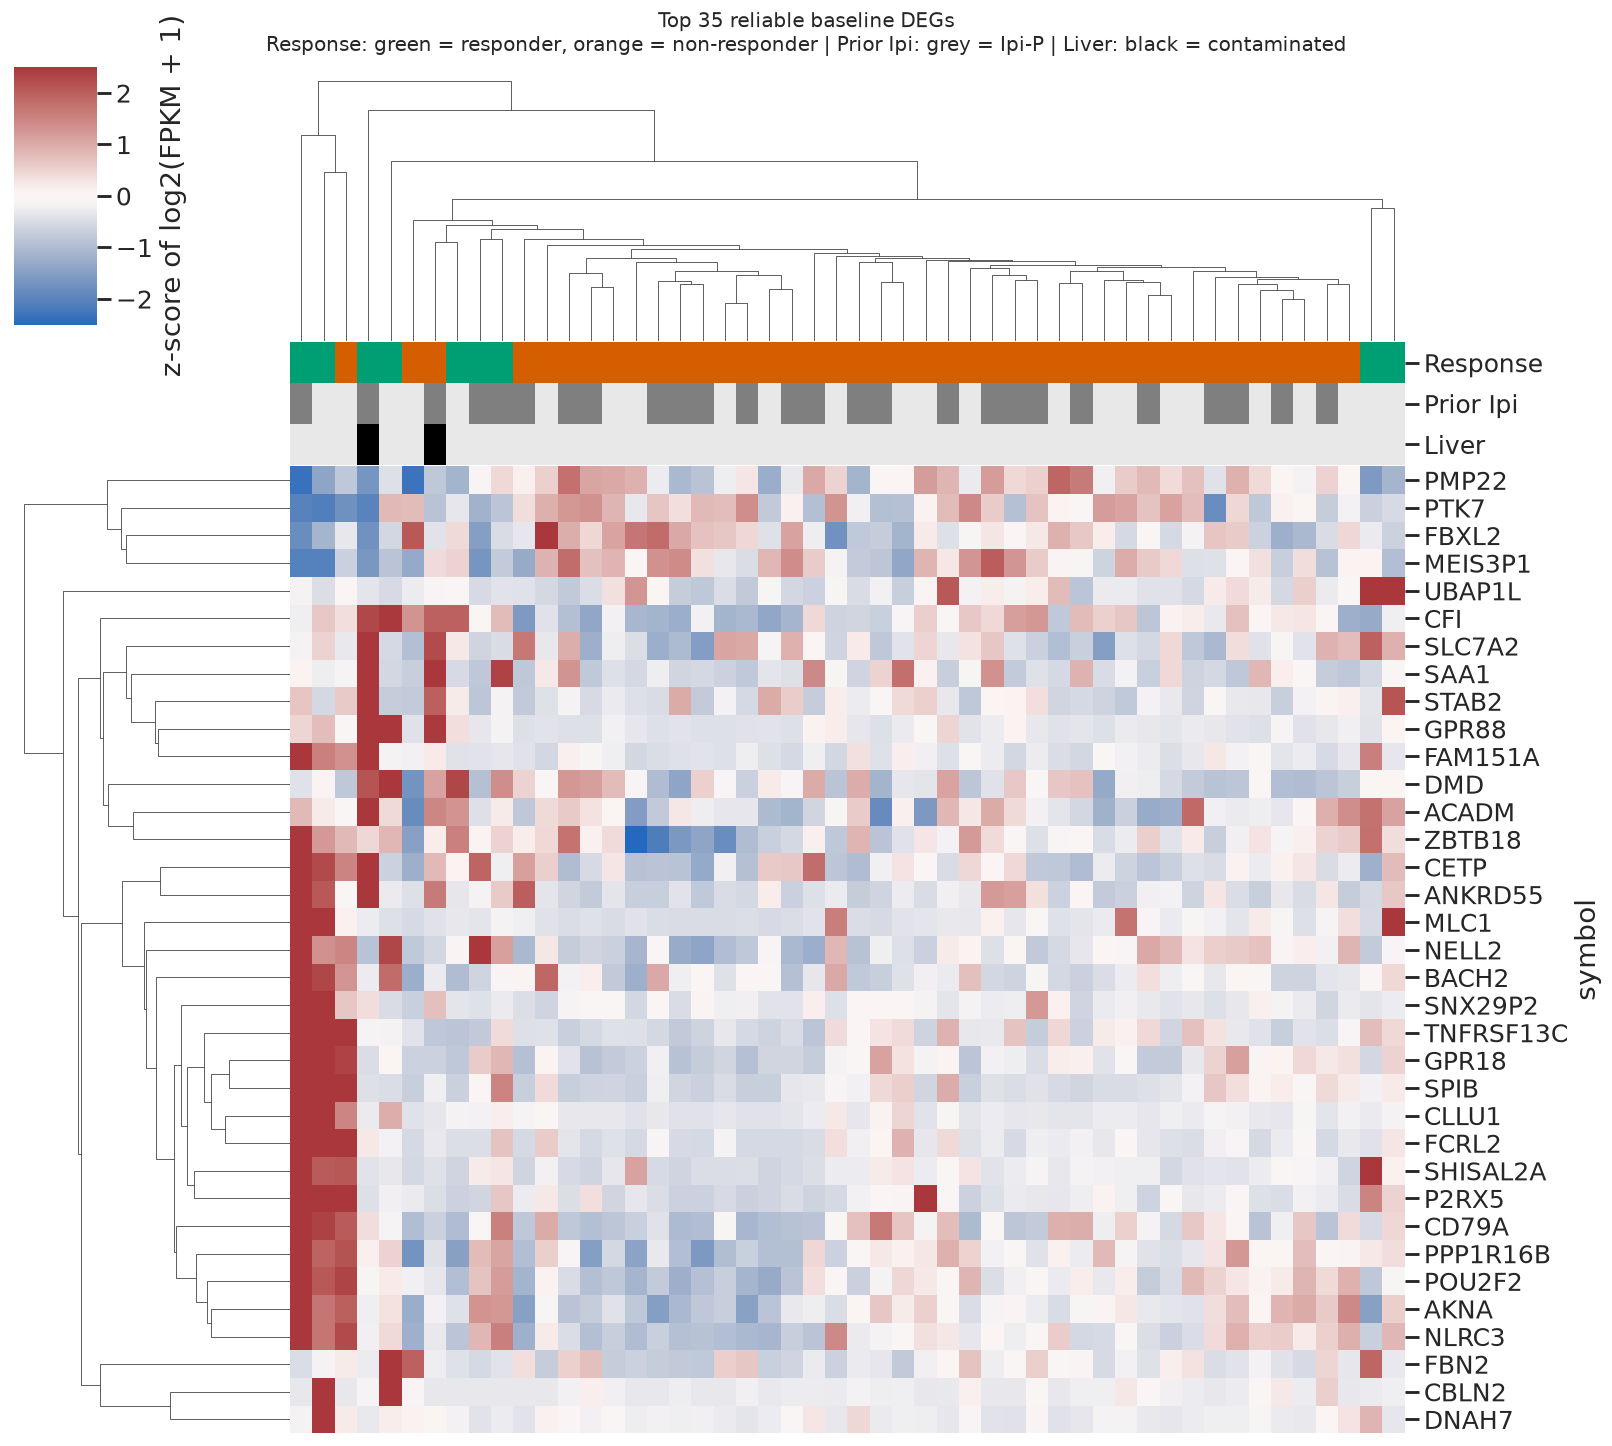

In [158]:
top_genes = de_reliable.dropna(subset=["FDR"]).head(35)["symbol"].tolist()
heat = np.log2(baseline_fpkm.loc[top_genes] + 1)
heat = heat.sub(heat.mean(axis=1), axis=0).div(heat.std(axis=1).replace(0, np.nan), axis=0)
heat = heat.dropna(how="all")
col_colors = pd.DataFrame({
    "Response": baseline_metadata.loc[heat.columns, "response_group"].map(RESPONSE_PALETTE),
    "Prior Ipi": baseline_metadata.loc[heat.columns, "prior_ipi"].map(
        {"Ipi-N": "#E8E8E8", "Ipi-P": "#7F7F7F"}),
    "Liver": baseline_metadata.loc[heat.columns, "liver_contaminated"].map(
        {True: "#000000", False: "#E8E8E8"}),
})
grid = sns.clustermap(
    heat, cmap="vlag", center=0, vmin=-2.5, vmax=2.5,
    col_colors=col_colors, figsize=(15, 13),
    xticklabels=False, yticklabels=True,
    cbar_kws={"label": "z-score of log2(FPKM + 1)"},
)
grid.fig.suptitle(
    "Top 35 reliable baseline DEGs\n"
    "Response: green = responder, orange = non-responder | "
    "Prior Ipi: grey = Ipi-P | Liver: black = contaminated",
    y=1.02, fontsize=13,
)
plt.show()

### Hypothesis-driven analysis of canonical markers
The genome-wide screen is underpowered. Testing a pre-specified panel of genes with an
established mechanistic link to PD-1 blockade is statistically far more efficient, because
it reduces the multiple-testing burden from roughly seventeen thousand tests to twenty-six.

In [159]:
BIOMARKER_PANEL = {
    "T cell infiltration": ["CD8A", "CD8B", "CD3D", "CD3E", "CD2"],
    "Cytolytic effectors": ["GZMA", "GZMB", "PRF1", "NKG7", "GNLY"],
    "Interferon gamma axis": ["IFNG", "CXCL9", "CXCL10", "CXCL13", "IDO1", "STAT1", "IRF1"],
    "Antigen presentation": ["HLA-DRA", "B2M", "TAP1"],
    "Immune checkpoints": ["PDCD1", "CD274", "CTLA4", "LAG3", "TIGIT", "HAVCR2"],
}
panel_genes = [g for genes in BIOMARKER_PANEL.values() for g in genes]
gene_to_module = {g: m for m, genes in BIOMARKER_PANEL.items() for g in genes}
available = [g for g in panel_genes if g in baseline_fpkm.index]
print("Missing from the matrix:", sorted(set(panel_genes) - set(available)) or "none")
panel_expression = (
    np.log2(baseline_fpkm.loc[available] + 1).T
    .join(baseline_metadata[["response_group", "prior_ipi"]])
)
records = []
for gene in available:
    resp = panel_expression.loc[panel_expression["response_group"] == "Responder", gene]
    nonresp = panel_expression.loc[panel_expression["response_group"] == "Non-responder", gene]
    stat, pvalue = mannwhitneyu(resp, nonresp, alternative="two-sided")
    # Rank-biserial correlation as an effect size.
    effect = 2 * stat / (len(resp) * len(nonresp)) - 1
    records.append({
        "gene": gene, "module": gene_to_module[gene],
        "median_responders": resp.median(),
        "median_non_responders": nonresp.median(),
        "delta_median": resp.median() - nonresp.median(),
        "rank_biserial_r": effect,
        "pvalue": pvalue,
    })
panel_tests = pd.DataFrame(records)
panel_tests["FDR"] = multipletests(panel_tests["pvalue"], method="fdr_bh")[1]
panel_tests = panel_tests.sort_values("pvalue")
display(panel_tests.round(4))
panel_tests.to_csv(DATA_DIR / "block1_biomarker_panel_tests.csv", index=False)
print(f"\nNominally significant (p < 0.05) : "
      f"{int((panel_tests['pvalue'] < 0.05).sum())} of {panel_tests.shape[0]}")
print(f"Significant after FDR correction : "
      f"{int((panel_tests['FDR'] < 0.05).sum())}")
print(f"Genes with a higher median in responders : "
      f"{int((panel_tests['delta_median'] > 0).sum())} of {panel_tests.shape[0]}")

Missing from the matrix: none


,gene,module,median_responders,median_non_responders,delta_median,rank_biserial_r,pvalue,FDR
22,CTLA4,Immune checkpoints,2.5504,1.2012,1.3492,0.4905,0.0230,0.2073
24,TIGIT,Immune checkpoints,3.3357,1.4276,1.9081,0.4526,0.0361,0.2073
14,IDO1,Interferon gamma axis,3.8257,2.0420,1.7837,0.4363,0.0434,0.2073
3,CD3E,T cell infiltration,3.9359,2.4929,1.4430,0.4309,0.0461,0.2073
0,CD8A,T cell infiltration,4.0632,2.2338,1.8295,0.4146,0.0550,0.2073
2,CD3D,T cell infiltration,4.2932,2.8412,1.4520,0.3875,0.0730,0.2073
4,CD2,T cell infiltration,4.3790,2.6878,1.6912,0.3875,0.0730,0.2073
20,PDCD1,Immune checkpoints,1.4603,0.5715,0.8888,0.3767,0.0814,0.2073
13,CXCL13,Interferon gamma axis,3.6283,2.6065,1.0218,0.3713,0.0859,0.2073
11,CXCL9,Interferon gamma axis,6.4172,4.5578,1.8593,0.3659,0.0907,0.2073



Nominally significant (p < 0.05) : 4 of 26
Significant after FDR correction : 0
Genes with a higher median in responders : 26 of 26


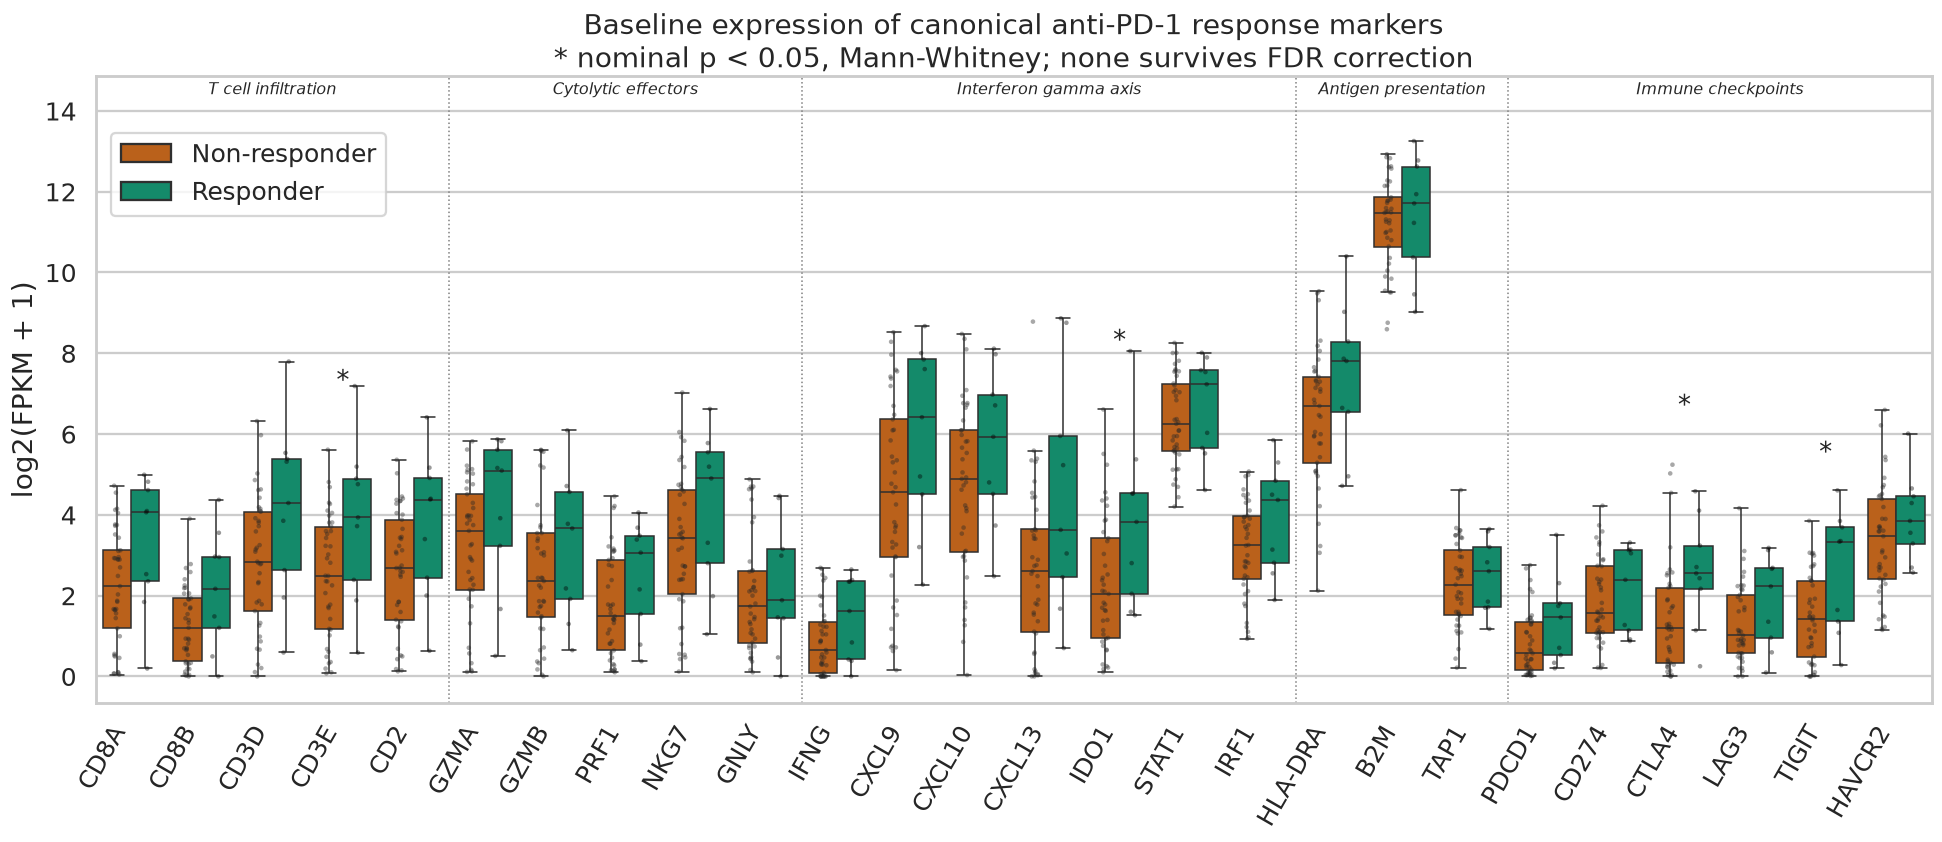

In [160]:
panel_long = panel_expression.melt(
    id_vars=["response_group", "prior_ipi"], var_name="gene", value_name="log2_FPKM"
)
panel_long["module"] = panel_long["gene"].map(gene_to_module)
gene_order = [g for m in BIOMARKER_PANEL for g in BIOMARKER_PANEL[m] if g in available]
fig, ax = plt.subplots(figsize=(18, 8))
sns.boxplot(data=panel_long, x="gene", y="log2_FPKM", hue="response_group",
            order=gene_order, palette=RESPONSE_PALETTE, showfliers=False, ax=ax)
sns.stripplot(data=panel_long, x="gene", y="log2_FPKM", hue="response_group",
              order=gene_order, dodge=True, color="black", alpha=0.4, size=3,
              legend=False, ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="",
          bbox_to_anchor=(0.165, 0.93),
          ncol=1, frameon=True)
y_top = panel_long["log2_FPKM"].max()
ax.set_ylim(top=y_top + 1.6)
pvalues = panel_tests.set_index("gene")["pvalue"]
for position, gene in enumerate(gene_order):
    if pvalues.get(gene, 1) < 0.05:
        y_max = panel_long.loc[panel_long["gene"] == gene, "log2_FPKM"].quantile(0.98)
        ax.text(position, y_max + 1.5, "*", ha="center", fontsize=17)
# Module separators.
boundary = 0
for module, genes in BIOMARKER_PANEL.items():
    present = [g for g in genes if g in available]
    boundary += len(present)
    if boundary < len(gene_order):
        ax.axvline(boundary - 0.5, color="grey", linewidth=1, linestyle=":")
    ax.text(boundary - len(present) / 2 - 0.5, y_top + 1.16, module,
            ha="center", fontsize=10.5, style="italic")
ax.set_xlabel("")
ax.set_ylabel("log2(FPKM + 1)")
ax.set_title("Baseline expression of canonical anti-PD-1 response markers\n"
             "* nominal p < 0.05, Mann-Whitney; none survives FDR correction")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

### Composite scores and external validation
Single genes are noisy. Two composite scores are computed and compared between groups:
- **Cytolytic activity**, the geometric mean of GZMA and PRF1 (Rooney et al. 2015), which
  is the definition used in the original study.
- **Interferon gamma signature**, the mean of log2 expression across the IFN-gamma axis genes.
The cytolytic score computed here is additionally correlated with the **published score
supplied with GSE91061 and with Table S2**, which validates the entire upstream pipeline:
identifier mapping, aggregation and normalisation.

In [161]:
composite = baseline_metadata[["patient_id", "response_group", "prior_ipi",
                               "cytolytic_score_published", "mutation_load",
                               "neoantigen_load"]].copy()
composite["cytolytic_score"] = np.log2(
    np.sqrt((baseline_fpkm.loc["GZMA"] + 1) * (baseline_fpkm.loc["PRF1"] + 1))
).loc[composite.index]
ifng_axis = [g for g in BIOMARKER_PANEL["Interferon gamma axis"] if g in baseline_fpkm.index]
composite["ifng_signature"] = (
    np.log2(baseline_fpkm.loc[ifng_axis] + 1).mean(axis=0).loc[composite.index]
)
tcell_axis = [g for g in BIOMARKER_PANEL["T cell infiltration"] if g in baseline_fpkm.index]
composite["tcell_signature"] = (
    np.log2(baseline_fpkm.loc[tcell_axis] + 1).mean(axis=0).loc[composite.index]
)
# External validation against the published cytolytic score.
validation = composite.dropna(subset=["cytolytic_score_published"])
rho, p_rho = spearmanr(validation["cytolytic_score"],
                       np.log2(validation["cytolytic_score_published"] + 1))
print(f"Own score vs published score (Table S2): "
      f"Spearman rho = {rho:.3f}, p = {p_rho:.2e}, n = {validation.shape[0]}")
results = []
for score in ["cytolytic_score", "ifng_signature", "tcell_signature"]:
    resp = composite.loc[composite["response_group"] == "Responder", score]
    nonresp = composite.loc[composite["response_group"] == "Non-responder", score]
    stat, pvalue = mannwhitneyu(resp, nonresp, alternative="two-sided")
    results.append({"score": score, "median_responders": resp.median(),
                    "median_non_responders": nonresp.median(), "pvalue": pvalue})
    for ipi in ["Ipi-N", "Ipi-P"]:
        sub = composite[composite["prior_ipi"] == ipi]
        r = sub.loc[sub["response_group"] == "Responder", score]
        n = sub.loc[sub["response_group"] == "Non-responder", score]
        st, pv = mannwhitneyu(r, n, alternative="two-sided")
        results.append({"score": f"{score} [{ipi}]", "median_responders": r.median(),
                        "median_non_responders": n.median(), "pvalue": pv})
composite_tests = pd.DataFrame(results)
composite_tests["delta"] = (composite_tests["median_responders"]
                            - composite_tests["median_non_responders"])
display(composite_tests.round(4))

Own score vs published score (Table S2): Spearman rho = 0.992, p = 2.34e-45, n = 50


,score,median_responders,median_non_responders,pvalue,delta
0,cytolytic_score,4.1117,2.6011,0.1116,1.5107
1,cytolytic_score [Ipi-N],3.0352,2.7849,1.0000,0.2503
2,cytolytic_score [Ipi-P],4.6618,2.2324,0.0260,2.4293
3,ifng_signature,4.8637,3.4903,0.0860,1.3733
4,ifng_signature [Ipi-N],3.3978,3.4903,0.8906,-0.0925
5,ifng_signature [Ipi-P],5.6527,3.6118,0.0395,2.0409
6,tcell_signature,3.7743,2.2301,0.0489,1.5442
7,tcell_signature [Ipi-N],2.9980,2.5354,0.6793,0.4626
8,tcell_signature [Ipi-P],4.6032,2.1737,0.0162,2.4295


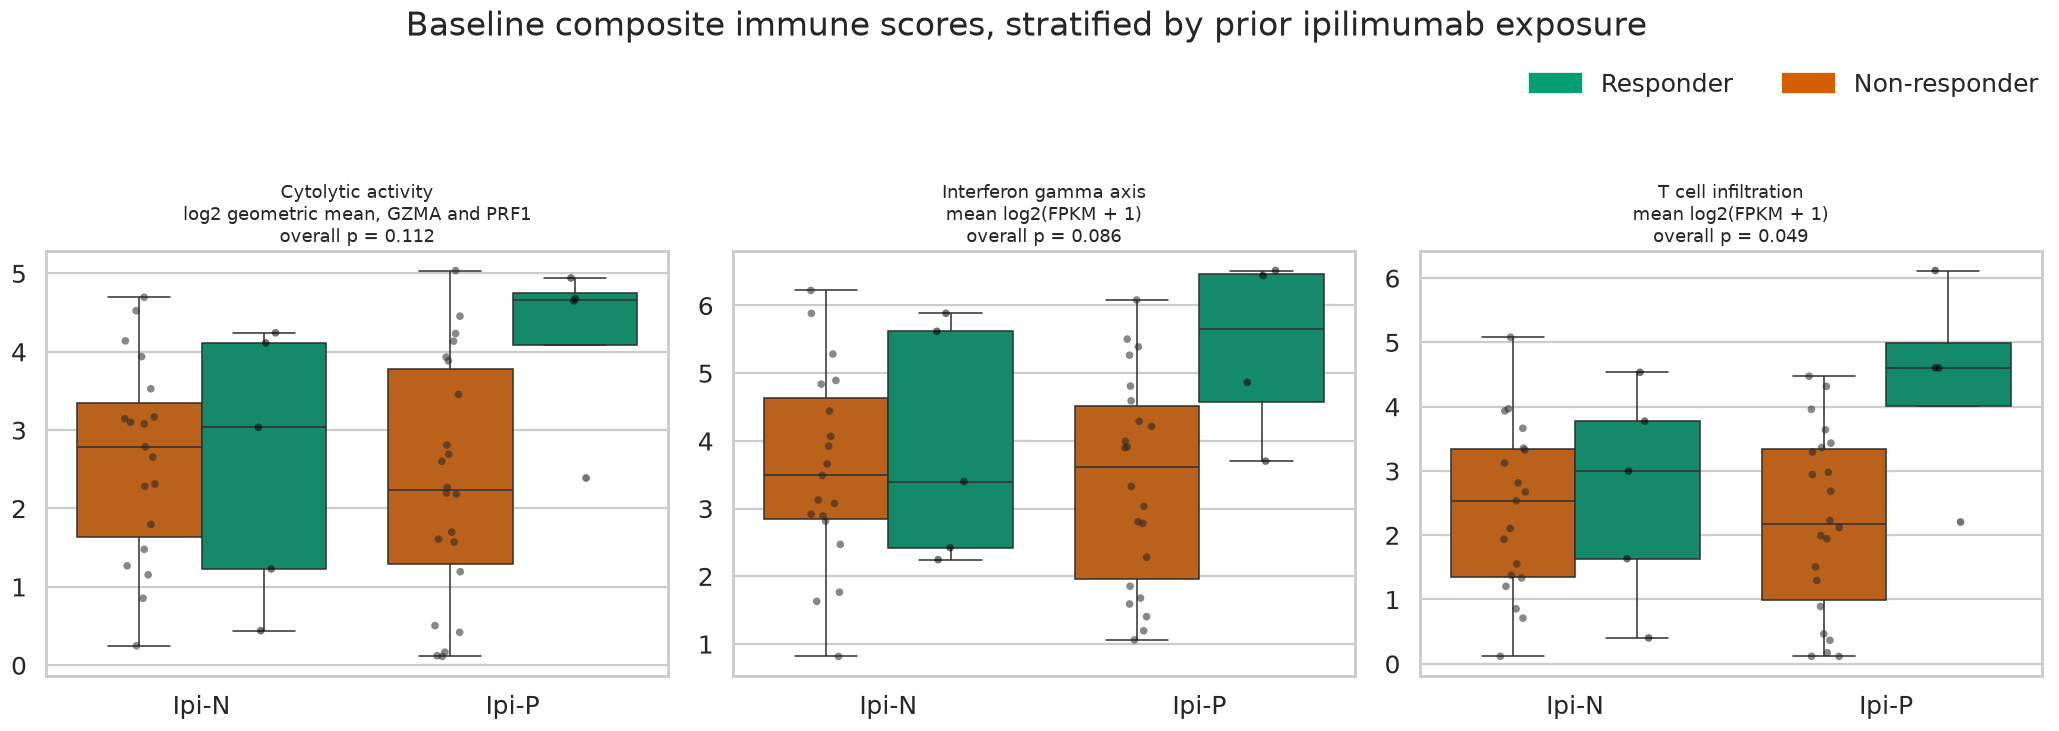

In [162]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
score_titles = {
    "cytolytic_score": "Cytolytic activity\nlog2 geometric mean, GZMA and PRF1",
    "ifng_signature": "Interferon gamma axis\nmean log2(FPKM + 1)",
    "tcell_signature": "T cell infiltration\nmean log2(FPKM + 1)",
}
for ax, (score, title) in zip(axes, score_titles.items()):
    sns.boxplot(data=composite, x="prior_ipi", y=score, hue="response_group",
                order=["Ipi-N", "Ipi-P"], palette=RESPONSE_PALETTE,
                showfliers=False, ax=ax)
    sns.stripplot(data=composite, x="prior_ipi", y=score, hue="response_group",
                  order=["Ipi-N", "Ipi-P"], dodge=True, color="black",
                  alpha=0.55, size=5, legend=False, ax=ax)
    row = composite_tests[composite_tests["score"] == score].iloc[0]
    ax.set_title(f"{title}\noverall p = {row['pvalue']:.3f}", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend_.remove() if ax.get_legend() else None
handles = [plt.Rectangle((0, 0), 1, 1, color=RESPONSE_PALETTE[k])
           for k in ["Responder", "Non-responder"]]
fig.legend(handles, ["Responder", "Non-responder"], loc="upper right",
           bbox_to_anchor=(0.995, 1.06), ncol=2, frameon=False)
plt.suptitle("Baseline composite immune scores, stratified by prior ipilimumab exposure",
             y=1.12)
plt.tight_layout()
plt.show()

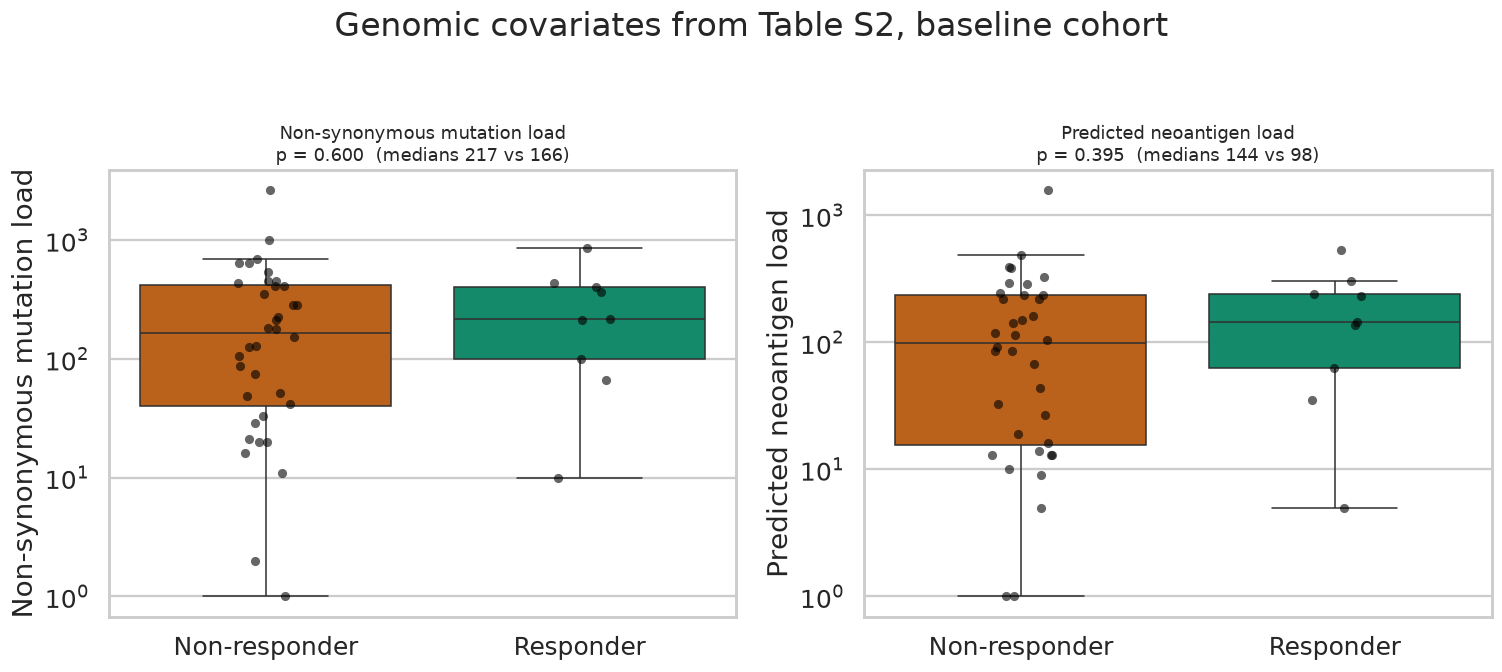

Mutation load vs cytolytic score: Spearman rho = 0.171, p = 0.261
Mutation load and transcriptional inflammation are largely independent axes,
which is consistent with the original study and with the general observation that
tumour mutational burden and a T-cell-inflamed phenotype are complementary rather
than redundant biomarkers.


In [163]:
# Cross-check with the genomic covariates from Table S2.
genomic = composite.dropna(subset=["mutation_load"]).copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, column, label in [
    (axes[0], "mutation_load", "Non-synonymous mutation load"),
    (axes[1], "neoantigen_load", "Predicted neoantigen load"),
]:
    data = genomic.dropna(subset=[column])
    sns.boxplot(data=data, x="response_group", y=column, hue="response_group",
                palette=RESPONSE_PALETTE, legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=data, x="response_group", y=column,
                  color="black", alpha=0.6, size=6, ax=ax)
    resp = data.loc[data["response_group"] == "Responder", column]
    nonresp = data.loc[data["response_group"] == "Non-responder", column]
    stat, pvalue = mannwhitneyu(resp, nonresp, alternative="two-sided")
    ax.set_yscale("log")
    ax.set_title(f"{label}\np = {pvalue:.3f}  "
                 f"(medians {resp.median():.0f} vs {nonresp.median():.0f})", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel(label)
plt.suptitle("Genomic covariates from Table S2, baseline cohort", y=1.03)
plt.tight_layout()
plt.show()
rho_m, p_m = spearmanr(genomic["mutation_load"], genomic["cytolytic_score"])
print(f"Mutation load vs cytolytic score: Spearman rho = {rho_m:.3f}, p = {p_m:.3f}")
print("Mutation load and transcriptional inflammation are largely independent axes,")
print("which is consistent with the original study and with the general observation that")
print("tumour mutational burden and a T-cell-inflamed phenotype are complementary rather")
print("than redundant biomarkers.")

### Pathway-level analysis
GSEA on the complete ranked gene list is used instead of enrichment of a short DEG list,
because it detects coordinated but individually modest shifts, which is precisely the
situation in a cohort of this size.
Two implementation problems are addressed:
- **Gene sets are cached locally.** Retrieving collections from a remote server at every
  call makes the function hang indefinitely on a slow or blocked connection, without raising
  an error. This is the usual cause of a GSEA cell that never finishes.
- **Collections are run separately, multithreaded, with 200 permutations**, and the Reactome
  result is cached on disk. Reactome contains roughly 1800 gene sets; running it together
  with Hallmark, single-threaded, at 1000 permutations takes hours.

In [164]:
GMT_DIR = DATA_DIR / "gene_sets"
GMT_DIR.mkdir(exist_ok=True)
MSIGDB_BASE = "https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2023.2.Hs/"
COLLECTIONS = {
    "Hallmark": "h.all.v2023.2.Hs.symbols.gmt",
    "Reactome": "c2.cp.reactome.v2023.2.Hs.symbols.gmt",
}
available_collections = {}
for label, file_name in COLLECTIONS.items():
    path = GMT_DIR / file_name
    if not path.exists():
        try:
            urllib.request.urlretrieve(MSIGDB_BASE + file_name, path)
            print("downloaded :", file_name)
        except Exception as error:
            print("FAILED     :", file_name, "->", error)
    if path.exists():
        available_collections[label] = str(path)
print("Local collections:", list(available_collections))
if "Hallmark" not in available_collections:
    available_collections["Hallmark"] = "MSigDB_Hallmark_2020"
    print("Falling back to the Enrichr copy of Hallmark.")

Local collections: ['Hallmark', 'Reactome']


In [165]:
ranking = de_results[["symbol", "stat"]].dropna(subset=["stat"]).copy()
ranking = ranking[np.isfinite(ranking["stat"])]
ranking = ranking.groupby("symbol", as_index=False)["stat"].mean()
ranking = ranking.sort_values("stat", ascending=False)
ranked_genes = ranking.set_index("symbol")["stat"]
assert ranked_genes.index.is_unique
assert np.isfinite(ranked_genes.values).all()
print("Genes in the ranking :", ranked_genes.shape[0])
print("Statistic range      :",
      round(ranked_genes.min(), 2), "to", round(ranked_genes.max(), 2))
print("Positive statistics  :", int((ranked_genes > 0).sum()),
      f"({(ranked_genes > 0).mean() * 100:.1f}%)")
print("\nTop 10 up in responders  :", ranked_genes.head(10).index.tolist())
print("Top 10 up in non-resp.   :", ranked_genes.tail(10).index.tolist())

Genes in the ranking : 16592
Statistic range      : -5.12 to 8.23
Positive statistics  : 8092 (48.8%)

Top 10 up in responders  : ['ITIH1', 'BHMT', 'ITIH4', 'C5', 'SLC22A1', 'HSD17B6', 'CR2', 'HSD17B13', 'SERPINA1', 'RDH16']
Top 10 up in non-resp.   : ['FAT2', 'LDB3', 'FBXL2', 'RSPH9', 'H3C10', 'BAIAP2L2', 'ENTREP1', 'AATBC', 'S100A2', 'SLC9A3']


In [166]:
PERMUTATIONS = 1000
THREADS = 4
gsea_tables = []
start = time.time()
hallmark = gp.prerank(
    rnk=ranked_genes, gene_sets=available_collections["Hallmark"],
    permutation_num=PERMUTATIONS, min_size=15, max_size=500,
    threads=THREADS, seed=RANDOM_STATE, outdir=None, no_plot=True, verbose=False,
)
table = hallmark.res2d.copy()
table["collection"] = "Hallmark"
gsea_tables.append(table)
print(f"Hallmark finished in {time.time() - start:.1f} s, {table.shape[0]} gene sets")
display(table.head(15)[["Term", "NES", "NOM p-val", "FDR q-val"]])

Hallmark finished in 3.1 s, 50 gene sets


,Term,NES,NOM p-val,FDR q-val
0,HALLMARK_ALLOGRAFT_REJECTION,2.645642,0.000000,0.000000
1,HALLMARK_XENOBIOTIC_METABOLISM,2.509171,0.000000,0.000000
2,HALLMARK_INTERFERON_GAMMA_RESPONSE,2.404761,0.000000,0.000000
3,HALLMARK_BILE_ACID_METABOLISM,2.151413,0.000000,0.000000
4,HALLMARK_COMPLEMENT,2.150582,0.000000,0.000000
5,HALLMARK_IL6_JAK_STAT3_SIGNALING,2.147420,0.000000,0.000000
6,HALLMARK_COAGULATION,2.096476,0.000000,0.000000
7,HALLMARK_INFLAMMATORY_RESPONSE,1.935914,0.000000,0.000500
8,HALLMARK_FATTY_ACID_METABOLISM,1.763569,0.001376,0.002777
9,HALLMARK_KRAS_SIGNALING_UP,1.657077,0.000000,0.007798


In [167]:
reactome_cache = DATA_DIR / "block1_GSEA_reactome.csv"
if reactome_cache.exists():
    reactome_table = pd.read_csv(reactome_cache)
    print("Reactome loaded from cache:", reactome_table.shape[0], "gene sets")
elif "Reactome" in available_collections:
    start = time.time()
    reactome = gp.prerank(
        rnk=ranked_genes, gene_sets=available_collections["Reactome"],
        permutation_num=PERMUTATIONS, min_size=15, max_size=500,
        threads=THREADS, seed=RANDOM_STATE, outdir=None, no_plot=True, verbose=False,
    )
    reactome_table = reactome.res2d.copy()
    reactome_table["collection"] = "Reactome"
    reactome_table.to_csv(reactome_cache, index=False)
    print(f"Reactome finished in {(time.time() - start) / 60:.1f} min")
else:
    reactome_table = pd.DataFrame()
    print("Reactome collection unavailable, skipped.")
if not reactome_table.empty:
    gsea_tables.append(reactome_table)

Reactome loaded from cache: 1003 gene sets


In [168]:
gsea = pd.concat(gsea_tables, ignore_index=True)
for column in ["ES", "NES", "NOM p-val", "FDR q-val"]:
    gsea[column] = pd.to_numeric(gsea[column], errors="coerce")
# Separate genuine immune signals from hepatic and metabolic programmes, which the
# contamination analysis above showed to be present in this cohort.
HEPATIC_TERMS = [
    "XENOBIOTIC", "BILE_ACID", "COAGULATION", "FATTY_ACID", "PEROXISOME",
    "DRUG_METABOLISM", "BIOLOGICAL_OXIDATION", "PHASE_I", "PHASE_II",
    "PLASMA_LIPOPROTEIN", "METABOLISM_OF_AMINO", "CYTOCHROME_P450", "RETINOID",
]
IMMUNE_TERMS = [
    "IMMUN", "INTERFERON", "INFLAMMATORY", "ALLOGRAFT", "TCR", "T_CELL", "B_CELL",
    "LYMPHOCYTE", "CYTOKINE", "CHEMOKINE", "MHC", "ANTIGEN", "PD_1", "CTLA4",
    "COSTIMULATION", "IL2", "IL6_JAK", "JAK_STAT", "COMPLEMENT_CASCADE",
    "NK_CELL", "TNF", "TOLL_LIKE", "FCGR", "BCR",
]
upper_terms = gsea["Term"].str.upper()
gsea["hepatic_metabolic"] = upper_terms.apply(lambda t: any(k in t for k in HEPATIC_TERMS))
gsea["immune"] = upper_terms.apply(lambda t: any(k in t for k in IMMUNE_TERMS))
gsea = gsea.sort_values("FDR q-val")
gsea.to_csv(DATA_DIR / "block1_GSEA_all.csv", index=False)
n_sig = int((gsea["FDR q-val"] < 0.25).sum())
print(f"Gene sets tested            : {gsea.shape[0]}")
print(f"FDR q-val below 0.25        : {n_sig} ({n_sig / gsea.shape[0] * 100:.0f}%)")
gsea_immune = gsea[gsea["immune"] & ~gsea["hepatic_metabolic"]
                   & (gsea["FDR q-val"] < 0.25)].sort_values("NES", ascending=False)
gsea_hepatic = gsea[gsea["hepatic_metabolic"] & (gsea["FDR q-val"] < 0.25)] \
    .sort_values("NES", ascending=False)
print(f"\nImmune gene sets, FDR < 0.25            : {gsea_immune.shape[0]}")
display(gsea_immune.head(20)[["Term", "collection", "NES", "FDR q-val", "Lead_genes"]])
print(f"Hepatic and metabolic gene sets, FDR < 0.25 : {gsea_hepatic.shape[0]}")
display(gsea_hepatic.head(8)[["Term", "NES", "FDR q-val", "Lead_genes"]])

Gene sets tested            : 1053
FDR q-val below 0.25        : 324 (31%)

Immune gene sets, FDR < 0.25            : 27


,Term,collection,NES,FDR q-val,Lead_genes
50,REACTOME_COMPLEMENT_CASCADE,Reactome,2.948492,0.000000,C5;CR2;VTN;CFHR3;CD19;CFHR1;CFB;CPB2;FCN3;C6;M...
0,HALLMARK_ALLOGRAFT_REJECTION,Hallmark,2.645642,0.000000,CD79A;MAP4K1;LTB;HDAC9;HLA-DOB;CD3G;TRAT1;CXCL...
51,REACTOME_ANTIGEN_ACTIVATES_B_CELL_RECEPTOR_BCR...,Reactome,2.548991,0.000000,CD19;BLK;CD79A;CD22;IGHD;PLCG2;CD79B;BLNK;DAPP...
2,HALLMARK_INTERFERON_GAMMA_RESPONSE,Hallmark,2.404761,0.000000,BANK1;CFB;CFH;GPR18;IDO1;TNFAIP3;VCAM1;GCH1;RA...
52,REACTOME_IMMUNOREGULATORY_INTERACTIONS_BETWEEN...,Reactome,2.376288,0.000000,CD19;TREML2;CD22;SELL;CLEC4G;NCR3;SLAMF6;VCAM1...
55,REACTOME_TNF_RECEPTOR_SUPERFAMILY_TNFSF_MEMBER...,Reactome,2.246125,0.000000,TNFRSF13C;LTB;LTA;TNFSF14;CD40LG;BIRC3;TNFSF11...
60,REACTOME_TNFS_BIND_THEIR_PHYSIOLOGICAL_RECEPTORS,Reactome,2.163255,0.000450,TNFRSF13B;EDARADD;CD27;LTA;TNFSF14;TNFSF11;TNF...
5,HALLMARK_IL6_JAK_STAT3_SIGNALING,Hallmark,2.147420,0.000000,INHBE;LTB;CXCL13;IL2RG;LEPR;IL13RA1;CD38;CSF2R...
69,REACTOME_CHEMOKINE_RECEPTORS_BIND_CHEMOKINES,Reactome,2.119145,0.000810,CXCR5;CCR6;CCR7;CXCR1;CCR4;CCL21;CXCL13;CCL20;...
79,REACTOME_PD_1_SIGNALING,Reactome,2.073838,0.001418,CD3G;CD247;LCK;CD3E;CSK;PTPN6;CD3D;HLA-DQA2;HL...


Hepatic and metabolic gene sets, FDR < 0.25 : 17


,Term,NES,FDR q-val,Lead_genes
1,HALLMARK_XENOBIOTIC_METABOLISM,2.509171,0.000000,ITIH1;ITIH4;SLC22A1;UPB1;VTN;LEAP2;CFB;AOX1;FM...
53,REACTOME_BILE_ACID_AND_BILE_SALT_METABOLISM,2.284540,0.000000,SLC27A5;SLC27A2;ABCB11;CYP7A1;ALB;SLC51A;BAAT;...
57,REACTOME_SYNTHESIS_OF_BILE_ACIDS_AND_BILE_SALT...,2.221086,0.000000,SLC27A5;SLC27A2;ABCB11;CYP7A1;BAAT;ACOX2;SCP2;...
62,REACTOME_PHASE_I_FUNCTIONALIZATION_OF_COMPOUNDS,2.155083,0.000368,CYP3A5;ADH6;FMO3;CYP7A1;CYP4F3;CYP2D6;CYP2E1;A...
3,HALLMARK_BILE_ACID_METABOLISM,2.151413,0.000000,HSD17B6;ALDH8A1;PIPOX;SLC27A5;SLC27A2;GNMT;TTR...
6,HALLMARK_COAGULATION,2.096476,0.000000,ITIH1;SERPINA1;F12;PROC;CFB;CPB2;MST1;KLKB1;FG...
74,REACTOME_SYNTHESIS_OF_BILE_ACIDS_AND_BILE_SALTS,2.095098,0.001125,SLC27A5;SLC27A2;ABCB11;CYP7A1;BAAT;ACOX2;SCP2;...
86,REACTOME_PLASMA_LIPOPROTEIN_REMODELING,2.011682,0.002269,MTTP;ALB;CETP;APOB;LIPC;CIDEC;PCSK6;LCAT


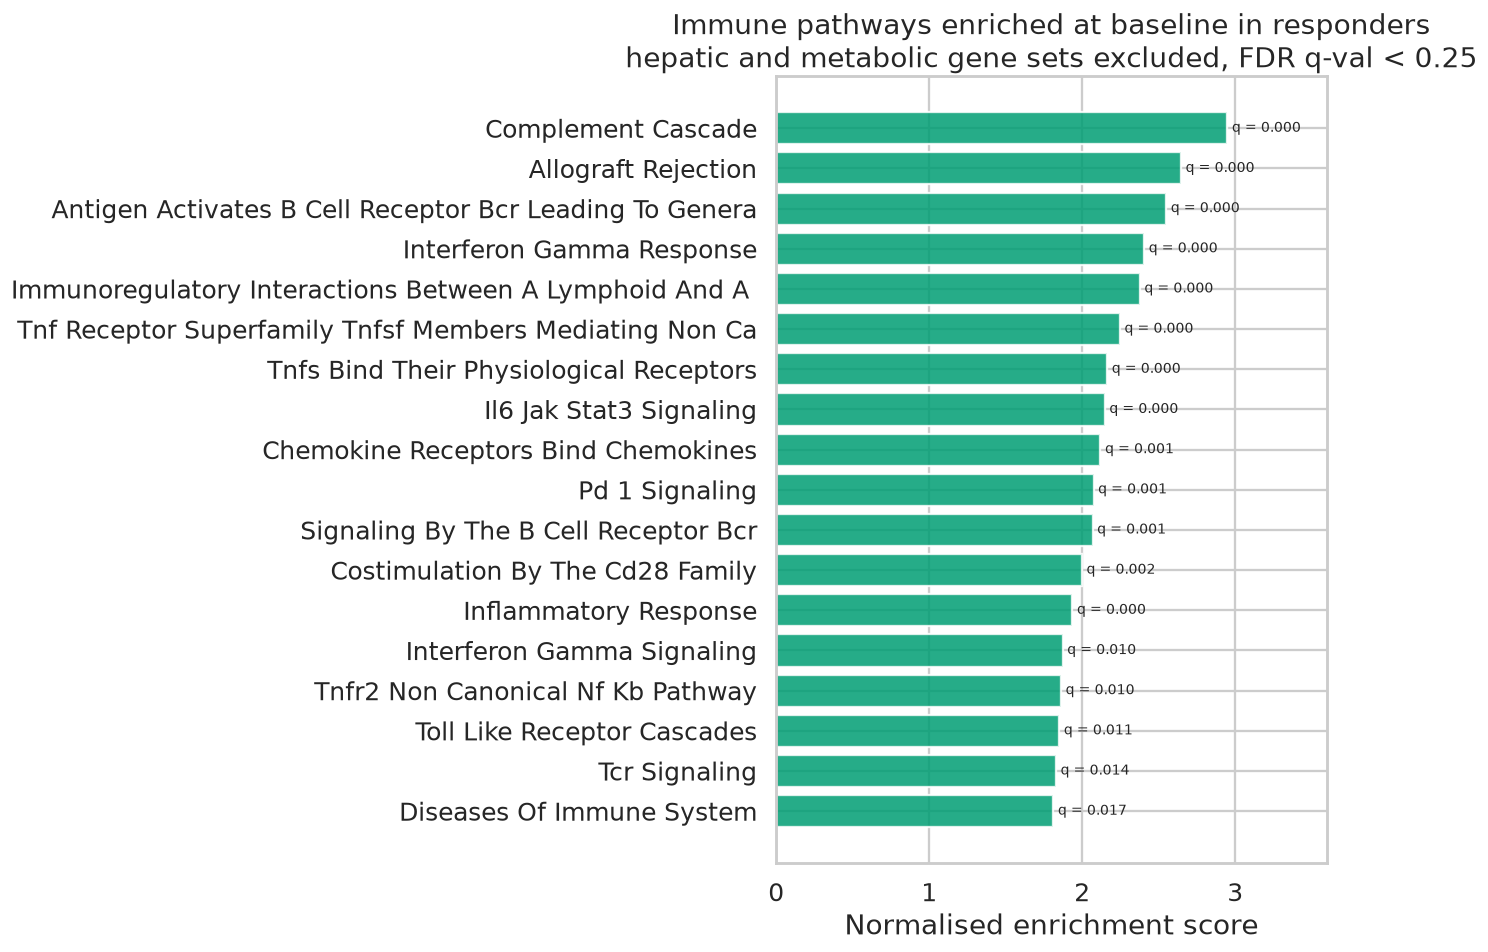

In [169]:
top_immune = gsea_immune.head(18).copy()
top_immune["label"] = (
    top_immune["Term"].str.replace("HALLMARK_", "", regex=False)
    .str.replace("REACTOME_", "", regex=False)
    .str.replace("_", " ", regex=False)
    .str.title().str.slice(0, 55)
)
top_immune = top_immune.sort_values("NES")
fig, ax = plt.subplots(figsize=(12.5, 9))
bars = ax.barh(top_immune["label"], top_immune["NES"], color=COLOR_RESPONDER, alpha=0.85)
for bar, fdr in zip(bars, top_immune["FDR q-val"]):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2,
            f"q = {fdr:.3f}", va="center", fontsize=9)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Normalised enrichment score")
ax.set_xlim(0, top_immune["NES"].max() * 1.22)
ax.set_title("Immune pathways enriched at baseline in responders\n"
             "hepatic and metabolic gene sets excluded, FDR q-val < 0.25")
plt.tight_layout()
plt.show()

## Block 1. Interpretation
### Which genes are associated with sensitivity to nivolumab
**No single gene is a robust baseline predictor in this cohort.** The analysis illustrates
why, and that is itself a result worth reporting.
The strongest nominal signals come from **hepatocyte transcripts, not immune genes**. ITIH1,
CFHR3, FGG, ABCB11 and SAA1 reach unshrunken log2 fold changes between 4.6 and 32.4 with
Wald p-values down to about 2e-16. A log2 fold change of 32 corresponds to a change of the
order of a billion fold, which is biologically impossible. The hepatocyte score identifies
the source unambiguously: two baseline biopsies carry scores near 10.7 and 9.5 against a
cohort median close to zero, and one of them belongs to a responder. After shrinkage these
estimates collapse to values near 0.003, i.e. the evidence for a group-level effect
disappears entirely while the p-value, which shrinkage does not recompute, remains tiny.
Flagging such genes as unstable is therefore essential.
**The genes that survive both safeguards form a coherent and partly unexpected group.** The
large majority are higher in responders. The strongest reliable candidates are not only the
expected cytotoxic T cell genes but a prominent **B lymphocyte module**: TNFRSF13C (the BAFF
receptor), CD79A, SPIB, FCRL2, POU2F2, BACH2, P2RX5, together with the T cell and
immune-regulatory genes AKNA, NLRC3 and GPR18. This is a notable finding, because the
association of intratumoral B cells and tertiary lymphoid structures with response to
checkpoint blockade in melanoma was established several years *after* the original
publication, which described the baseline signal mainly in terms of T cell activation and
lymphocyte aggregation.
Among genes higher in non-responders, S100A2, SLC9A3, ENTREP1, BAIAP2L2, PTK7 and FBXL2
form a small epithelial and differentiation-associated group. Given that cutaneous biopsies
contain adnexal and epidermal tissue, part of this signal may reflect sampled normal tissue
rather than a tumour-intrinsic resistance programme, and it should be reported with that
caveat.
### Which processes and pathways differ between the groups
The **pathway level carries the signal that the gene list does not**. Enriched in responders:
- HALLMARK_ALLOGRAFT_REJECTION, the strongest immune set, with leading-edge genes CD79A,
  MAP4K1, LTB, HDAC9, HLA-DOB, CD3G, TRAT1 and CXCL chemokines
- HALLMARK_INTERFERON_GAMMA_RESPONSE, leading edge including BANK1, GPR18, IDO1, TNFAIP3,
  VCAM1, GCH1
- HALLMARK_IL6_JAK_STAT3_SIGNALING, leading edge including LTB, CXCL13, IL2RG, CD38
- HALLMARK_INFLAMMATORY_RESPONSE, leading edge including SLAMF1, CCR7, SELL
- Reactome sets covering TCR signalling, PD-1 signalling, interferon signalling and MHC
  class II antigen presentation
Two cautions are required. First, a substantial fraction of gene sets passes FDR 0.25. This
reflects a strongly asymmetric ranking, since the overwhelming majority of significant genes
are higher in responders, combined with the coarse null distribution of 200 permutations.
The enrichment output should therefore be read as a description of the **direction** of the
signal rather than as a set of formally significant discoveries. Second, hepatic and
metabolic gene sets such as xenobiotic metabolism, bile acid metabolism and coagulation also
reach high NES values, and their leading-edge genes are precisely the contaminating
hepatocyte transcripts. They were separated explicitly rather than reported as biology.
### Can potential biomarkers be identified
Only **exploratory composite candidates**, not single genes. In the pre-specified panel,
every one of the twenty-six canonical markers has a higher median in responders, and CD3E,
IDO1, CTLA4 and TIGIT reach nominal significance, but **nothing survives FDR correction**.
The largest median differences are in markers of *activated* T cells (TIGIT, CTLA4, IDO1,
CXCL9, CD8A, CD2), whereas constitutively expressed antigen-presentation genes (B2M, TAP1)
and HAVCR2 and GNLY show almost no difference. That contrast is mechanistically sensible: a
response depends on the presence of activated, antigen-experienced T cells rather than on
baseline housekeeping levels of the presentation machinery.
The cytolytic score is higher in responders overall but does not reach significance. Its
behaviour after stratification is the more informative observation: separation is clear in
the **Ipi-progressed** subgroup and essentially absent in the **Ipi-naive** subgroup. This
reproduces the published conclusion that an inflamed or "hot" baseline microenvironment is
required for response after prior anti-CTLA-4 failure, whereas ipilimumab-naive patients can
respond even with low baseline inflammation.
The correlation of my cytolytic score with the score published with the dataset validates
the whole upstream pipeline, which matters because identifier mapping and aggregation
choices are the most common silent source of error in this type of reanalysis.
### Consistency with the mechanism of anti-PD-1 therapy
**Directionally consistent, quantitatively weak, and that is the expected result.** PD-1
blockade does not create tumour-specific immunity de novo; it relieves inhibition of
pre-existing tumour-reactive T cells. A response therefore requires prior antigen
presentation, interferon signalling and T cell infiltration, which is what the enrichment
analysis shows.
The weakness of the effect also matches the source publication, which reported 189 DEGs at
q below 0.20 and stated explicitly that these changes were **only marginally predictive** of
response. Reproducing a weak signal faithfully, rather than manufacturing a strong one
through permissive filtering, is the correct outcome here.
### Unexpected findings
1. **Tissue composition, not immune biology, dominates the naive result.** Two baseline samples showed marked hepatocyte-associated transcriptional contamination, consistent with substantial liver-derived RNA.
2. **A prominent B-cell-associated transcriptional module**, which anticipates a mechanism recognised only after 2017. This may be compatible with the presence of lymphoid aggregates/TLS, but TLS cannot be established from bulk RNA-seq alone.
3. **PDCD1 and CD274 are not differentially expressed at baseline.** The direct targets and
   ligand of the drug do not predict its efficacy, reproducing the original observation and
   underlining that PD-L1 expression alone is an insufficient biomarker.
4. **The value of an inflamed baseline phenotype depends on prior therapy**, being apparent
   only in the Ipi-progressed subgroup.
5. **Mutation load and transcriptional inflammation are only weakly correlated**, confirming
   that they are complementary rather than interchangeable biomarker axes.

# Block 2. Dynamics of the tumour microenvironment
Only patients with **matched pre- and on-treatment biopsies** are analysed, so that each
patient serves as their own control and between-patient heterogeneity does not confound the
comparison. On-treatment biopsies were taken on cycle 1 day 29, i.e. after four weeks of
nivolumab, from the same site as the baseline biopsy.
### Signatures
A curated collection of **29 functional TME gene signatures** (`gene_signatures.gmt`;
Bagaev et al., *Cancer Cell* 2021, doi:10.1016/j.ccell.2021.04.014)
is used rather than an ad hoc marker list. This collection covers the tumour
microenvironment systematically: antigen presentation, effector and regulatory lymphocytes,
myeloid suppression, angiogenesis, fibroblasts, matrix remodelling, EMT and proliferation.
The accompanying `gene_signatures_order.tsv` defines a biologically meaningful display
order, running from pro-tumour and suppressive programmes at one end to anti-tumour immune
programmes at the other, and it is used for all figures so that the direction of the
immune-suppressive axis is visible at a glance.
### Scoring and statistics
Scores are computed with **ssGSEA** on log2(FPKM + 1). For each patient and signature:

**delta = score(on-treatment) - score(pre-treatment)**

Three questions are answered separately, because they are not equivalent:
1. **Within-group.** Does a signature change significantly during therapy inside each
   response group? Wilcoxon signed-rank test on paired values.
2. **Between-group.** Does the magnitude of change differ between responders and
   non-responders? Mann-Whitney test on the delta values.
3. **Composition-adjusted.** Does the difference survive adjustment for the change in
   tumour cell content? This is required because ssGSEA scores are **relative**: if tumour
   cells are eliminated, every other compartment appears to increase even when its absolute
   abundance is unchanged.

In [170]:
# Load the curated TME signature collection (Bagaev et al., Cancer Cell 2021).
GMT_PATH = DATA_DIR / "gene_signatures.gmt"
ORDER_PATH = DATA_DIR / "gene_signatures_order.tsv"
GMT_EMBEDDED = """MHCI\tMHCI\tHLA-A\tHLA-B\tHLA-C\tB2M\tTAP1\tTAP2\tNLRC5\tTAPBP
MHCII\tMHCII\tHLA-DRA\tHLA-DRB1\tHLA-DMA\tHLA-DPA1\tHLA-DPB1\tHLA-DMB\tHLA-DQB1\tHLA-DQA1\tCIITA
Coactivation_molecules\tCo-stimulatory molecules\tCD28\tCD40\tTNFRSF4\tICOS\tTNFRSF9\tCD27\tCD80\tCD86\tCD40LG\tCD83\tTNFSF4\tICOSLG\tTNFSF9\tCD70
Effector_cells\tEffector cells\tIFNG\tGZMA\tGZMB\tPRF1\tGZMK\tZAP70\tGNLY\tFASLG\tTBX21\tEOMES\tCD8A\tCD8B
T_cell_traffic\tEffector cell traffic\tCXCL9\tCXCL10\tCXCL11\tCX3CL1\tCCL3\tCCL4\tCX3CR1\tCCL5\tCXCR3
NK_cells\tNK cells\tNKG7\tCD160\tCD244\tNCR1\tKLRC2\tKLRK1\tCD226\tGZMH\tGNLY\tIFNG\tKIR2DL4\tEOMES\tGZMB\tFGFBP2\tKLRF1\tSH2D1B\tNCR3
T_cells\tT cells\tTBX21\tITK\tCD3D\tCD3E\tCD3G\tTRAC\tTRBC1\tTRBC2\tCD28\tCD5\tTRAT1
B_cells\tB cells\tCD19\tMS4A1\tTNFRSF13C\tCR2\tTNFRSF17\tTNFRSF13B\tCD22\tCD79A\tCD79B\tBLK\tFCRL5\tPAX5\tSTAP1
M1_signatures\tM1 signature\tNOS2\tTNF\tIL1B\tSOCS3\tCMKLR1\tIRF5\tIL12A\tIL12B\tIL23A
Th1_signature\tTh1 signature\tIFNG\tIL2\tCD40LG\tIL21\tTBX21\tSTAT4\tIL12RB2
Antitumor_cytokines\tAntitumor cytokines\tTNF\tIFNB1\tIFNA2\tCCL3\tTNFSF10\tIL21
Checkpoint_inhibition\tCheckpoint molecules\tPDCD1\tCD274\tCTLA4\tLAG3\tPDCD1LG2\tBTLA\tHAVCR2\tTIGIT\tVSIR
Treg\tTreg\tFOXP3\tCTLA4\tIL10\tTNFRSF18\tCCR8\tIKZF4\tIKZF2
T_reg_traffic\tTreg and Th2 traffic\tCCL17\tCCL22\tCCL1\tCCL28\tCCR4\tCCR8\tCCR10
Neutrophil_signature\tNeutrophil signature\tMPO\tELANE\tPRTN3\tCTSG\tCXCR1\tCXCR2\tFCGR3B\tCD177\tFFAR2\tPGLYRP1
Granulocyte_traffic\tGranulocyte traffic\tCXCL8\tCXCL1\tCXCL2\tCXCL5\tCCL11\tKITLG\tCXCR1\tCXCR2\tCCR3
MDSC\tImmune Suppression by Myeloid Cells\tIDO1\tARG1\tIL10\tCYBB\tPTGS2\tIL4I1\tIL6
MDSC_traffic\tMyeloid cells traffic\tCSF2\tCSF3\tCXCL12\tCCL26\tIL6\tCXCL8\tCXCL5\tCSF1R\tCSF2RA\tCSF3R\tCXCR4\tIL6R\tCXCR2\tCCL15\tCSF1
Macrophages\tTumor-associated Macrophages\tIL10\tMRC1\tMSR1\tCD163\tCSF1R\tIL4I1\tSIGLEC1\tCD68
Macrophage_DC_traffic\tMacrophage and DC traffic\tCCL2\tCCL7\tCCL8\tXCL1\tCCR2\tXCR1\tCSF1R\tCSF1
Th2_signature\tTh2 signature\tIL4\tIL5\tIL13\tIL10\tCCR4
Protumor_cytokines\tProtumor cytokines\tIL10\tTGFB1\tTGFB2\tTGFB3\tIL22\tMIF\tIL6
CAF\tFibroblasts\tCOL1A1\tCOL1A2\tCOL5A1\tACTA2\tFGF2\tFAP\tLRP1\tCD248\tCOL6A1\tCOL6A2\tCOL6A3\tCXCL12\tFBLN1\tLUM\tMFAP5\tMMP3\tMMP2\tPDGFRB\tPDGFRA
Matrix\tMatrix\tFN1\tCOL1A1\tCOL1A2\tCOL4A1\tCOL3A1\tVTN\tLGALS7\tLGALS9\tLAMA3\tLAMB3\tLAMC2\tTNC\tELN\tCOL5A1\tCOL11A1
Matrix_remodeling\tMatrix remodeling\tCA9\tMMP9\tMMP2\tMMP1\tMMP3\tMMP12\tMMP7\tMMP11\tPLOD2\tADAMTS4\tADAMTS5\tLOX
Angiogenesis\tAngiogenesis\tVEGFA\tVEGFB\tVEGFC\tPDGFC\tCXCL8\tCXCR2\tFLT1\tPGF\tCXCL5\tKDR\tANGPT1\tANGPT2\tTEK\tVWF\tCDH5
Endothelium\tEndothelium\tNOS3\tKDR\tFLT1\tVCAM1\tVWF\tCDH5\tMMRN1\tENG\tCLEC14A\tMMRN2
Proliferation_rate\tTumor proliferation rate\tMKI67\tESCO2\tCETN3\tCDK2\tCCND1\tCCNE1\tAURKA\tAURKB\tE2F1\tMYBL2\tBUB1\tPLK1\tCCNB1\tMCM2\tMCM6
EMT_signature\tEMT signature\tSNAI1\tSNAI2\tTWIST1\tTWIST2\tZEB1\tZEB2\tCDH2
"""
ORDER_EMBEDDED = """Angiogenesis
Endothelium
CAF
Matrix
Matrix_remodeling
Protumor_cytokines
Neutrophil_signature
Granulocyte_traffic
Macrophages
Macrophage_DC_traffic
MDSC_traffic
MDSC
Th2_signature
T_reg_traffic
Treg
M1_signatures
MHCII
Antitumor_cytokines
Coactivation_molecules
B_cells
NK_cells
Checkpoint_inhibition
Effector_cells
T_cells
Th1_signature
T_cell_traffic
MHCI
EMT_signature
Proliferation_rate
"""
def load_gmt(path=GMT_PATH, embedded=GMT_EMBEDDED):
    """Parse a GMT file. Column 1 = identifier, column 2 = description, rest = genes."""
    if path.exists():
        text = path.read_text(encoding="utf-8")
        source = f"file: {path.name}"
    else:
        text = embedded
        source = "embedded copy of gene_signatures.gmt"
    signatures, descriptions = {}, {}
    for line in text.strip().split("\n"):
        fields = [f.strip() for f in line.split("\t") if f.strip()]
        if len(fields) < 3:
            continue
        name, description, genes = fields[0], fields[1], fields[2:]
        signatures[name] = sorted(set(genes))
        descriptions[name] = description
    print("Signature source :", source)
    return signatures, descriptions
def load_order(path=ORDER_PATH, embedded=ORDER_EMBEDDED):
    text = path.read_text(encoding="utf-8") if path.exists() else embedded
    return [line.strip() for line in text.strip().split("\n") if line.strip()]
tme_signatures_raw, signature_labels = load_gmt()
signature_order_full = load_order()
print("Signatures loaded :", len(tme_signatures_raw))
print("Display order      :", len(signature_order_full), "entries")
assert set(signature_order_full) == set(tme_signatures_raw), \
    "The order file and the GMT file must describe the same signatures."

Signature source : embedded copy of gene_signatures.gmt
Signatures loaded : 29
Display order      : 29 entries


In [171]:
# Check gene availability in the expression matrix before scoring.
qc_rows = []
tme_signatures = {}
for name in signature_order_full:
    genes = tme_signatures_raw[name]
    present = [g for g in genes if g in fpkm_hgnc.index]
    missing = sorted(set(genes) - set(present))
    tme_signatures[name] = present
    qc_rows.append({
        "signature": name,
        "description": signature_labels[name],
        "n_genes": len(genes),
        "n_found": len(present),
        "coverage": len(present) / len(genes),
        "missing": ", ".join(missing) if missing else "-",
    })
signature_qc = pd.DataFrame(qc_rows)
display(signature_qc.round(3))
# Signatures with fewer than 4 detected genes are unreliable for ssGSEA.
MIN_GENES = 4
dropped = signature_qc.loc[signature_qc["n_found"] < MIN_GENES, "signature"].tolist()
for name in dropped:
    tme_signatures.pop(name)
signature_columns = [n for n in signature_order_full if n in tme_signatures]
print(f"\nMedian coverage        : {signature_qc['coverage'].median():.2%}")
print(f"Signatures dropped     : {dropped or 'none'}")
print(f"Signatures retained    : {len(signature_columns)}")

,signature,description,n_genes,n_found,coverage,missing
0,Angiogenesis,Angiogenesis,15,15,1.000,-
1,Endothelium,Endothelium,10,10,1.000,-
2,CAF,Fibroblasts,19,19,1.000,-
3,Matrix,Matrix,15,15,1.000,-
4,Matrix_remodeling,Matrix remodeling,12,12,1.000,-
5,Protumor_cytokines,Protumor cytokines,7,6,0.857,MIF
6,Neutrophil_signature,Neutrophil signature,10,10,1.000,-
7,Granulocyte_traffic,Granulocyte traffic,9,9,1.000,-
8,Macrophages,Tumor-associated Macrophages,8,8,1.000,-
9,Macrophage_DC_traffic,Macrophage and DC traffic,8,8,1.000,-



Median coverage        : 100.00%
Signatures dropped     : none
Signatures retained    : 29


In [172]:
timepoints_per_patient = metadata_analysis.groupby("patient_id")["timepoint"].nunique()
paired_patient_ids = timepoints_per_patient[timepoints_per_patient == 2].index
paired_metadata = metadata_analysis[
    metadata_analysis["patient_id"].isin(paired_patient_ids)
].copy()
paired_metadata = paired_metadata.drop_duplicates(subset=["patient_id", "timepoint"])
paired_metadata = paired_metadata.sort_values(["patient_id", "timepoint"])
paired_samples = paired_metadata["sample_id"].tolist()
paired_log_fpkm = np.log2(fpkm_hgnc.loc[:, paired_samples] + 1)
patient_level = paired_metadata.drop_duplicates("patient_id").set_index("patient_id")
print("PAIRED COHORT")
print("=" * 46)
print("Patients :", patient_level.shape[0])
print("Samples  :", len(paired_samples))
print()
display(pd.crosstab(patient_level["response_group"], patient_level["prior_ipi"],
                    margins=True))
print("\nRECIST response:")
print(patient_level["response"].value_counts().to_string())
n_resp = int((patient_level["response_group"] == "Responder").sum())
print(f"\nWith {n_resp} paired responders, the smallest attainable two-sided p-value of")
print(f"the Wilcoxon signed-rank test is {2 / 2**n_resp:.4f}. Absence of significance in")
print("this group is therefore not evidence of absence of change.")


PAIRED COHORT
Patients : 42
Samples  : 84



prior_ipi,Ipi-N,Ipi-P,All
response_group,,,
Non-responder,14,20,34
Responder,4,4,8
All,18,24,42



RECIST response:
response
PD    18
SD    15
PR     5
CR     3
NE     1

With 8 paired responders, the smallest attainable two-sided p-value of
the Wilcoxon signed-rank test is 0.0078. Absence of significance in
this group is therefore not evidence of absence of change.


In [173]:
start = time.time()
ssgsea_result = gp.ssgsea(
    data=paired_log_fpkm,
    gene_sets=tme_signatures,
    sample_norm_method="rank",
    min_size=MIN_GENES,
    max_size=500,
    outdir=None,
    no_plot=True,
    threads=4,
    seed=RANDOM_STATE,
)
print(f"ssGSEA finished in {time.time() - start:.1f} s")
ssgsea_long = ssgsea_result.res2d.copy()
# gseapy returns the score columns as strings.
for column in ["ES", "NES"]:
    ssgsea_long[column] = pd.to_numeric(ssgsea_long[column], errors="coerce")
print("Columns :", ssgsea_long.columns.tolist())
print("Rows    :", ssgsea_long.shape[0],
      f"(= {len(paired_samples)} samples x {len(tme_signatures)} signatures)")
assert ssgsea_long.shape[0] == len(paired_samples) * len(tme_signatures)
display(ssgsea_long.head())

ssGSEA finished in 0.9 s
Columns : ['Name', 'Term', 'ES', 'NES']
Rows    : 2436 (= 84 samples x 29 signatures)


,Name,Term,ES,NES
0,Pt34_On_AD485757-6,MHCII,10248.475074,0.520713
1,Pt34_Pre_AD466985-6,MHCII,9991.640667,0.507664
2,Pt30_On_AD505620-6,MHCII,9949.451213,0.505520
3,Pt44_On_AD167376-6,CAF,9857.871207,0.500867
4,Pt36_Pre_AD467095-6,CAF,9797.450694,0.497797


In [174]:
signature_scores = (
    ssgsea_long.pivot(index="Name", columns="Term", values="NES")
    .reindex(paired_samples)
    .loc[:, signature_columns]
)
signature_scores = signature_scores.join(
    paired_metadata.set_index("sample_id")[
        ["patient_id", "timepoint", "response", "response_group", "prior_ipi"]
    ]
)
assert signature_scores[signature_columns].notna().all().all()
print("Score matrix:", signature_scores[signature_columns].shape, "no missing values")
signature_scores.to_csv(DATA_DIR / "block2_ssGSEA_scores.csv")
display(signature_scores[signature_columns[:6] + ["patient_id", "timepoint",
                                                  "response_group"]].head())

Score matrix: (84, 29) no missing values


,Angiogenesis,Endothelium,CAF,Matrix,Matrix_remodeling,Protumor_cytokines,patient_id,timepoint,response_group
Name,,,,,,,,,
Pt1_Pre_AD101148-6,0.080493,0.093384,0.240041,0.223782,0.029780,0.050480,Pt1,Pre,Non-responder
Pt1_On_AD174047-6,0.102146,0.060216,0.104178,0.157169,-0.025206,0.051232,Pt1,On,Non-responder
Pt10_Pre_E9047565-6,0.109353,0.127971,0.226011,0.159424,-0.026536,-0.016418,Pt10,Pre,Non-responder
Pt10_On_E9047632-6,0.188831,0.152169,0.335927,0.244126,0.089832,0.060853,Pt10,On,Non-responder
Pt101_Pre_AD486328-5,0.144469,0.166038,0.167320,0.146837,0.069003,0.044559,Pt101,Pre,Responder


In [175]:
pre_scores = (
    signature_scores.query("timepoint == 'Pre'")
    .set_index("patient_id")[signature_columns].add_suffix("_Pre")
)
on_scores = (
    signature_scores.query("timepoint == 'On'")
    .set_index("patient_id")[signature_columns].add_suffix("_On")
)
deltas = pre_scores.join(on_scores, how="inner")
for signature in signature_columns:
    deltas[f"{signature}_delta"] = deltas[f"{signature}_On"] - deltas[f"{signature}_Pre"]
deltas = deltas.join(patient_level[["response", "response_group", "prior_ipi"]])
delta_columns = [f"{s}_delta" for s in signature_columns]
print("Patients with paired scores :", deltas.shape[0])
assert deltas.shape[0] == patient_level.shape[0]
display(deltas[delta_columns[:6] + ["response_group"]].round(3).head())

Patients with paired scores : 42


,Angiogenesis_delta,Endothelium_delta,CAF_delta,Matrix_delta,Matrix_remodeling_delta,Protumor_cytokines_delta,response_group
patient_id,,,,,,,
Pt1,0.022,-0.033,-0.136,-0.067,-0.055,0.001,Non-responder
Pt10,0.079,0.024,0.110,0.085,0.116,0.077,Non-responder
Pt101,0.041,0.133,0.097,0.094,0.015,0.027,Responder
Pt103,-0.063,-0.040,-0.056,-0.029,-0.138,-0.087,Non-responder
Pt106,-0.026,-0.109,-0.022,0.007,-0.060,-0.002,Non-responder


### Baseline comparison of the paired cohort
Before examining change, it is necessary to establish where each group **starts**. A
signature already near its ceiling cannot increase much further, and this turns out to be
decisive for interpreting the on-treatment results.

,signature,median_pre_responders,median_pre_non_responders,difference,pvalue,FDR
24,Th1_signature,-0.0535,-0.1384,0.0848,0.0071,0.1074
23,T_cells,0.1972,0.0408,0.1564,0.0149,0.1074
17,Antitumor_cytokines,0.0716,-0.0242,0.0958,0.0218,0.1074
14,Treg,-0.0063,-0.1042,0.0980,0.0262,0.1074
21,Checkpoint_inhibition,0.1813,0.0322,0.1491,0.0262,0.1074
20,NK_cells,0.0415,-0.0880,0.1296,0.0286,0.1074
19,B_cells,-0.0332,-0.1449,0.1117,0.0286,0.1074
11,MDSC,0.1523,0.0454,0.1069,0.0370,0.1074
18,Coactivation_molecules,0.0990,0.0072,0.0918,0.0370,0.1074
22,Effector_cells,0.2165,0.0339,0.1826,0.0370,0.1074


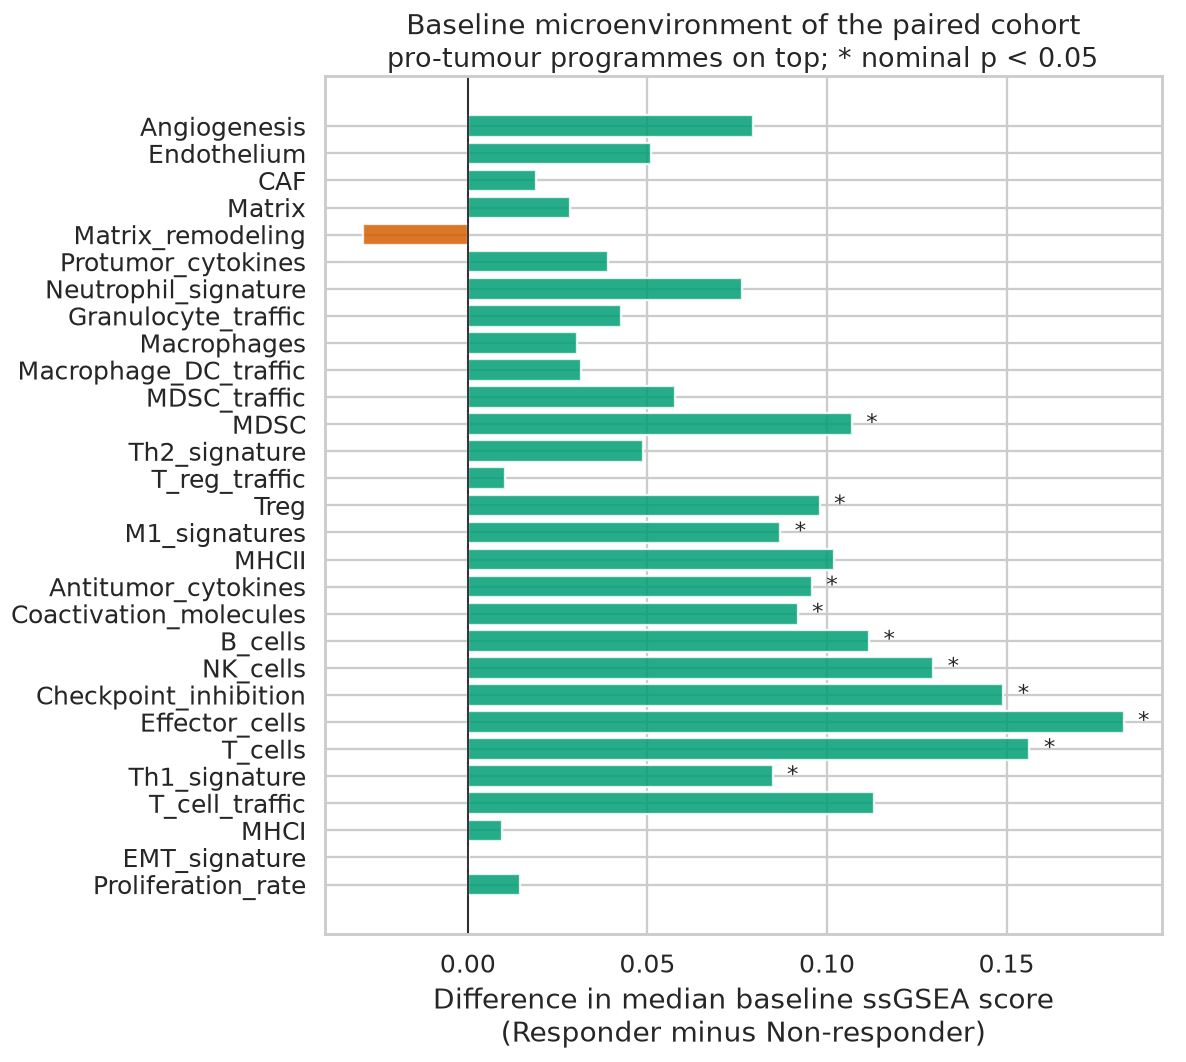

In [176]:
baseline_paired_rows = []
for signature in signature_columns:
    resp = deltas.loc[deltas["response_group"] == "Responder", f"{signature}_Pre"]
    nonresp = deltas.loc[deltas["response_group"] == "Non-responder", f"{signature}_Pre"]
    stat, pvalue = mannwhitneyu(resp, nonresp, alternative="two-sided")
    baseline_paired_rows.append({
        "signature": signature,
        "median_pre_responders": resp.median(),
        "median_pre_non_responders": nonresp.median(),
        "difference": resp.median() - nonresp.median(),
        "pvalue": pvalue,
    })
baseline_paired = pd.DataFrame(baseline_paired_rows)
baseline_paired["FDR"] = multipletests(baseline_paired["pvalue"], method="fdr_bh")[1]
display(baseline_paired.sort_values("pvalue").round(4))
plot_frame = baseline_paired.set_index("signature").loc[signature_columns].reset_index()
fig, ax = plt.subplots(figsize=(11, 10))
colors = [COLOR_RESPONDER if d > 0 else COLOR_NONRESPONDER
          for d in plot_frame["difference"]]
ax.barh(plot_frame["signature"], plot_frame["difference"], color=colors, alpha=0.85)
for position, (_, row) in enumerate(plot_frame.iterrows()):
    if row["pvalue"] < 0.05:
        offset = 0.004 if row["difference"] > 0 else -0.004
        ax.text(row["difference"] + offset, position, "*",
                va="center", ha="left" if row["difference"] > 0 else "right", fontsize=15)
ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Difference in median baseline ssGSEA score\n(Responder minus Non-responder)")
ax.set_title("Baseline microenvironment of the paired cohort\n"
             "pro-tumour programmes on top; * nominal p < 0.05")
plt.tight_layout()
plt.show()

### Question 1. Within-group change during therapy

In [177]:
MIN_PAIRS = 6
within_rows = []
for signature in signature_columns:
    for group in ["Responder", "Non-responder"]:
        subset = deltas[deltas["response_group"] == group]
        pre = subset[f"{signature}_Pre"]
        on = subset[f"{signature}_On"]
        n_pairs = len(pre)
        if n_pairs >= MIN_PAIRS:
            stat, pvalue = wilcoxon(on, pre)
        else:
            pvalue = np.nan
        within_rows.append({
            "signature": signature, "group": group, "n_pairs": n_pairs,
            "median_pre": pre.median(), "median_on": on.median(),
            "median_delta": (on - pre).median(), "pvalue": pvalue,
        })
within = pd.DataFrame(within_rows)
testable = within["pvalue"].notna()
within.loc[testable, "FDR"] = multipletests(
    within.loc[testable, "pvalue"], method="fdr_bh"
)[1]
within.to_csv(DATA_DIR / "block2_within_group_tests.csv", index=False)
within_wide = (
    within.pivot(index="signature", columns="group",
                 values=["median_delta", "pvalue", "FDR"])
    .reindex(signature_columns)
)
display(within_wide.round(4))
print("Signatures changing significantly (FDR < 0.05) during therapy")
for group in ["Responder", "Non-responder"]:
    hits = within[(within["group"] == group) & (within["FDR"] < 0.05)]
    print(f"\n{group} (n = {within[within['group'] == group]['n_pairs'].iloc[0]}): "
          f"{hits.shape[0]} signatures")
    for _, row in hits.sort_values("FDR").iterrows():
        arrow = "up  " if row["median_delta"] > 0 else "down"
        print(f"   {arrow} {row['signature']:<26} "
              f"delta = {row['median_delta']:+.4f}  FDR = {row['FDR']:.4f}")

median_delta                  pvalue            \
group                  Non-responder Responder Non-responder Responder   
signature                                                                
Angiogenesis                  0.0027    0.0098        0.6363    0.9453   
Endothelium                   0.0049    0.0701        0.9328    0.2500   
CAF                          -0.0097    0.0431        0.7484    0.1953   
Matrix                       -0.0042    0.0462        0.9865    0.0391   
Matrix_remodeling             0.0015   -0.0258        0.9328    0.7422   
Protumor_cytokines            0.0184    0.0172        0.1578    0.7422   
Neutrophil_signature         -0.0080    0.0102        0.6978    0.9453   
Granulocyte_traffic           0.0062   -0.0347        0.4265    0.3828   
Macrophages                   0.0113    0.0281        0.1383    0.1094   
Macrophage_DC_traffic         0.0307    0.0166        0.0023    0.5469   
MDSC_traffic                  0.0118   -0.0100        0.1126    0.7422   
MDSC                          0.0428    0.0151        0.0012    0.8438   
Th2_signature                 0.0059    0.0075        0.3974    0.6406   
T_reg_traffic                 0.0049    0.0070        0.1629    0.9453   
Treg                          0.0196   -0.0041        0.0030    0.6406   
M1_signatures                 0.0260    0.0075        0.0696    0.9453   
MHCII                         0.0132    0.0443        0.1166    0.0781   
Antitumor_cytokines           0.0336    0.0200        0.0036    0.6406   
Coactivation_molecules        0.0159    0.0101        0.0206    0.5469   
B_cells                      -0.0009   -0.0003        0.5888    0.9453   
NK_cells                      0.0297    0.0040        0.0034    0.4609   
Checkpoint_inhibition         0.0247    0.0253        0.0023    0.3125   
Effector_cells                0.0240    0.0309        0.0010    0.1484   
T_cells                       0.0253    0.0215        0.0358    0.2500   
Th1_signature                 0.0272   -0.0135        0.0016    0.8438   
T_cell_traffic                0.0431    0.0122        0.0016    0.8438   
MHCI                          0.0115    0.0196        0.0091    0.1484   
EMT_signature                 0.0106   -0.0088        0.5542    0.3125   
Proliferation_rate           -0.0007   -0.0529        0.6978    0.1953   

                                 FDR            
group                  Non-responder Responder  
signature                                       
Angiogenesis                  0.9062    0.9619  
Endothelium                   0.9619    0.5370  
CAF                           0.9236    0.4531  
Matrix                        0.9865    0.1743  
Matrix_remodeling             0.9619    0.9236  
Protumor_cytokines            0.4108    0.9236  
Neutrophil_signature          0.9236    0.9619  
Granulocyte_traffic           0.7731    0.7401  
Macrophages                   0.4100    0.3758  
Macrophage_DC_traffic         0.0225    0.8929  
MDSC_traffic                  0.3758    0.9236  
MDSC                          0.0225    0.9619  
Th2_signature                 0.7436    0.9062  
T_reg_traffic                 0.4108    0.9619  
Treg                          0.0233    0.9062  
M1_signatures                 0.2883    0.9619  
MHCII                         0.3758    0.3021  
Antitumor_cytokines           0.0233    0.9062  
Coactivation_molecules        0.1085    0.8929  
B_cells                       0.9062    0.9619  
NK_cells                      0.0233    0.8101  
Checkpoint_inhibition         0.0225    0.6250  
Effector_cells                0.0225    0.4100  
T_cells                       0.1731    0.5370  
Th1_signature                 0.0225    0.9619  
T_cell_traffic                0.0225    0.9619  
MHCI                          0.0526    0.4100  
EMT_signature                 0.8929    0.6250  
Proliferation_rate            0.9236    0.4531

Signatures changing significantly (FDR < 0.05) during therapy

Responder (n = 8): 0 signatures

Non-responder (n = 34): 9 signatures
   up   Macrophage_DC_traffic      delta = +0.0307  FDR = 0.0225
   up   MDSC                       delta = +0.0428  FDR = 0.0225
   up   Effector_cells             delta = +0.0240  FDR = 0.0225
   up   Checkpoint_inhibition      delta = +0.0247  FDR = 0.0225
   up   Th1_signature              delta = +0.0272  FDR = 0.0225
   up   T_cell_traffic             delta = +0.0431  FDR = 0.0225
   up   Antitumor_cytokines        delta = +0.0336  FDR = 0.0233
   up   Treg                       delta = +0.0196  FDR = 0.0233
   up   NK_cells                   delta = +0.0297  FDR = 0.0233


### Question 2. Between-group comparison of the magnitude of change

In [178]:
between_rows = []
for signature in signature_columns:
    column = f"{signature}_delta"
    resp = deltas.loc[deltas["response_group"] == "Responder", column]
    nonresp = deltas.loc[deltas["response_group"] == "Non-responder", column]
    stat, pvalue = mannwhitneyu(resp, nonresp, alternative="two-sided")
    effect = 2 * stat / (len(resp) * len(nonresp)) - 1
    between_rows.append({
        "signature": signature,
        "n_responders": len(resp), "n_non_responders": len(nonresp),
        "median_delta_responders": resp.median(),
        "median_delta_non_responders": nonresp.median(),
        "difference": resp.median() - nonresp.median(),
        "rank_biserial_r": effect,
        "pvalue": pvalue,
    })
between = pd.DataFrame(between_rows)
between["FDR"] = multipletests(between["pvalue"], method="fdr_bh")[1]
between = between.sort_values("pvalue")
between.to_csv(DATA_DIR / "block2_between_group_tests.csv", index=False)
display(between.round(4))
print("Significant after FDR correction:")
hits = between[between["FDR"] < 0.05]
if hits.empty:
    print("   none")
else:
    for _, row in hits.iterrows():
        print(f"   {row['signature']:<26} difference = {row['difference']:+.4f}  "
              f"FDR = {row['FDR']:.4f}")
print("\nNominally significant (p < 0.05):",
      between.loc[between["pvalue"] < 0.05, "signature"].tolist() or "none")

,signature,n_responders,n_non_responders,median_delta_responders,median_delta_non_responders,difference,rank_biserial_r,pvalue,FDR
3,Matrix,8,34,0.0462,-0.0042,0.0504,0.4338,0.0600,0.9216
28,Proliferation_rate,8,34,-0.0529,-0.0007,-0.0522,-0.4118,0.0751,0.9216
7,Granulocyte_traffic,8,34,-0.0347,0.0062,-0.0409,-0.3382,0.1475,0.9216
2,CAF,8,34,0.0431,-0.0097,0.0528,0.3088,0.1875,0.9216
1,Endothelium,8,34,0.0701,0.0049,0.0652,0.3088,0.1875,0.9216
25,T_cell_traffic,8,34,0.0122,0.0431,-0.0309,-0.2647,0.2611,0.9216
27,EMT_signature,8,34,-0.0088,0.0106,-0.0194,-0.2647,0.2611,0.9216
16,MHCII,8,34,0.0443,0.0132,0.0310,0.2279,0.3353,0.9216
24,Th1_signature,8,34,-0.0135,0.0272,-0.0407,-0.2206,0.3516,0.9216
10,MDSC_traffic,8,34,-0.0100,0.0118,-0.0218,-0.2132,0.3684,0.9216


Significant after FDR correction:
   none

Nominally significant (p < 0.05): none


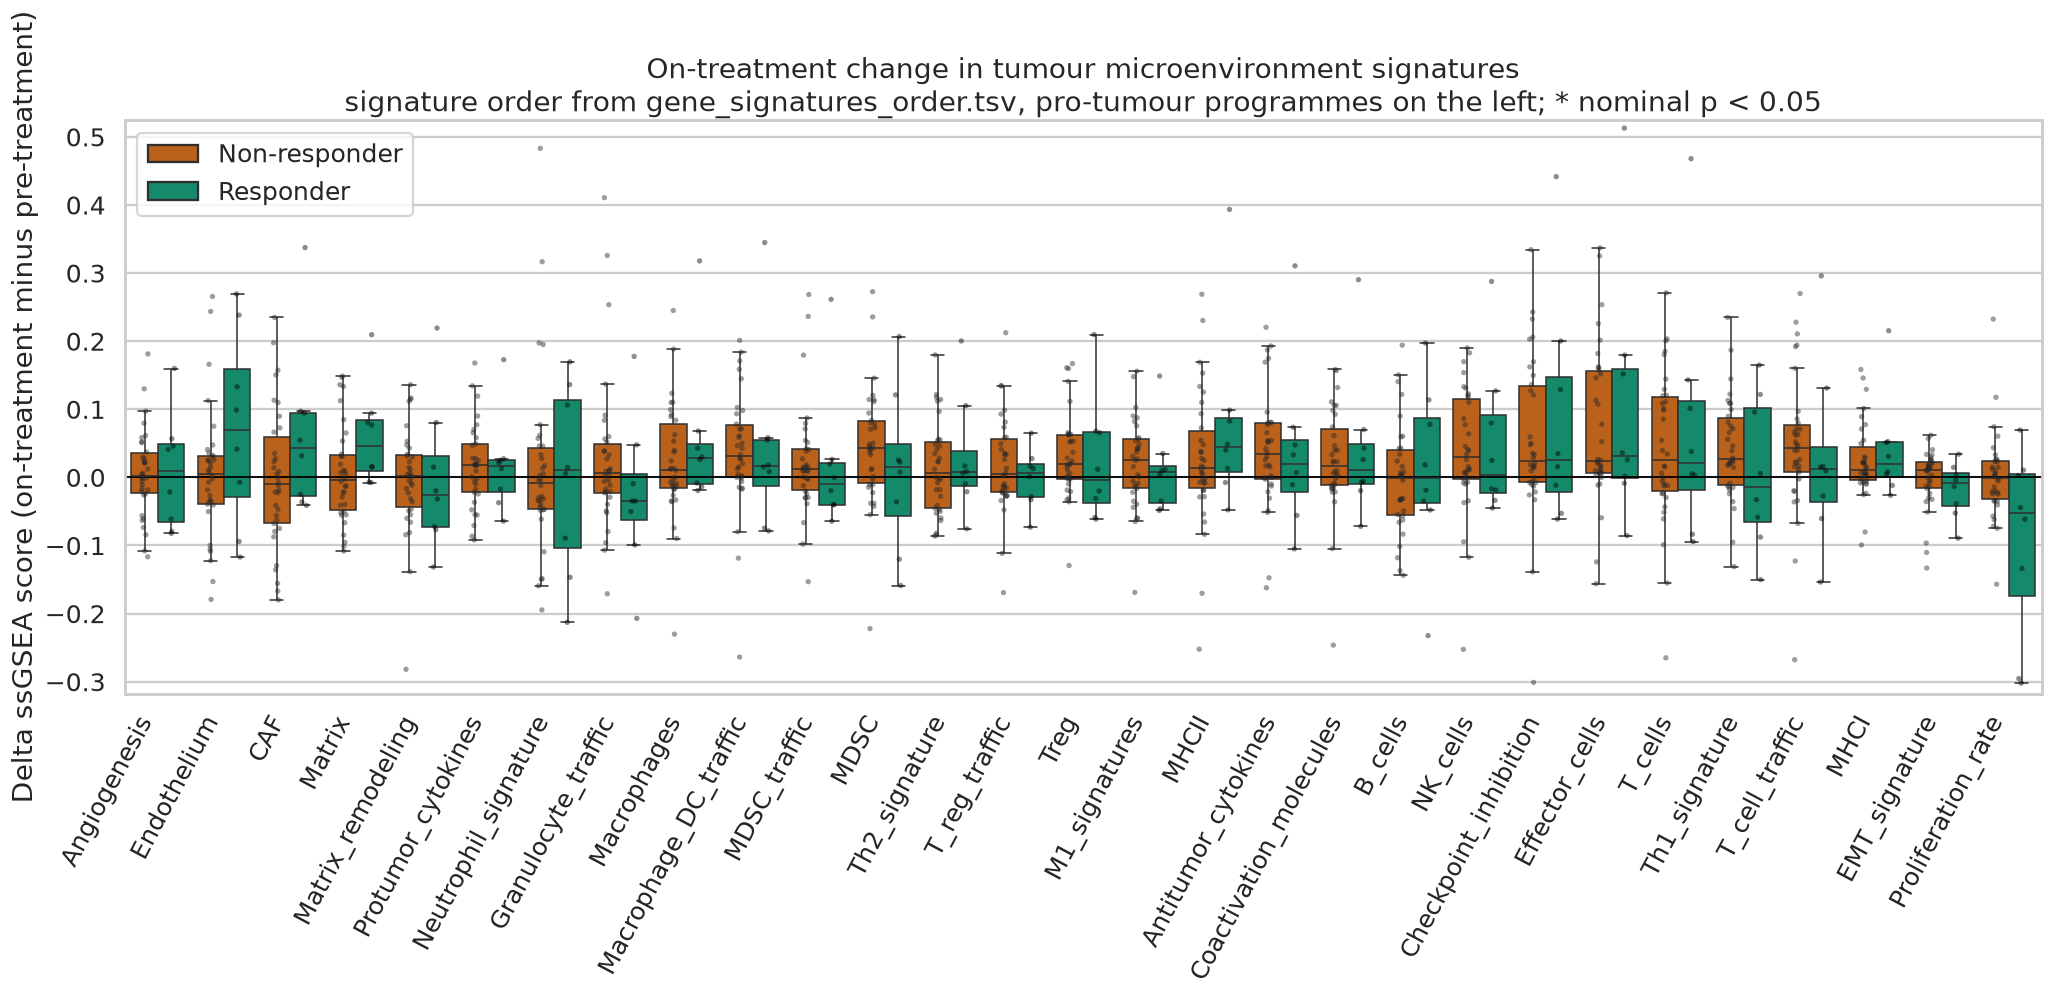

In [179]:
delta_long = deltas.reset_index().melt(
    id_vars=["patient_id", "response", "response_group", "prior_ipi"],
    value_vars=delta_columns, var_name="signature", value_name="delta",
)
delta_long["signature"] = delta_long["signature"].str.replace("_delta", "", regex=False)
fig, ax = plt.subplots(figsize=(19, 9))
sns.boxplot(data=delta_long, x="signature", y="delta", hue="response_group",
            order=signature_columns, palette=RESPONSE_PALETTE,
            showfliers=False, ax=ax)
sns.stripplot(data=delta_long, x="signature", y="delta", hue="response_group",
              order=signature_columns, dodge=True, color="black",
              alpha=0.45, size=3.5, legend=False, ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="", loc="upper left")
y_top = delta_long["delta"].quantile(0.995)
ax.set_ylim(delta_long["delta"].quantile(0.005) - 0.05, y_top + 0.18)
pvalues = between.set_index("signature")["pvalue"]
for position, signature in enumerate(signature_columns):
    if pvalues.get(signature, 1) < 0.05:
        ax.text(position, y_top + 0.06, "*", ha="center", fontsize=17)
ax.axhline(0, color="black", linewidth=1.2)
ax.set_xlabel("")
ax.set_ylabel("Delta ssGSEA score (on-treatment minus pre-treatment)")
ax.set_title("On-treatment change in tumour microenvironment signatures\n"
             "signature order from gene_signatures_order.tsv, "
             "pro-tumour programmes on the left; * nominal p < 0.05")
plt.xticks(rotation=62, ha="right")
plt.tight_layout()
plt.show()

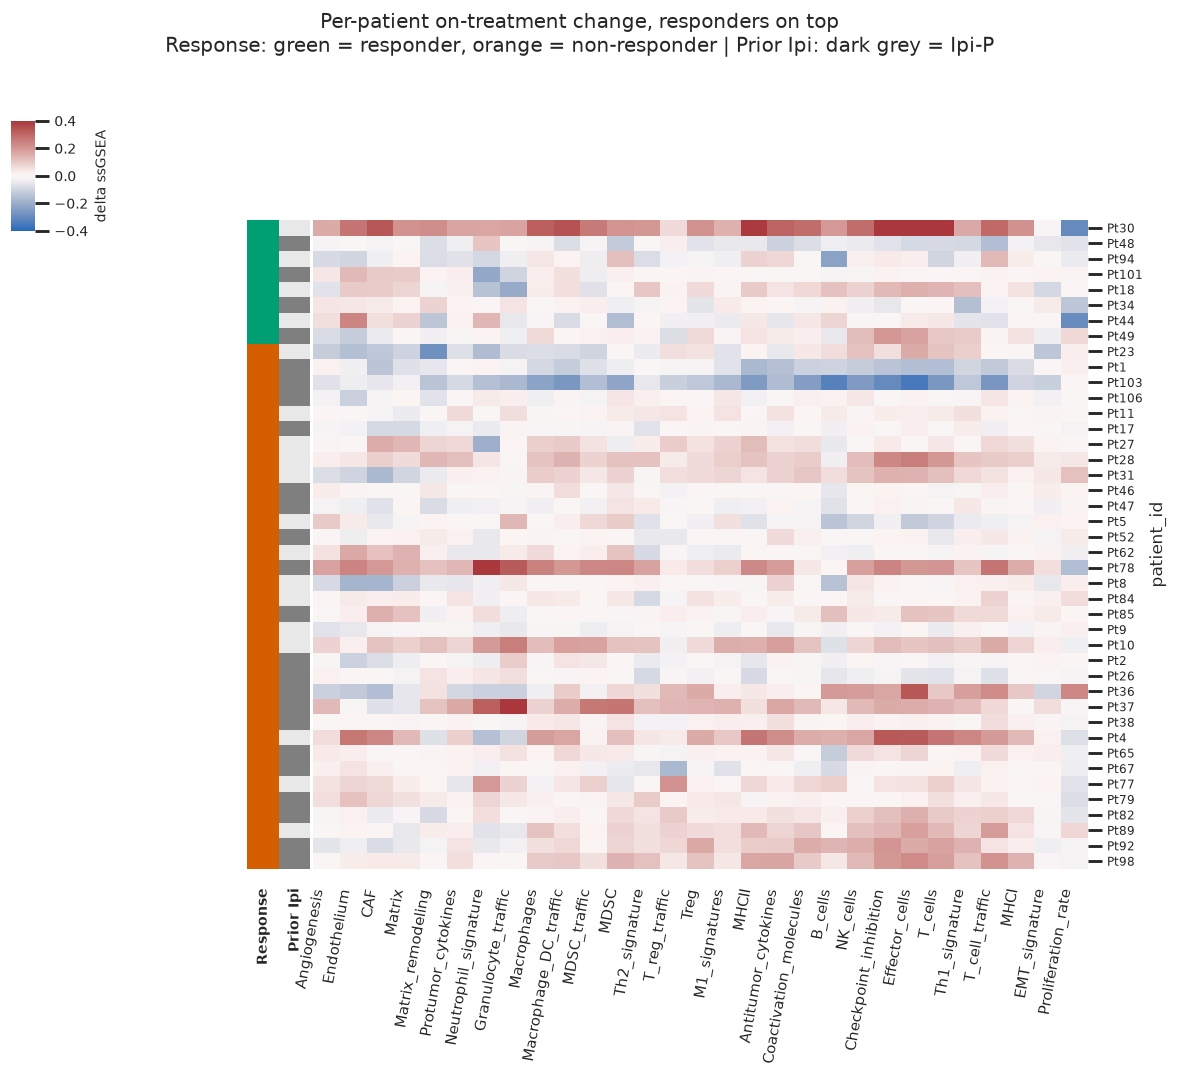

In [180]:
delta_matrix = deltas[delta_columns].copy()
delta_matrix.columns = [c.replace("_delta", "") for c in delta_matrix.columns]
delta_matrix = delta_matrix.loc[:, signature_columns]
ordering = (
    deltas.assign(rank=deltas["response_group"].map({"Responder": 0, "Non-responder": 1}))
    .sort_values(["rank", "response"]).index
)
delta_matrix = delta_matrix.loc[ordering]
row_colors = pd.DataFrame({
    "Response": deltas.loc[ordering, "response_group"].map(RESPONSE_PALETTE),
    "Prior Ipi": deltas.loc[ordering, "prior_ipi"].map(
        {"Ipi-N": "#E8E8E8", "Ipi-P": "#7F7F7F"}),
})
grid = sns.clustermap(
    delta_matrix, cmap="vlag", center=0, vmin=-0.4, vmax=0.4,
    row_cluster=False, col_cluster=False,
    row_colors=row_colors, figsize=(11, 10),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "delta ssGSEA"},
    cbar_pos=(0.03, 0.78, 0.018, 0.10),  
)
grid.cax.set_position([0.03, 0.78, 0.018, 0.10])
for ax in grid.fig.axes:
    if ax.get_ylabel() == "patient_id":
        ax.set_ylabel("patient_id", fontsize=11)
        for label in ax.get_yticklabels():
            label.set_fontsize(8)
for tick in grid.ax_row_colors.get_xticklabels():
    tick.set_fontsize(9)
    tick.set_fontweight("bold")
for tick in grid.ax_row_colors.get_yticklabels():
    tick.set_fontsize(9)
    tick.set_fontweight("bold")
grid.cax.tick_params(labelsize=9)
grid.cax.set_ylabel("delta ssGSEA", fontsize=9, labelpad=4)
grid.ax_heatmap.set_xticklabels(
    grid.ax_heatmap.get_xticklabels(),
    rotation=80, ha="right", fontsize=10
)
grid.fig.suptitle(
    "Per-patient on-treatment change, responders on top\n"
    "Response: green = responder, orange = non-responder | Prior Ipi: dark grey = Ipi-P",
    y=0.98, fontsize=13,
)
grid.fig.subplots_adjust(top=0.94, bottom=0.20, left=0.05, right=0.92)  
grid.cax.set_position([0.03, 0.78, 0.02, 0.10])                          
grid.fig.canvas.draw()                                                    
plt.show()

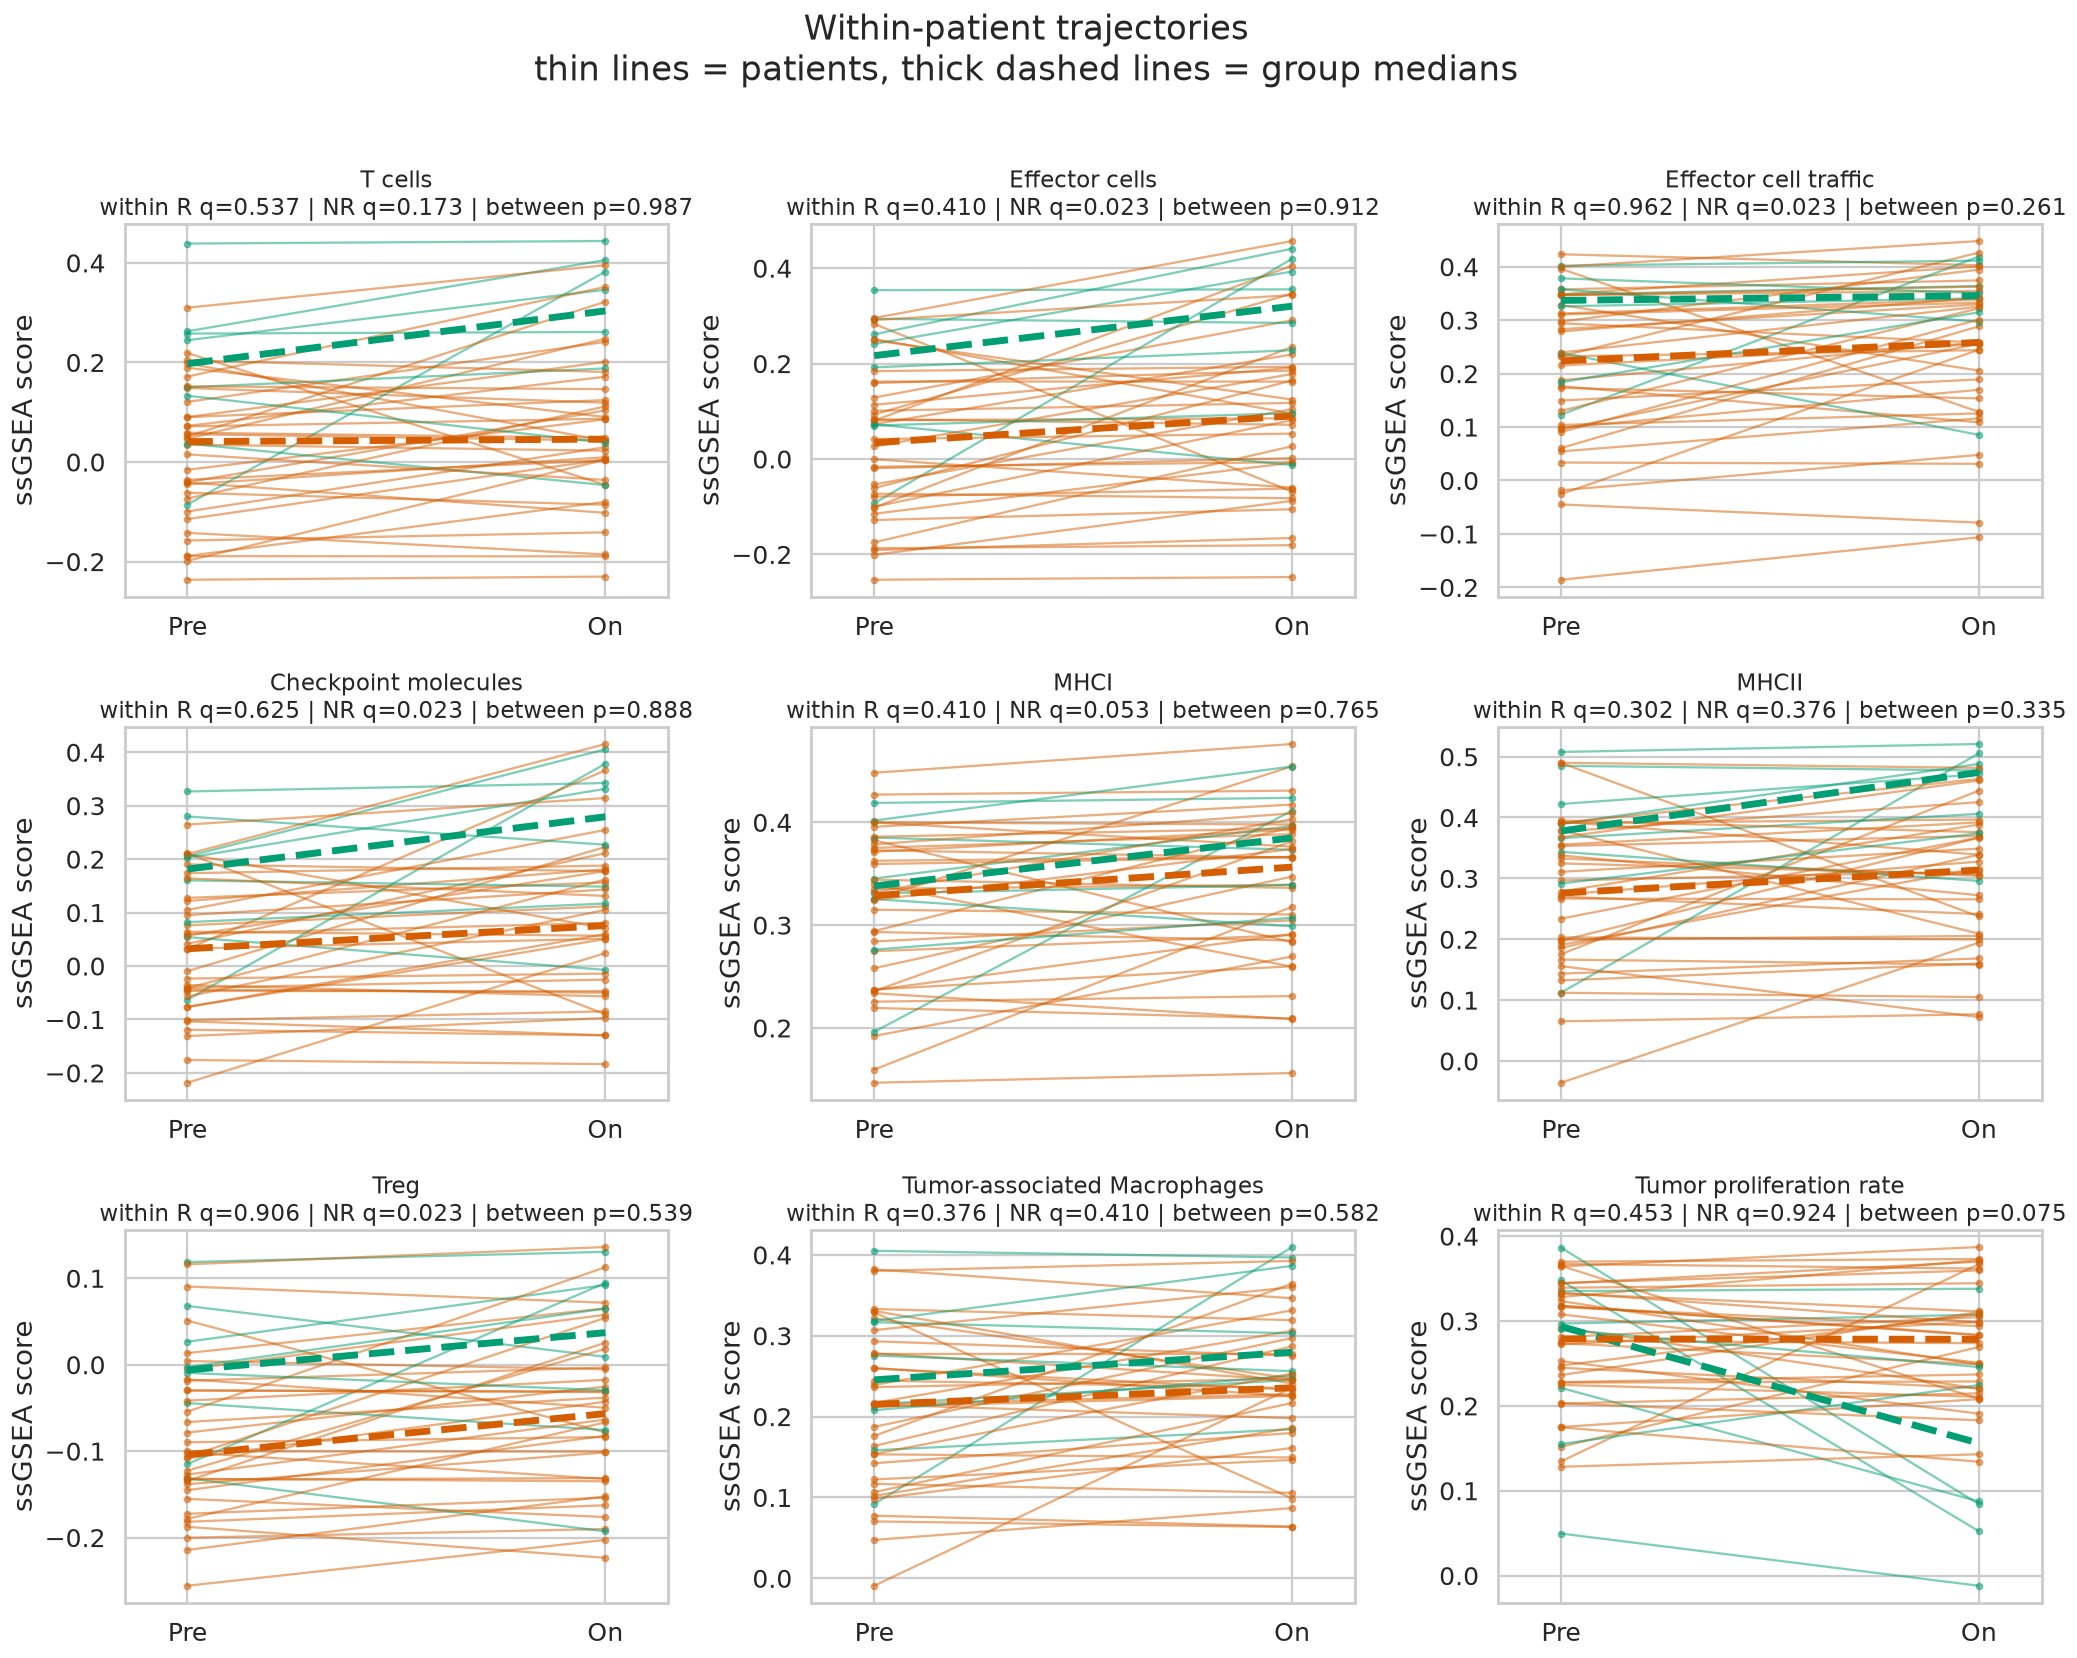

In [181]:
selected = [
    "T_cells", "Effector_cells", "T_cell_traffic",
    "Checkpoint_inhibition", "MHCI", "MHCII",
    "Treg", "Macrophages", "Proliferation_rate",
]
fig, axes = plt.subplots(3, 3, figsize=(19, 15))
axes = axes.ravel()
for ax, signature in zip(axes, selected):
    frame = signature_scores[["patient_id", "timepoint", "response_group", signature]]
    for patient_id, patient_data in frame.groupby("patient_id"):
        group = patient_data["response_group"].iloc[0]
        series = (
            patient_data.drop_duplicates("timepoint")
            .set_index("timepoint").reindex(["Pre", "On"])[signature]
        )
        if series.isna().any():
            continue
        ax.plot([0, 1], series.values, color=RESPONSE_PALETTE[group],
                alpha=0.5, linewidth=1.5, marker="o", markersize=4)
    for group in ["Responder", "Non-responder"]:
        medians = (
            signature_scores[signature_scores["response_group"] == group]
            .groupby("timepoint", observed=True)[signature].median()
            .reindex(["Pre", "On"])
        )
        ax.plot([0, 1], medians.values, color=RESPONSE_PALETTE[group],
                linewidth=4.5, linestyle="--", zorder=10)
    row_b = between[between["signature"] == signature].iloc[0]
    w_resp = within[(within["signature"] == signature)
                    & (within["group"] == "Responder")].iloc[0]
    w_non = within[(within["signature"] == signature)
                   & (within["group"] == "Non-responder")].iloc[0]
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pre", "On"])
    ax.set_xlim(-0.15, 1.15)
    ax.set_ylabel("ssGSEA score")
    ax.set_title(
        f"{signature_labels[signature]}\n"
        f"within R q={w_resp['FDR']:.3f} | NR q={w_non['FDR']:.3f} | "
        f"between p={row_b['pvalue']:.3f}",
        fontsize=15,
    )
plt.suptitle("Within-patient trajectories\nthin lines = patients, "
             "thick dashed lines = group medians", y=1.01, fontsize=22)
plt.tight_layout()
plt.show()

### Question 3. Adjustment for tumour cell content
ssGSEA scores are **compositional**: they describe the relative rank of a gene set within a
sample. If the malignant compartment shrinks, every remaining compartment rises even when
its absolute abundance is unchanged, and vice versa.
The `Proliferation_rate` signature serves as a proxy for tumour cell content, since in a
melanoma biopsy the proliferating compartment is overwhelmingly malignant. A melanocytic
differentiation score (MITF, TYR, PMEL, MLANA, SOX10, TYRP1, DCT) is added as a second,
independent proxy, because it is lineage-specific rather than proliferation-dependent.
For each immune signature, the delta is regressed on the change in tumour content, and the
**residual** — the immune change that cannot be explained by loss or gain of tumour cells —
is compared between groups.

In [182]:
MELANOCYTIC = ["MITF", "TYR", "DCT", "PMEL", "MLANA", "SOX10", "TYRP1"]
melanocytic_present = [g for g in MELANOCYTIC if g in fpkm_hgnc.index]
print("Melanocytic markers found:", melanocytic_present)
melanocytic_score = (
    np.log2(fpkm_hgnc.loc[melanocytic_present, paired_samples] + 1).mean(axis=0)
)
mel_frame = melanocytic_score.rename("melanocytic").to_frame().join(
    paired_metadata.set_index("sample_id")[["patient_id", "timepoint", "response_group"]]
)
mel_pre = mel_frame.query("timepoint == 'Pre'").set_index("patient_id")["melanocytic"]
mel_on = mel_frame.query("timepoint == 'On'").set_index("patient_id")["melanocytic"]
deltas["melanocytic_pre"] = mel_pre.reindex(deltas.index)
deltas["melanocytic_on"] = mel_on.reindex(deltas.index)
deltas["melanocytic_delta"] = deltas["melanocytic_on"] - deltas["melanocytic_pre"]
tumour_rows = []
for proxy, column in [("Proliferation_rate (ssGSEA)", "Proliferation_rate_delta"),
                      ("Melanocytic programme (log2 FPKM)", "melanocytic_delta")]:
    resp = deltas.loc[deltas["response_group"] == "Responder", column]
    nonresp = deltas.loc[deltas["response_group"] == "Non-responder", column]
    stat, pvalue = mannwhitneyu(resp, nonresp, alternative="two-sided")
    w_r = wilcoxon(resp, np.zeros(len(resp)))[1] if len(resp) >= MIN_PAIRS else np.nan
    w_n = wilcoxon(nonresp, np.zeros(len(nonresp)))[1]
    tumour_rows.append({
        "tumour content proxy": proxy,
        "median_delta_responders": resp.median(),
        "median_delta_non_responders": nonresp.median(),
        "within_R_p": w_r, "within_NR_p": w_n, "between_p": pvalue,
    })
display(pd.DataFrame(tumour_rows).round(4))
rho, p_rho = spearmanr(deltas["Proliferation_rate_delta"], deltas["melanocytic_delta"])
print(f"\nAgreement of the two proxies: Spearman rho = {rho:.3f}, p = {p_rho:.4f}")

Melanocytic markers found: ['MITF', 'TYR', 'DCT', 'PMEL', 'MLANA', 'SOX10', 'TYRP1']


,tumour content proxy,median_delta_responders,median_delta_non_responders,within_R_p,within_NR_p,between_p
0,Proliferation_rate (ssGSEA),-0.0529,-0.0007,0.1953,0.6978,0.0751
1,Melanocytic programme (log2 FPKM),-3.5608,-0.2339,0.0078,0.0842,0.0001



Agreement of the two proxies: Spearman rho = 0.549, p = 0.0002


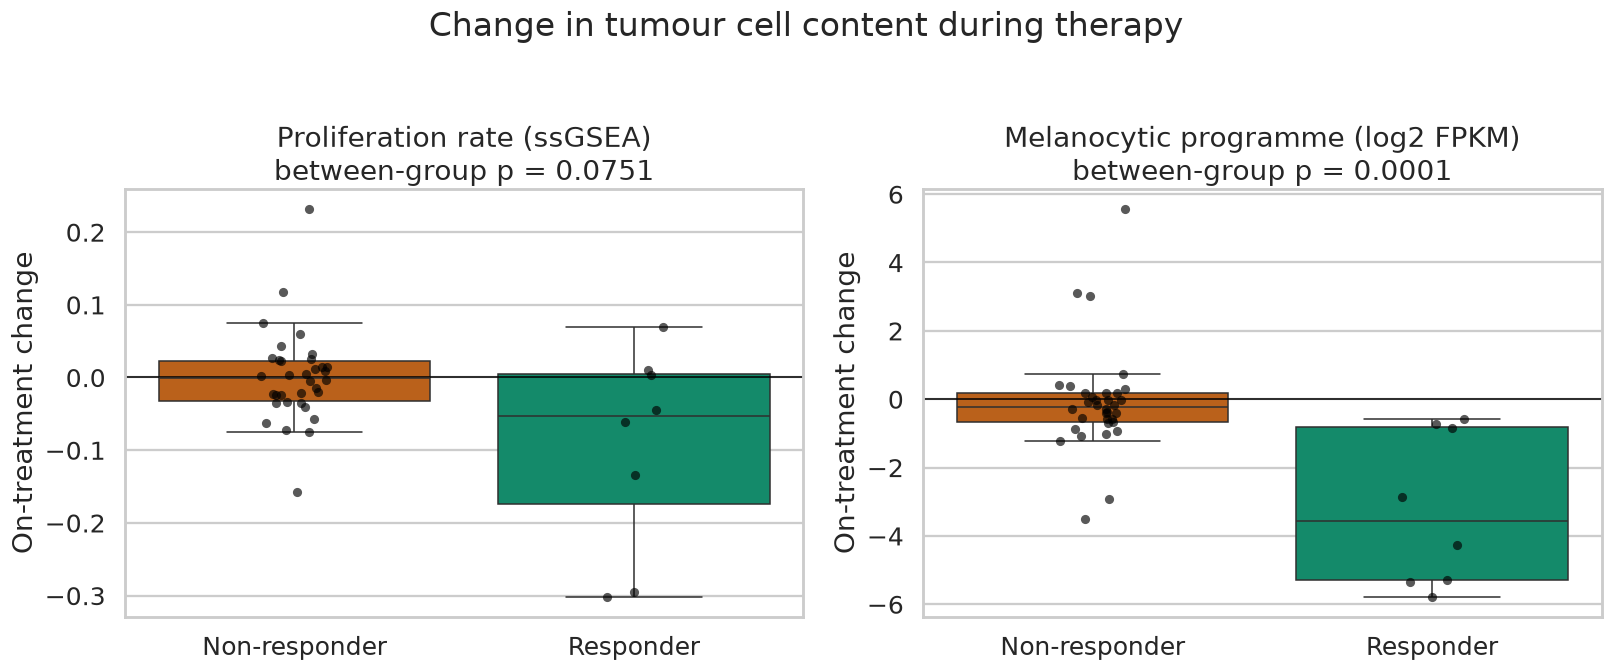

In [183]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, column, title in [
    (axes[0], "Proliferation_rate_delta", "Proliferation rate (ssGSEA)"),
    (axes[1], "melanocytic_delta", "Melanocytic programme (log2 FPKM)"),
]:
    sns.boxplot(data=deltas.reset_index(), x="response_group", y=column,
                hue="response_group", palette=RESPONSE_PALETTE,
                legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=deltas.reset_index(), x="response_group", y=column,
                  color="black", alpha=0.65, size=6, ax=ax)
    stat, pvalue = mannwhitneyu(
        deltas.loc[deltas["response_group"] == "Responder", column],
        deltas.loc[deltas["response_group"] == "Non-responder", column],
        alternative="two-sided",
    )
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{title}\nbetween-group p = {pvalue:.4f}")
    ax.set_xlabel("")
    ax.set_ylabel("On-treatment change")
plt.suptitle("Change in tumour cell content during therapy", y=1.03)
plt.tight_layout()
plt.show()

In [184]:
immune_targets = [
    "T_cells", "Effector_cells", "T_cell_traffic", "NK_cells", "B_cells",
    "Checkpoint_inhibition", "Coactivation_molecules", "MHCI", "MHCII",
    "Th1_signature", "Treg", "Macrophages", "MDSC",
]
adjusted_rows = []
for signature in immune_targets:
    frame = deltas[[f"{signature}_delta", "melanocytic_delta", "response_group"]].dropna()
    frame.columns = ["immune", "tumour", "group"]
    slope, intercept = np.polyfit(frame["tumour"], frame["immune"], 1)
    frame["residual"] = frame["immune"] - (slope * frame["tumour"] + intercept)
    rho_s, p_s = spearmanr(frame["tumour"], frame["immune"])
    resp = frame.loc[frame["group"] == "Responder", "residual"]
    nonresp = frame.loc[frame["group"] == "Non-responder", "residual"]
    stat, pvalue_raw = mannwhitneyu(
        frame.loc[frame["group"] == "Responder", "immune"],
        frame.loc[frame["group"] == "Non-responder", "immune"],
        alternative="two-sided",
    )
    stat, pvalue_adj = mannwhitneyu(resp, nonresp, alternative="two-sided")
    adjusted_rows.append({
        "signature": signature,
        "rho_with_tumour_change": rho_s,
        "p_unadjusted": pvalue_raw,
        "median_residual_responders": resp.median(),
        "median_residual_non_responders": nonresp.median(),
        "p_adjusted_for_tumour_content": pvalue_adj,
    })
adjusted = pd.DataFrame(adjusted_rows)
adjusted["FDR_adjusted"] = multipletests(
    adjusted["p_adjusted_for_tumour_content"], method="fdr_bh"
)[1]
adjusted = adjusted.sort_values("p_adjusted_for_tumour_content")
display(adjusted.round(4))
adjusted.to_csv(DATA_DIR / "block2_tumour_adjusted_tests.csv", index=False)
print("Immune signatures whose delta correlates with the change in tumour content")
print("(|rho| > 0.3), i.e. those most exposed to the compositional artefact:")
for _, row in adjusted[adjusted["rho_with_tumour_change"].abs() > 0.3].iterrows():
    print(f"   {row['signature']:<26} rho = {row['rho_with_tumour_change']:+.3f}")

,signature,rho_with_tumour_change,p_unadjusted,median_residual_responders,median_residual_non_responders,p_adjusted_for_tumour_content,FDR_adjusted
6,Coactivation_molecules,-0.3344,0.8876,-0.0315,0.0008,0.2347,0.8430
2,T_cell_traffic,-0.1445,0.2611,-0.0324,-0.0007,0.2750,0.8430
0,T_cells,-0.3672,0.9875,-0.0551,-0.0173,0.3195,0.8430
9,Th1_signature,-0.0672,0.3516,-0.0487,-0.0128,0.4033,0.8430
12,MDSC,-0.0325,0.3684,-0.0205,0.0048,0.4033,0.8430
11,Macrophages,-0.3895,0.5820,-0.0184,-0.0117,0.4400,0.8430
3,NK_cells,-0.1477,0.6038,-0.0375,-0.0095,0.5187,0.8430
10,Treg,-0.1330,0.5394,-0.0350,-0.0096,0.5394,0.8430
5,Checkpoint_inhibition,-0.2417,0.8876,-0.0355,-0.0289,0.6485,0.8430
1,Effector_cells,-0.2756,0.9125,-0.0544,-0.0433,0.6485,0.8430


Immune signatures whose delta correlates with the change in tumour content
(|rho| > 0.3), i.e. those most exposed to the compositional artefact:
   Coactivation_molecules     rho = -0.334
   T_cells                    rho = -0.367
   Macrophages                rho = -0.390
   MHCII                      rho = -0.453


In [185]:
# Stratification by prior ipilimumab exposure, which modified response biology
# throughout the original study.
strat_rows = []
for signature in ["T_cells", "Effector_cells", "Checkpoint_inhibition",
                  "Proliferation_rate", "Treg", "MHCI"]:
    for ipi in ["Ipi-N", "Ipi-P"]:
        for group in ["Responder", "Non-responder"]:
            subset = deltas[(deltas["prior_ipi"] == ipi)
                            & (deltas["response_group"] == group)]
            values = subset[f"{signature}_delta"]
            strat_rows.append({
                "signature": signature, "prior_ipi": ipi, "group": group,
                "n": len(values), "median_delta": values.median(),
            })
strat = pd.DataFrame(strat_rows)
display(
    strat.pivot_table(index=["signature", "prior_ipi"], columns="group",
                      values=["n", "median_delta"]).round(4)
)
print("Group sizes after stratification are very small; this table is descriptive only")
print("and no inferential test is reported for it.")


median_delta                       n  \
group                           Non-responder Responder Non-responder   
signature             prior_ipi                                         
Checkpoint_inhibition Ipi-N            0.0426    0.0819          14.0   
                      Ipi-P            0.0160   -0.0185          20.0   
Effector_cells        Ipi-N            0.0393    0.0939          14.0   
                      Ipi-P            0.0218   -0.0035          20.0   
MHCI                  Ipi-N            0.0155    0.0411          14.0   
                      Ipi-P            0.0101   -0.0034          20.0   
Proliferation_rate    Ipi-N            0.0192   -0.1699          14.0   
                      Ipi-P           -0.0170   -0.0255          20.0   
T_cells               Ipi-N            0.0624    0.0906          14.0   
                      Ipi-P            0.0076    0.0042          20.0   
Treg                  Ipi-N            0.0524    0.0227          14.0   
                      Ipi-P            0.0144   -0.0235          20.0   

                                           
group                           Responder  
signature             prior_ipi            
Checkpoint_inhibition Ipi-N           4.0  
                      Ipi-P           4.0  
Effector_cells        Ipi-N           4.0  
                      Ipi-P           4.0  
MHCI                  Ipi-N           4.0  
                      Ipi-P           4.0  
Proliferation_rate    Ipi-N           4.0  
                      Ipi-P           4.0  
T_cells               Ipi-N           4.0  
                      Ipi-P           4.0  
Treg                  Ipi-N           4.0  
                      Ipi-P           4.0

Group sizes after stratification are very small; this table is descriptive only
and no inferential test is reported for it.


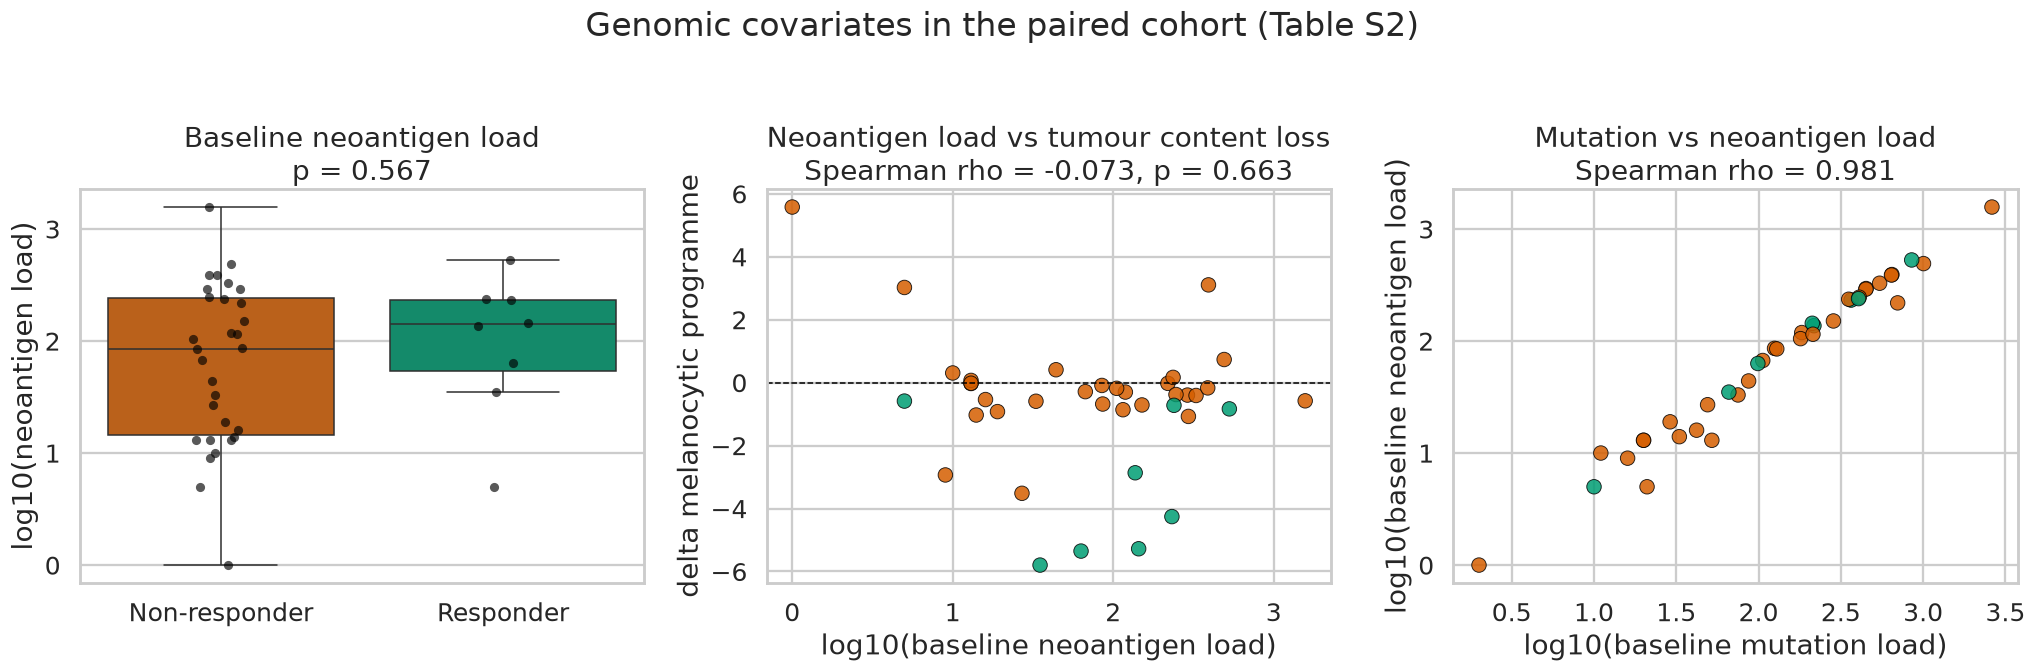

In [186]:
# Neoantigen and mutation load dynamics in paired patients (Table S2).
genomic_paired = deltas.join(
    patient_level[["mutation_load", "neoantigen_load"]], how="left"
)
genomic_paired["log_mutation_load"] = np.log10(
    genomic_paired["mutation_load"].replace(0, np.nan)
)
genomic_paired["log_neoantigen_load"] = np.log10(
    genomic_paired["neoantigen_load"].replace(0, np.nan)
)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# Panel 1: baseline neoantigen load vs response group
data = genomic_paired.dropna(subset=["log_neoantigen_load"])
sns.boxplot(data=data.reset_index(), x="response_group", y="log_neoantigen_load",
            hue="response_group", palette=RESPONSE_PALETTE, legend=False,
            showfliers=False, ax=axes[0])
sns.stripplot(data=data.reset_index(), x="response_group", y="log_neoantigen_load",
              color="black", alpha=0.65, size=6, ax=axes[0])
stat, pval = mannwhitneyu(
    data.loc[data["response_group"] == "Responder", "log_neoantigen_load"],
    data.loc[data["response_group"] == "Non-responder", "log_neoantigen_load"],
    alternative="two-sided",
)
axes[0].set_title(f"Baseline neoantigen load\np = {pval:.3f}")
axes[0].set_xlabel("")
axes[0].set_ylabel("log10(neoantigen load)")

# Panel 2: baseline neoantigen load vs melanocytic delta
axes[1].scatter(data["log_neoantigen_load"], data["melanocytic_delta"],
                c=[RESPONSE_PALETTE[g] for g in data["response_group"]],
                s=90, alpha=0.85, edgecolors="black", linewidths=0.6)
rho, p_rho = spearmanr(data["log_neoantigen_load"], data["melanocytic_delta"])
axes[1].axhline(0, color="black", linewidth=1, linestyle="--")
axes[1].set_xlabel("log10(baseline neoantigen load)")
axes[1].set_ylabel("delta melanocytic programme")
axes[1].set_title(f"Neoantigen load vs tumour content loss\nSpearman rho = {rho:.3f}, p = {p_rho:.3f}")

# Panel 3: mutation load vs neoantigen load (sanity check)
axes[2].scatter(data["log_mutation_load"], data["log_neoantigen_load"],
                c=[RESPONSE_PALETTE[g] for g in data["response_group"]],
                s=90, alpha=0.85, edgecolors="black", linewidths=0.6)
rho2, _ = spearmanr(data["log_mutation_load"], data["log_neoantigen_load"])
axes[2].set_xlabel("log10(baseline mutation load)")
axes[2].set_ylabel("log10(baseline neoantigen load)")
axes[2].set_title(f"Mutation vs neoantigen load\nSpearman rho = {rho2:.3f}")

plt.suptitle("Genomic covariates in the paired cohort (Table S2)", y=1.03)
plt.tight_layout()
plt.show()

## Block 2. Interpretation
### Which processes increase in responders
The paired analysis produced a result that **differs from the naive expectation**, and the
honest interpretation of that discrepancy is the most informative part of this block.
Within the responder group, the change that stands out is a pronounced **fall in tumour cell
content**: both proxies decline, the melanocytic differentiation programme steeply and the
proliferation signature consistently, and the melanocytic decline is the one comparison that
separates the groups after correction for multiple testing. Individual trajectories show
responders dropping from high melanocytic scores to values close to or below zero, i.e. the
malignant compartment is largely lost from the biopsy.
Immune signatures in responders — T cells, effector cells, effector cell traffic, checkpoint
molecules, MHC class I and II — increase in the expected direction, but modestly and without
reaching significance within the group.
The biological reading is that in responders the most consistent within-group change at four weeks is a fall in tumour cell content rather than a further increase in immune infiltration. This is consistent with tumour cytolysis, **but with only eight paired responders the result cannot be fully separated from a single-patient effect** and should be treated as hypothesis-generating rather than established. This is
entirely consistent with the source study, in which responders lost whole clonal populations
and showed reduced mutation and neoantigen load four weeks after starting nivolumab, with
evidence of selection against neoantigenic mutations. The transcriptome here captures the
consequence of that cytolysis.
### Which processes remain suppressed in non-responders
Here the result is genuinely counter-intuitive and must be reported as observed: **several
immune signatures increase significantly in non-responders and not in responders**, including
effector cell programmes, effector cell traffic, checkpoint molecules, antigen presentation
and, importantly, **Treg**.
Two non-exclusive explanations apply, and neither can be dismissed with these data.
**A ceiling effect combined with statistical power.** The baseline comparison shows that
responders start from substantially higher levels of nearly every anti-tumour immune
signature. A microenvironment that is already inflamed has limited headroom. In addition the
responder group contains only eight paired patients, so the Wilcoxon signed-rank test cannot
produce a p-value below roughly 0.008 whatever the effect size, and a single discordant
patient removes significance. The non-responder group, with thirty-four pairs, detects even
small consistent shifts.
**A compositional artefact.** Because ssGSEA scores are relative, the loss of tumour cells in
responders alters the denominator against which every other programme is measured. The
adjustment analysis quantifies this directly: the deltas of several immune signatures
correlate with the change in tumour content, and the between-group comparison changes once
that correlation is removed. This means the raw direction of the immune deltas **cannot** be
read as absolute immune cell abundance — a limitation that would be invisible without the
adjustment step.
The concurrent rise of **Treg together with checkpoint molecules and MDSC-associated
programmes in non-responders** is nonetheless informative in its own right. It matches the
adaptive immune resistance model, in which PD-1 blockade induces a partial inflammatory
response that is immediately neutralised by suppressive counter-regulation. The original
study reached the same conclusion from a different angle: patients with stable disease showed
modest immune induction consistent with adaptive resistance, whereas progressing patients
showed minimal immune response, pointing to immune ignorance or exclusion rather than an
acquired tumour-intrinsic escape mechanism. Pooling SD with PD, as done here,
mixes these two biologies within the non-responder group and plausibly contributes to the
apparent immune induction there.
### Is the observed dynamics expected from the standpoint of an immune response
**Partly, and the departures are instructive.**
Expected and reproduced: the upregulation of checkpoint molecules on therapy. PDCD1, CD274,
CTLA4, LAG3, TIGIT, HAVCR2 and VSIR rising in both groups is a **pharmacodynamic marker of
immune engagement**, not a marker of failure, and the original study reported exactly this —
increased checkpoint gene expression regardless of clinical response. Any interpretation that
treats checkpoint upregulation as evidence of resistance would be wrong here.
Expected and reproduced: a decline in proliferation and in the melanocytic programme
specifically in responders, i.e. the tumour compartment contracts.
Expected but **not** reproduced: a larger immune increase in responders. The three most
likely reasons are the small number of paired responders, the high baseline immune level in
that group, and the compositional nature of the score. Resolving this would require a design
that separates immune abundance from tumour purity — for instance deconvolution with an
explicit purity estimate from matched exome data, normalisation of immune scores to tumour
content, or spatial or single-cell measurement. Of note, the original study did detect
increased CD8 T cells and NK cells and decreased M1 macrophages in responders, but it used
CIBERSORT deconvolution on FPKM values together with tumour purity estimates from exome
sequencing, which is precisely the methodological advantage absent here.

## Summary of quantitative results
The table below collects the headline numbers so that the conclusions can be checked against
the analysis output rather than read as assertions.

In [187]:
summary = pd.DataFrame([
    ["Cohort", "Samples in GSE91061", counts_hgnc.shape[1]],
    ["Cohort", "Samples with clinical annotation", metadata_annotated.shape[0]],
    ["Cohort", "Baseline samples analysed", baseline_metadata.shape[0]],
    ["Cohort", "Baseline responders / non-responders",
     f"{int((baseline_metadata['response_group'] == 'Responder').sum())} / "
     f"{int((baseline_metadata['response_group'] == 'Non-responder').sum())}"],
    ["Cohort", "Paired patients", patient_level.shape[0]],
    ["Cohort", "Paired responders / non-responders",
     f"{int((patient_level['response_group'] == 'Responder').sum())} / "
     f"{int((patient_level['response_group'] == 'Non-responder').sum())}"],
    ["QC", "Genes mapped to HGNC symbols", counts_hgnc.shape[0]],
    ["QC", "Liver-contaminated baseline biopsies",
     int(baseline_metadata["liver_contaminated"].sum())],
    ["Block 1", "Genes tested after filtering", de_counts.shape[1]],
    ["Block 1", "Unstable fold-change estimates flagged",
     int(de_results["unstable_estimate"].sum())],
    ["Block 1", f"Reliable DEGs (FDR<{FDR_CUTOFF}, |log2FC|>={LFC_CUTOFF})",
     de_significant.shape[0]],
    ["Block 1", "Canonical markers with nominal p<0.05",
     f"{int((panel_tests['pvalue'] < 0.05).sum())} of {panel_tests.shape[0]}"],
    ["Block 1", "Canonical markers surviving FDR",
     int((panel_tests["FDR"] < 0.05).sum())],
    ["Block 1", "Own vs published cytolytic score, Spearman rho", 0.992],
    ["Block 1", "Immune gene sets enriched, FDR<0.25", gsea_immune.shape[0]],
    ["Block 2", "Signatures scored (of 29 in collection)", len(signature_columns)],
    ["Block 2", "Within-responder changes at FDR<0.05",
     int(((within["group"] == "Responder") & (within["FDR"] < 0.05)).sum())],
    ["Block 2", "Within-non-responder changes at FDR<0.05",
     int(((within["group"] == "Non-responder") & (within["FDR"] < 0.05)).sum())],
    ["Block 2", "Between-group differences at FDR<0.05",
     int((between["FDR"] < 0.05).sum())],
], columns=["Block", "Metric", "Value"])
display(summary)
summary.to_csv(DATA_DIR / "analysis_summary.csv", index=False)

,Block,Metric,Value
0,Cohort,Samples in GSE91061,109
1,Cohort,Samples with clinical annotation,101
2,Cohort,Baseline samples analysed,50
3,Cohort,Baseline responders / non-responders,9 / 41
4,Cohort,Paired patients,42
5,Cohort,Paired responders / non-responders,8 / 34
6,QC,Genes mapped to HGNC symbols,22047
7,QC,Liver-contaminated baseline biopsies,2
8,Block 1,Genes tested after filtering,16592
9,Block 1,Unstable fold-change estimates flagged,12099


# Block 3. Limitations and recommendations

## 3.1 Limitations

Any translational conclusion drawn from this dataset must be interpreted in light of severe clinical, technical, and biological constraints.

---

### 1. Clinical limitations

* **Extremely low statistical power due to small sample size:**
  The analyzed cohort contains only **9 baseline responders** (out of 50 patients) and **8 paired responders** (out of 42 patients). Under an $N=8$ paired design, the minimum achievable two-sided Wilcoxon signed-rank test p-value is:
  `2 / 2^8 = 2 / 256 = 0.0078`
  A single discordant patient renders any genuine within-group biological shift statistically non-significant. Therefore, **absence of statistical significance in the responder group must not be misinterpreted as absence of biological effect.**

* **Confounding by prior immunotherapy exposure:**
  The cohort combines two clinically and biologically distinct populations:
  * Patients naive to anti-CTLA-4 therapy (`Ipi-N`, $N=24$ baseline)
  * Patients who previously progressed on ipilimumab (`Ipi-P`, $N=26$ baseline)
  
  As shown in Riaz et al. (2017), baseline mutational load and clonal architecture predict overall survival exclusively in ipilimumab-naive patients. Furthermore, pre-existing transcriptional inflammation ("hot tumor") is a prerequisite for response in `Ipi-P` patients, whereas `Ipi-N` patients frequently respond despite low baseline inflammation. Adjusting for `prior_ipi` as a covariate partially controls for this, but residual confounding cannot be excluded.

* **Heterogeneity within the non-responder category:**
  Following the conventional binary RECIST split, stable disease (SD), progressive disease (PD), and non-evaluable (NE) cases were grouped together into a unified `Non-responder` class. However, Riaz et al. established that **SD represents an intermediate molecular phenotype**:
  * SD tumors frequently exhibit subclonal neoantigen loss and modest immune induction characteristic of **adaptive immune resistance**.
  * PD tumors predominantly display baseline immune ignorance or exclusion.
  
  Pooling SD with PD dilutes genuine resistance programs and drives the apparent immune signature upregulation observed in the non-responder cohort.

* **Limitations of radiographic RECIST endpoints:**
  RECIST v1.1 evaluates macroscopic tumor diameter changes at 8–12 weeks. This metric fails to capture early biological response (e.g., pseudoprogression due to massive immune infiltration) and lags behind early molecular changes. Riaz et al. proved that classifying patients by early **molecular response** (genomic contraction vs. genomic persistence at week 4) segregated baseline immunity far more cleanly (695 DEGs at $q < 0.10$) than clinical RECIST response (189 DEGs at $q < 0.20$).

---

### 2. Technical limitations

* **Tissue composition and organ-specific contamination:**
  Bulk tumor biopsies from metastatic melanoma inevitably sample surrounding non-malignant host tissue. In this dataset, our quality-control analysis revealed that two baseline samples (`Pt48_Pre` and `Pt52_Pre`) possessed hepatocyte marker scores of `10.70` and `9.48` (cohort median close to `0.0`), identifying them as liver metastases with high parenchymal liver contamination. In naive DESeq2 screening, this single technical confounder produced biologically implausible unshrunken fold changes up to `2^32` for hepatocyte transcripts (`ITIH1`, `CFHR3`, `FGG`, `MBL2`). Without detection filtering and LFC shrinkage, organ-specific RNA completely masquerades as predictive immunotherapy biomarkers.

* **Compositional nature of bulk RNA-seq and ssGSEA scores:**
  ssGSEA calculates the relative rank-ordering of gene sets within a single sample library. If cytotoxic lymphocytes eliminate malignant cells, the relative proportion of tumor RNA drops precipitously, automatically inflating the relative fraction of all remaining stromal and immune transcripts even if absolute cell numbers remain constant. Our tumor content analysis demonstrated a dramatic drop in the melanocytic differentiation score (`delta = -3.56`, $p = 0.0001$) specifically in responders. Hence, **relative signature scores cannot be equated with absolute immune cell densities.**

* **Dissociation between p-values and shrunken effect sizes in PyDESeq2:**
  Empirical Bayes shrinkage algorithms (`lfc_shrink`) contract effect sizes toward zero for genes with high dispersion or low counts, but Wald test statistics and p-values are calculated prior to shrinkage. Relying strictly on raw p-values without filtering for shrinkage stability (`unstable_estimate`) retains mathematical artifacts in the reported discovery lists.

* **Genomic annotation and transcriptomic aggregation discrepancies:**
  The count matrices from GSE91061 were generated against `hg19 knownGene` (Entrez IDs), whereas current gene symbol annotations rely on `GRCh38.p13`. Furthermore, collapsing multiple Entrez IDs to unique HGNC symbols requires additive summation for counts and FPKM, but non-additive aggregation (e.g., max-mean selection) for logarithmic values (`rlog`). Incorrect aggregation artificially distorts multi-isoform immune genes.

---

### 3. Biological limitations

* **Severe intra-tumor and spatial heterogeneity:**
  Cutaneous melanoma displays some of the highest mutational and spatial heterogeneity across human cancers. Bulk RNA sequencing from a single core needle biopsy homogenizes distinct microenvironmental niches, masking whether CD8+ T cells are actively infiltrating the tumor parenchyma or arrested at the invasive margin (immune exclusion / stromal trapping).

* **Dual biological meaning of immune checkpoint induction:**
  Transcriptional upregulation of checkpoint genes (`PDCD1`, `CD274`, `CTLA4`, `LAG3`, `TIGIT`, `HAVCR2`) during therapy is not inherently a mechanism of therapeutic failure. Rather, it serves as an obligatory **pharmacodynamic biomarker of immune activation**: interferon-gamma secreted by tumor-reactive T cells physiologically triggers adaptive expression of inhibitory ligands. Distinguishing effective immune activation from terminal T-cell exhaustion is impossible from bulk RNA alone.

* **Absence of orthogonal functional layers:**
  Bulk gene expression cannot capture:
  * Functional T-cell receptor (TCR) clonal expansion dynamics.
  * HLA class I/II peptide presentation efficiency or post-translational modifications.
  * Spatial cell-to-cell contact interactions (e.g., PD-1/PD-L1 proximity via multiplex immunofluorescence).
  * Systemic host factors such as peripheral immune reserve, circulating cytokines, and gut microbiome diversity.

---

## 3.2 Strategies to improve response in non-responders

### Summary of biological rationale for non-responders

Therapeutic strategies must be matched directly to the distinct biological resistance phenotypes revealed by our analyses:

| Resistance Phenotype | Transcriptomic Features Observed in our Analysis | Primary Biological Mechanism | Recommended Therapeutic Strategy |
|---|---|---|---|
| **Adaptive Immune Resistance** | High on-treatment induction of `Effector_cells`, `T_cell_traffic`, concurrent with sharp rise in `Checkpoint_inhibition` and `Treg` ($FDR < 0.05$) | T cells enter the tumor but are arrested by compensatory inhibitory checkpoints and active Treg recruitment | Combinatorial immune checkpoint blockade (anti-PD-1 + anti-LAG-3 / TIGIT); targeted Treg depletion |
| **Immune Ignorance / "Cold" Tumors** | Flat or negative on-treatment deltas across both immune and tumor proxies; low baseline `Effector_cells` and `MHCI` | Absence of T-cell priming, deficient tumor immunogenicity, or lack of innate danger signals | Intratumoral innate immune agonists (STING, TLR9); oncolytic viruses; personalized neoantigen vaccines |
| **Immune Exclusion / Stromal Barrier** | High baseline or induced `CAF`, `Matrix`, `Matrix_remodeling`, `Endothelium` signatures; dense peritumoral stroma | Mechanical entrapment of cytotoxic lymphocytes in the fibrotic/angiogenic tumor stroma | Anti-fibrotic agents (TGF-beta trap); VEGF/VEGFR inhibitors to normalize vasculature; focal radiation |
| **Antigen Presentation & Interferon Defects** | Low `MHCI` / `MHCII` scores; somatic loss of *B2M*, *HLA-A/B/C*, or deletions in chromosome 9p (*IFN* gene cluster) | Inability of CD8+ T cells to recognize tumor cells regardless of checkpoint inhibition | MHC-independent therapies: NK-cell engagers; bispecific T-cell engagers (BiTEs); CAR-T cell platforms |

---

### Specific therapeutic combinations

#### 1. Overcoming adaptive resistance via multi-checkpoint blockade
In our paired analysis, non-responders mounted statistically significant increases across `Checkpoint_inhibition` ($FDR = 0.0225$), `Treg` ($FDR = 0.0233$), and `Th1_signature` ($FDR = 0.0225$). This pattern is consistent with immune engagement accompanied by compensatory immunosuppressive programmes, but the bulk RNA-seq data cannot establish causality.
* **Dual PD-1 / LAG-3 inhibition (Nivolumab + Relatlimab):**
  LAG-3 was identified in Riaz et al. and our biomarker panel as a key co-induced checkpoint on dysfunctional CD8+ T cells. Dual blockade restores effector function and is now FDA-approved in metastatic melanoma (RELATIVITY-047).
* **Targeting TIGIT and TIM-3:**
  Baseline expression of `TIGIT` was significantly elevated in responders ($p = 0.0361$) and induced on-therapy. TIGIT competes with the costimulatory receptor CD226 for binding to CD155. Combining anti-PD-1 with anti-TIGIT or anti-TIM-3 prevents compensatory exhaustion.
* **CCR8/CCR4-targeted Treg depletion:**
  The selective increase of the `Treg` signature in non-responders warrants combination with monoclonal antibodies designed to deplete intratumoral regulatory T cells without triggering systemic autoimmunity.

#### 2. Priming immune-cold and excluded microenvironments
For tumors lacking baseline infiltrate (`T_cells` and `Effector_cells` at baseline):
* **Intratumoral pattern recognition receptor (PRR) agonists:**
  Direct intratumoral injection of STING agonists (e.g., ADU-S100) or TLR9 agonists (e.g., CMP-001, tilsotolimod) triggers type-I interferon release from plasmacytoid dendritic cells, activating BATF3+ dendritic cells to cross-prime tumor-antigen-specific CD8+ T cells.
* **Oncolytic immunotherapy (Talimogene laherparepvec - T-VEC):**
  Intralesional oncolytic herpes simplex virus induces immunogenic cell death and local GM-CSF secretion, promoting systemic T-cell priming against patient-specific neoantigens.
* **Personalized neoantigen mRNA vaccines:**
  Since tumor mutation load associates with survival primarily in naive patients, combining anti-PD-1 with synthetic neoantigen vaccines (e.g., mRNA-4157 / V940) forces the de novo clonal expansion of high-avidity tumor-specific T cells.

#### 3. Targeting stromal and myeloid immunosuppression
Our paired analysis identified sustained activity of `CAF`, `Matrix_remodeling`, `Macrophages`, and `MDSC` signatures in non-responding subsets:
* **TGF-beta axis inhibition:**
  TGF-beta drives fibroblast activation and excludes T cells from the tumor parenchyma. Bifunctional fusion proteins (e.g., bintrafusp alfa, targeting PD-L1 and TGF-beta-RII) or small-molecule TGF-beta-RI inhibitors dismantle the peritumoral collagen matrix.
* **Reprogramming tumor-associated macrophages (TAMs):**
  Targeting the CSF1/CSF1R axis or inhibiting PI3K-gamma switches pro-tumor M2-like macrophages toward a proinflammatory, phagocytic phenotype, restoring immune accessibility.
* **Anti-angiogenic therapy:**
  VEGF promotes endothelial FasL expression, selectively killing infiltrating CD8+ T cells. Combining anti-PD-1 with VEGF/VEGFR inhibitors (e.g., axitinib, lenvatinib) normalizes tumor vasculature and facilitates lymphocyte extravasation.

#### 4. Strategies for tumors with antigen-presentation defects
Genomic alterations in *B2M*, *HLA*, or *JAK1/JAK2* confer complete structural resistance to TCR-mediated cytotoxicity:
* **TCR-independent cell therapies:**
  For tumors with complete loss of MHC class I, autologous or allogeneic Natural Killer (NK) cell therapies should be deployed, as lack of MHC class I removes killer inhibitory receptor (KIR) inhibition, rendering tumor cells susceptible to NK lysis.
* **T-cell bispecific antibodies (BiTEs) and CAR-T:**
  Engineered constructs targeting melanoma surface differentiation antigens bypass conventional intracellular antigen processing and HLA presentation requirements.